In [ ]:
# gb voxel radiomics full final

### gb data loading

In [ ]:
# Using a strict |Spearman ρ| ≥ 0.90 redundancy rule

In [3]:
from pathlib import Path
import SimpleITK as sitk
import numpy as np
import glob

# Final 10 features selected based on spearman redundacy featyte selection

FEATURES = [ 'DependenceEntropy',
'DependenceNonUniformity',
'DependenceVariance',
'HighGrayLevelEmphasis',
'LargeDependenceHighGrayLevelEmphasis',
'LargeDependenceLowGrayLevelEmphasis',
'LowGrayLevelEmphasis',
'SmallDependenceEmphasis',
'SmallDependenceHighGrayLevelEmphasis',
'SmallDependenceLowGrayLevelEmphasis']

In [4]:
TMH_TRAIN_DIR = Path(
"/workspace/gb_vox_rad/20_mm_final/TMH/gldm/train"
)

tmh_train_patients = sorted(
[
str(x)
for x in TMH_TRAIN_DIR.iterdir()
if x.is_dir()
]
)

print(len(tmh_train_patients))

117


In [5]:
TMH_TEST_DIR = Path(
"/workspace/gb_vox_rad/20_mm_final/TMH/gldm/test"
)

tmh_test_patients = sorted(
[
str(x)
for x in TMH_TEST_DIR.iterdir()
if x.is_dir()
]
)

print(len(tmh_test_patients))

50


In [7]:
LUNG1_TRAIN_DIR = Path(
"/workspace/gb_vox_rad/20_mm_final/lung1/gldm/train"
)

lung1_train_patients = sorted(
[
str(x)
for x in LUNG1_TRAIN_DIR.iterdir()
if x.is_dir()
]
)

print(len(lung1_train_patients))

283


In [6]:
LUNG1_TEST_DIR = Path(
"/workspace/gb_vox_rad/20_mm_final/lung1/gldm/test"
)

lung1_test_patients = sorted(
[
str(x)
for x in LUNG1_TEST_DIR.iterdir()
if x.is_dir()
]
)

print(len(lung1_test_patients))

120


In [1004]:
feature_names_14

['DependenceEntropy',
 'DependenceNonUniformity',
 'DependenceVariance',
 'HighGrayLevelEmphasis',
 'LargeDependenceEmphasis',
 'LargeDependenceHighGrayLevelEmphasis',
 'LargeDependenceLowGrayLevelEmphasis',
 'LowGrayLevelEmphasis',
 'SmallDependenceEmphasis',
 'SmallDependenceHighGrayLevelEmphasis',
 'SmallDependenceLowGrayLevelEmphasis',
 'DependenceNonUniformityNormalized',
 'GrayLevelNonUniformity',
 'GrayLevelNonUniformityNormalized']

In [ ]:
105131012_original_gldm_DependenceEntropy.nrrd
105131012_original_gldm_DependenceNonUniformity.nrrd
105131012_original_gldm_DependenceVariance.nrrd                                                               
105131012_original_gldm_LargeDependenceEmphasis.nrrd
105131012_original_gldm_LargeDependenceHighGrayLevelEmphasis.nrrd
105131012_original_gldm_LargeDependenceLowGrayLevelEmphasis.nrrd
105131012_original_gldm_LowGrayLevelEmphasis.nrrd
105131012_original_gldm_SmallDependenceEmphasis.nrrd
105131012_original_gldm_SmallDependenceHighGrayLevelEmphasis.nrrd
105131012_original_gldm_SmallDependenceLowGrayLevelEmphasis.nrrd
105131012_original_gldm_DependenceNonUniformityNormalized.nrrd
105131012_original_gldm_HighGrayLevelEmphasis.nrrd
105131012_original_gldm_GrayLevelNonUniformity.nrrd
105131012_original_gldm_GrayLevelVariance.nrrd








In [1003]:
FEATURES

['DependenceEntropy',
 'DependenceNonUniformity',
 'DependenceVariance',
 'HighGrayLevelEmphasis',
 'LargeDependenceHighGrayLevelEmphasis',
 'LargeDependenceLowGrayLevelEmphasis',
 'LowGrayLevelEmphasis',
 'SmallDependenceEmphasis',
 'SmallDependenceHighGrayLevelEmphasis',
 'SmallDependenceLowGrayLevelEmphasis']

In [1052]:
# it loads all 14 voxel-wise radiomics .nrrd maps for a patient, converts them to NumPy arrays, and stacks them into one array of shape (14, Z, Y, X).
def load_patient(folder):

    maps=[]

    for f in FEATURES: # 10features
    #for f in feature_names_14: # initial 14 features

        fn = glob.glob(
            f"{folder}/*{f}.nrrd"
        )[0]

        img = sitk.ReadImage(fn)

        arr = sitk.GetArrayFromImage(img)

        maps.append(arr)

    maps = np.stack(maps)

    return maps

In [9]:
## It loads each patient’s all voxel-radiomics maps, converts them into a voxel × feature matrix, robust-scales the features, combines all patients’ voxels into one matrix X, and returns it.
# def build_voxel_matrix(patient_list):

#     all_vox = []

#     for i, p in enumerate(patient_list):

#         print(
#             f"{i+1}/{len(patient_list)}",
#             Path(p).name,
#             end="\r"
#         )

#         maps = load_patient(p)

#         vox = maps_to_voxels(maps)

#         vox = robust_scale(vox)

#         all_vox.append(
#             vox.astype(np.float32)
#         )

#     X = np.concatenate(
#         all_vox,
#         axis=0
#     )

#     return X

In [9]:
def build_voxel_matrix(patient_list):

    all_vox = []

    for p in patient_list:

        maps = load_patient(p)

        vox, volume_shape, n_voxels = maps_to_voxels(maps)

        all_vox.append(
            vox.astype(np.float32)
        )

    X = np.concatenate(
        all_vox,
        axis=0
    )

    print("===================================")
    print("Voxel matrix complete")
    print("Shape:", X.shape)
    print("===================================")

    return X

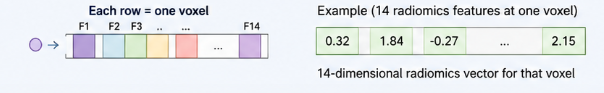

In [10]:
import numpy as np


def maps_to_voxels(maps):
    """
    Convert stacked GLDM feature maps into a voxel feature matrix.

    Parameters
    ----------
    maps : ndarray
        Shape = (F, Z, Y, X)

    Returns
    -------
    voxels : ndarray
        Shape = (N, F)

    volume_shape : tuple
        Original (Z, Y, X) shape for reconstruction.

    n_voxels : int
        Total number of voxels.
    """

    if maps.ndim != 4:
        raise ValueError(
            f"Expected 4D array (F,Z,Y,X), got {maps.shape}"
        )

    F, Z, Y, X = maps.shape

    # (F,Z,Y,X) --> (Z,Y,X,F)
    maps = np.transpose(maps, (1, 2, 3, 0))

    # (Z,Y,X,F) --> (N,F)
    voxels = maps.reshape(-1, F)

    print("===================================")
    print("Voxel matrix created")
    print(f"Feature maps : {F}")
    print(f"Volume shape : ({Z}, {Y}, {X})")
    print(f"Total voxels : {voxels.shape[0]:,}")
    print(f"Matrix shape : {voxels.shape}")
    print("===================================")

    return voxels.astype(np.float32), (Z, Y, X), voxels.shape[0]

In [1039]:
#TMH TEST
X_tmh_test = build_voxel_matrix(
    tmh_test_patients
)

print(
    X_tmh_test.shape,
    X_tmh_test.nbytes/1024**3
)

Voxel matrix created
Feature maps : 14
Volume shape : (39, 60, 46)
Total voxels : 107,640
Matrix shape : (107640, 14)
Voxel matrix created
Feature maps : 14
Volume shape : (84, 66, 63)
Total voxels : 349,272
Matrix shape : (349272, 14)
Voxel matrix created
Feature maps : 14
Volume shape : (42, 46, 44)
Total voxels : 85,008
Matrix shape : (85008, 14)
Voxel matrix created
Feature maps : 14
Volume shape : (52, 39, 41)
Total voxels : 83,148
Matrix shape : (83148, 14)
Voxel matrix created
Feature maps : 14
Volume shape : (64, 43, 56)
Total voxels : 154,112
Matrix shape : (154112, 14)
Voxel matrix created
Feature maps : 14
Volume shape : (64, 43, 50)
Total voxels : 137,600
Matrix shape : (137600, 14)
Voxel matrix created
Feature maps : 14
Volume shape : (52, 47, 45)
Total voxels : 109,980
Matrix shape : (109980, 14)
Voxel matrix created
Feature maps : 14
Volume shape : (78, 54, 56)
Total voxels : 235,872
Matrix shape : (235872, 14)
Voxel matrix created
Feature maps : 14
Volume shape : (105, 

In [1056]:
#TMH TEST RAw
X_tmh_test_raw = build_voxel_matrix(
    tmh_test_patients
)

print(
    X_tmh_test.shape,
    X_tmh_test.nbytes/1024**3
)

Voxel matrix created
Feature maps : 10
Volume shape : (39, 60, 46)
Total voxels : 107,640
Matrix shape : (107640, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (84, 66, 63)
Total voxels : 349,272
Matrix shape : (349272, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (42, 46, 44)
Total voxels : 85,008
Matrix shape : (85008, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (52, 39, 41)
Total voxels : 83,148
Matrix shape : (83148, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (64, 43, 56)
Total voxels : 154,112
Matrix shape : (154112, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (64, 43, 50)
Total voxels : 137,600
Matrix shape : (137600, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (52, 47, 45)
Total voxels : 109,980
Matrix shape : (109980, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (78, 54, 56)
Total voxels : 235,872
Matrix shape : (235872, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (105, 

In [1038]:
X_tmh_test

array([[-2.7959719 , -1.5526915 , -0.789277  , ..., -1.3197649 ,
        -0.81245035, -0.4522547 ],
       [-2.7959719 , -1.5526915 , -0.789277  , ..., -1.3197649 ,
        -0.81245035, -0.4522547 ],
       [-2.7959719 , -1.5526915 , -0.789277  , ..., -1.3197649 ,
        -0.81245035, -0.4522547 ],
       ...,
       [-2.7959719 , -1.5526915 , -0.789277  , ..., -1.3197649 ,
        -0.81245035, -0.4522547 ],
       [-2.7959719 , -1.5526915 , -0.789277  , ..., -1.3197649 ,
        -0.81245035, -0.4522547 ],
       [-2.7959719 , -1.5526915 , -0.789277  , ..., -1.3197649 ,
        -0.81245035, -0.4522547 ]], dtype=float32)

In [1040]:
X_tmh_test

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], dtype=float32)

In [312]:
X_tmh_test.shape

(8804043, 10)

In [18]:
#TMH TRAIN
X_tmh_train = build_voxel_matrix(
    tmh_train_patients
)

print(
    X_tmh_train.shape,
    X_tmh_train.nbytes/1024**3
)

Voxel matrix created
Feature maps : 10
Volume shape : (69, 61, 57)
Total voxels : 239,913
Matrix shape : (239913, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (47, 50, 44)
Total voxels : 103,400
Matrix shape : (103400, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (73, 63, 73)
Total voxels : 335,727
Matrix shape : (335727, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (67, 75, 70)
Total voxels : 351,750
Matrix shape : (351750, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (77, 59, 63)
Total voxels : 286,209
Matrix shape : (286209, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (65, 86, 64)
Total voxels : 357,760
Matrix shape : (357760, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (57, 51, 50)
Total voxels : 145,350
Matrix shape : (145350, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (74, 67, 40)
Total voxels : 198,320
Matrix shape : (198320, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (6

In [1010]:
import glob
import os

for f in feature_names_14:
    missing = [
        p for p in tmh_train_patients
        if len(glob.glob(f"{p}/*{f}.nrrd")) == 0
    ]
    print(f"{f}: missing in {len(missing)} patients")

DependenceEntropy: missing in 0 patients
DependenceNonUniformity: missing in 0 patients
DependenceVariance: missing in 0 patients
HighGrayLevelEmphasis: missing in 0 patients
LargeDependenceEmphasis: missing in 0 patients
LargeDependenceHighGrayLevelEmphasis: missing in 0 patients
LargeDependenceLowGrayLevelEmphasis: missing in 0 patients
LowGrayLevelEmphasis: missing in 0 patients
SmallDependenceEmphasis: missing in 0 patients
SmallDependenceHighGrayLevelEmphasis: missing in 0 patients
SmallDependenceLowGrayLevelEmphasis: missing in 0 patients
DependenceNonUniformityNormalized: missing in 0 patients
GrayLevelNonUniformity: missing in 0 patients
GrayLevelNonUniformityNormalized: missing in 117 patients


In [1016]:
#TMH TRAIN 14 
X_tmh_train_14 = build_voxel_matrix(
    tmh_train_patients
)

print(
    X_tmh_train_14.shape,
    X_tmh_train_14.nbytes/1024**3
)

Voxel matrix created
Feature maps : 14
Volume shape : (69, 61, 57)
Total voxels : 239,913
Matrix shape : (239913, 14)
Voxel matrix created
Feature maps : 14
Volume shape : (47, 50, 44)
Total voxels : 103,400
Matrix shape : (103400, 14)
Voxel matrix created
Feature maps : 14
Volume shape : (73, 63, 73)
Total voxels : 335,727
Matrix shape : (335727, 14)
Voxel matrix created
Feature maps : 14
Volume shape : (67, 75, 70)
Total voxels : 351,750
Matrix shape : (351750, 14)
Voxel matrix created
Feature maps : 14
Volume shape : (77, 59, 63)
Total voxels : 286,209
Matrix shape : (286209, 14)
Voxel matrix created
Feature maps : 14
Volume shape : (65, 86, 64)
Total voxels : 357,760
Matrix shape : (357760, 14)
Voxel matrix created
Feature maps : 14
Volume shape : (57, 51, 50)
Total voxels : 145,350
Matrix shape : (145350, 14)
Voxel matrix created
Feature maps : 14
Volume shape : (74, 67, 40)
Total voxels : 198,320
Matrix shape : (198320, 14)
Voxel matrix created
Feature maps : 14
Volume shape : (6

In [19]:
#LUNG1 TRAIN
X_lung_train = build_voxel_matrix(
    lung1_train_patients
)

print(
    X_lung_train.shape,
    X_lung_train.nbytes/1024**3
)

Voxel matrix created
Feature maps : 10
Volume shape : (54, 65, 69)
Total voxels : 242,190
Matrix shape : (242190, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (62, 70, 71)
Total voxels : 308,140
Matrix shape : (308140, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (48, 57, 44)
Total voxels : 120,384
Matrix shape : (120384, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (77, 57, 51)
Total voxels : 223,839
Matrix shape : (223839, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (59, 69, 50)
Total voxels : 203,550
Matrix shape : (203550, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (58, 55, 55)
Total voxels : 175,450
Matrix shape : (175450, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (38, 40, 38)
Total voxels : 57,760
Matrix shape : (57760, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (46, 44, 48)
Total voxels : 97,152
Matrix shape : (97152, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (56, 7

In [966]:
#LUNG1 TEST
X_lung_test_raw = build_voxel_matrix(
    lung1_test_patients
)

print(
    X_lung_test_raw.shape,
    X_lung_test_raw.nbytes/1024**3
)

Voxel matrix created
Feature maps : 10
Volume shape : (44, 56, 50)
Total voxels : 123,200
Matrix shape : (123200, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (38, 40, 48)
Total voxels : 72,960
Matrix shape : (72960, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (46, 71, 41)
Total voxels : 133,906
Matrix shape : (133906, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (62, 41, 56)
Total voxels : 142,352
Matrix shape : (142352, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (61, 63, 59)
Total voxels : 226,737
Matrix shape : (226737, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (41, 60, 52)
Total voxels : 127,920
Matrix shape : (127920, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (51, 68, 65)
Total voxels : 225,420
Matrix shape : (225420, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (48, 52, 58)
Total voxels : 144,768
Matrix shape : (144768, 10)
Voxel matrix created
Feature maps : 10
Volume shape : (35,

In [969]:
del X_lung_test_scaled_tmh

In [23]:
# Save everything immediately

# Otherwise reconstruction takes time.

np.save(
    "X_tmh_train.npy",
    X_tmh_train
)

np.save(
    "X_tmh_test.npy",
    X_tmh_test
)

np.save(
    "X_lung_train.npy",
    X_lung_train
)

np.save(
    "X_lung_test.npy",
    X_lung_test
)

In [ ]:
# labels for visualization

In [24]:
X_all = np.vstack([

    X_tmh_train,
    X_tmh_test,
    X_lung_train,
    X_lung_test
])

y = np.array(

    ["TMH_TRAIN"]*len(X_tmh_train)

    +

    ["TMH_TEST"]*len(X_tmh_test)

    +

    ["LUNG1_TRAIN"]*len(X_lung_train)

    +

    ["LUNG1_TEST"]*len(X_lung_test)

)

In [25]:
X_all.shape

(81233684, 10)

In [16]:
#Sample before PCA/UMAP.
n = 500000

idx = np.random.choice(
    len(X_all),
    n,
    replace=False
)

X_plot = X_all[idx]

y_plot = y[idx]

NameError: name 'X_all' is not defined

In [15]:
from sklearn.decomposition import PCA

pca = PCA(2)

emb = pca.fit_transform(
    X_plot
)

NameError: name 'X_plot' is not defined

In [20]:
#pip install cuml-cu12

In [36]:
#from cuml.manifold import UMAP

In [1033]:
### the voxel matrices.

print(
    X_tmh_train.shape,
    X_tmh_test.shape,
    X_lung_train.shape,
    X_lung_test.shape
)

(21252318, 10) (8804043, 10) (35771520, 10) (15405803, 10)


In [22]:
# from cuml.manifold import UMAP

# reducer = UMAP(

#     n_neighbors=30,
#     min_dist=0.1
# )

# emb = reducer.fit_transform(
#     X_pca
# )

In [48]:
#! pip install --upgrade "numba>=0.60,<0.62"

In [825]:
# short umap
N = 1000000
def sample_vox(X, n=N):

    idx = np.random.choice(

        len(X),

        min(n,len(X)),

        replace=False
    )

    return X[idx]


X_plot = np.vstack([

    sample_vox(X_tmh_train),
    sample_vox(X_tmh_test),
    sample_vox(X_lung_train),
    sample_vox(X_lung_test)

])

print(X_plot.shape)

(4000000, 10)


In [826]:
y_plot = np.array(

    ["TMH_TRAIN"]*N
    +
    ["TMH_TEST"]*N
    +
    ["LUNG1_TRAIN"]*N
    +
    ["LUNG1_TEST"]*N
)

In [827]:
from sklearn.decomposition import PCA

pca = PCA(
    n_components=10,
    random_state=88
)

X_pca = pca.fit_transform(
    X_plot
)

print(X_pca.shape)

(4000000, 10)


In [25]:
import sys
import numpy as np

print("Python :", sys.version)
print("NumPy  :", np.__version__)

try:
    import numba
    print("Numba  :", numba.__version__)
except Exception as e:
    print("Numba error:", e)

try:
    import cuml
    print("cuML   :", cuml.__version__)
except Exception as e:
    print("cuML error:", e)

Python : 3.12.3 (main, Feb  4 2025, 14:48:35) [GCC 13.3.0]
NumPy  : 1.26.4
Numba  : 0.61.2
cuML   : 25.04.00


In [829]:
from cuml.manifold import UMAP

reducer = UMAP(

    n_neighbors=30,
    min_dist=0.1
)

emb = reducer.fit_transform(
    X_pca
)

In [27]:
import numpy as np
import numba

print(np.__version__)
print(numba.__version__)

1.26.4
0.61.2


In [104]:
 # pip install seaborn ,matplotlib


In [39]:
###  Cohort overlap check

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt


In [45]:
! pip install ipympl

In [992]:
emb[:,0]

array([ 1.4764633,  4.022791 , 38.064613 , ..., -2.1066785,  6.075796 ,
        7.667115 ], dtype=float32)

/tmp/ipykernel_2379577/1053331626.py:30: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/tmp/ipykernel_2379577/1053331626.py:31: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


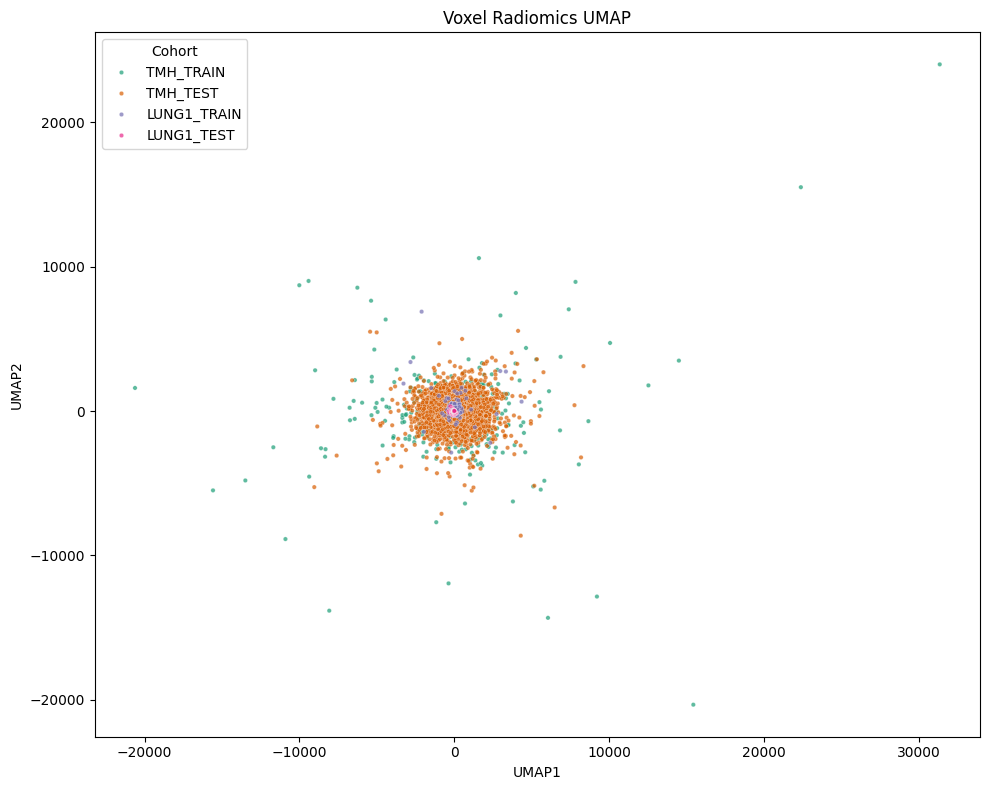

In [830]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

df_plot = pd.DataFrame({

    "UMAP1": emb[:,0],
    "UMAP2": emb[:,1],
    "Cohort": y_plot

})

plt.figure(figsize=(10,8))

sns.scatterplot(

    data=df_plot,

    x="UMAP1",
    y="UMAP2",

    hue="Cohort",

    palette="Dark2",   # darker colors
    s=10,               # slightly larger points
    alpha=0.7          # darker / less transparent
)

plt.title("Voxel Radiomics UMAP")
plt.tight_layout()
plt.savefig(
    "umap_voxel_raw_1M_1ft_dropped.png",
    dpi=300,
    bbox_inches='tight'
)
plt.show()

/tmp/ipykernel_2379577/2861725702.py:26: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


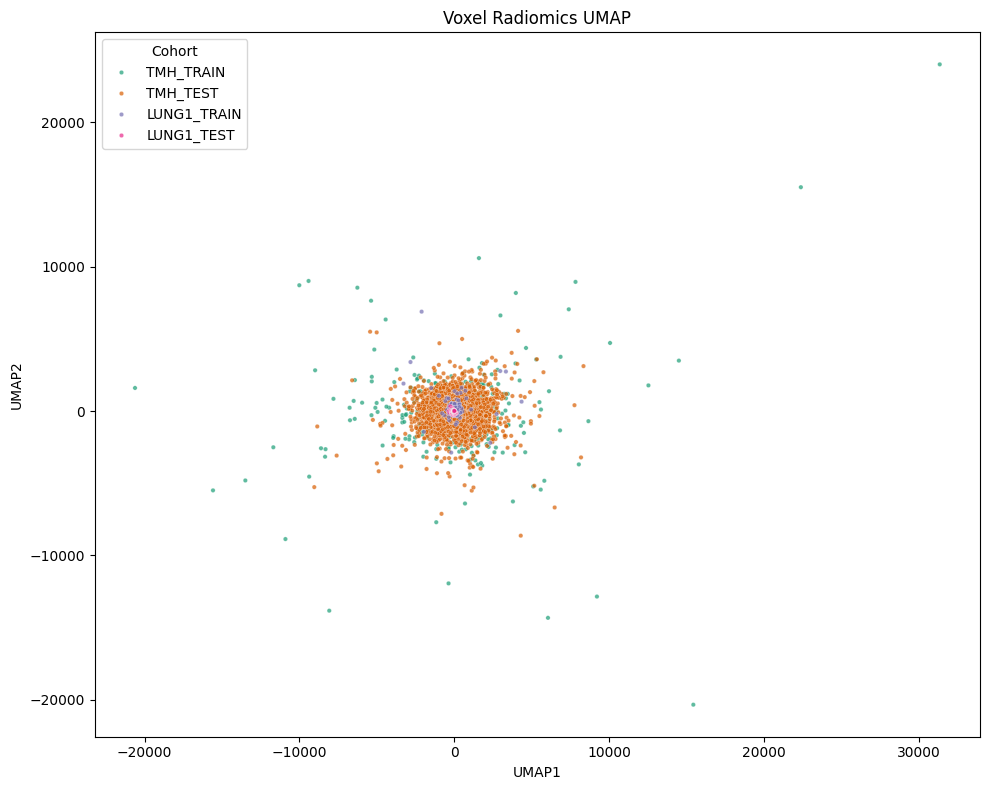

In [993]:

df_plot = pd.DataFrame({

    "UMAP1": emb[:,0],
    "UMAP2": emb[:,1],
    "Cohort": y_plot

})

plt.figure(figsize=(10,8))

sns.scatterplot(

    data=df_plot,

    x="UMAP1",
    y="UMAP2",

    hue="Cohort",

    palette="Dark2",   # darker colors
    s=10,               # slightly larger points
    alpha=0.7          # darker / less transparent
)

plt.title("Voxel Radiomics UMAP")
plt.tight_layout()
# plt.savefig(
#     "umap_voxel_raw_1M_1ft_dropped.png",
#     dpi=300,
#     bbox_inches='tight'
# )
plt.show()

/tmp/ipykernel_2196710/1053331626.py:30: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/tmp/ipykernel_2196710/1053331626.py:31: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


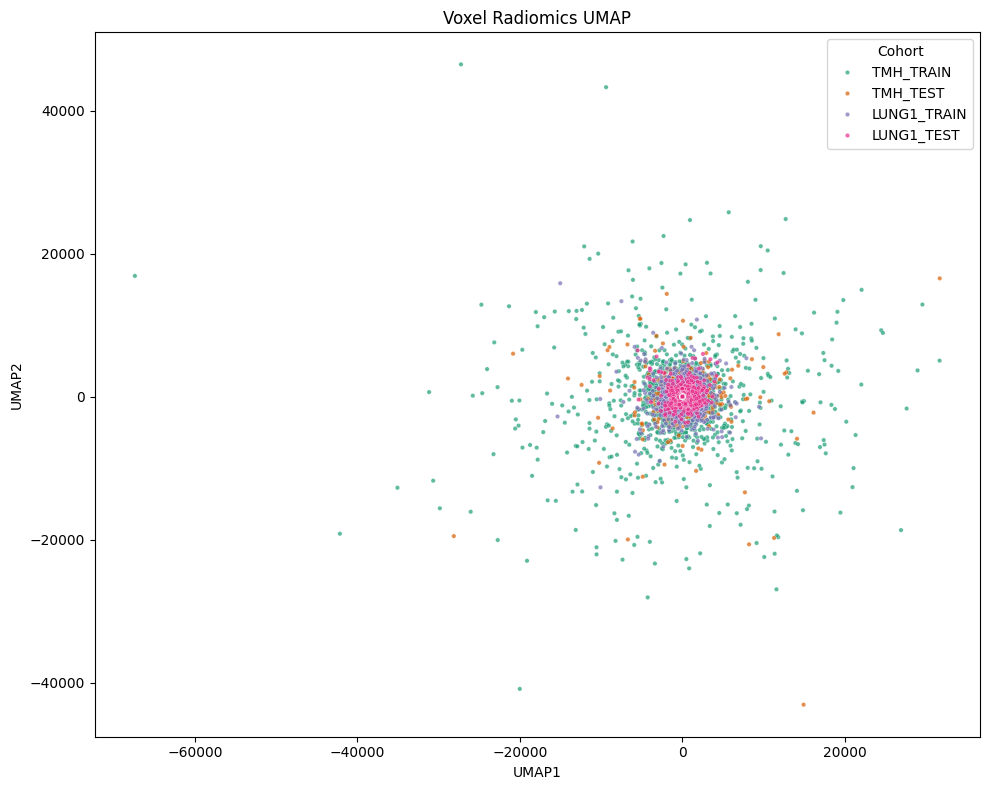

In [ ]:
# older plot 

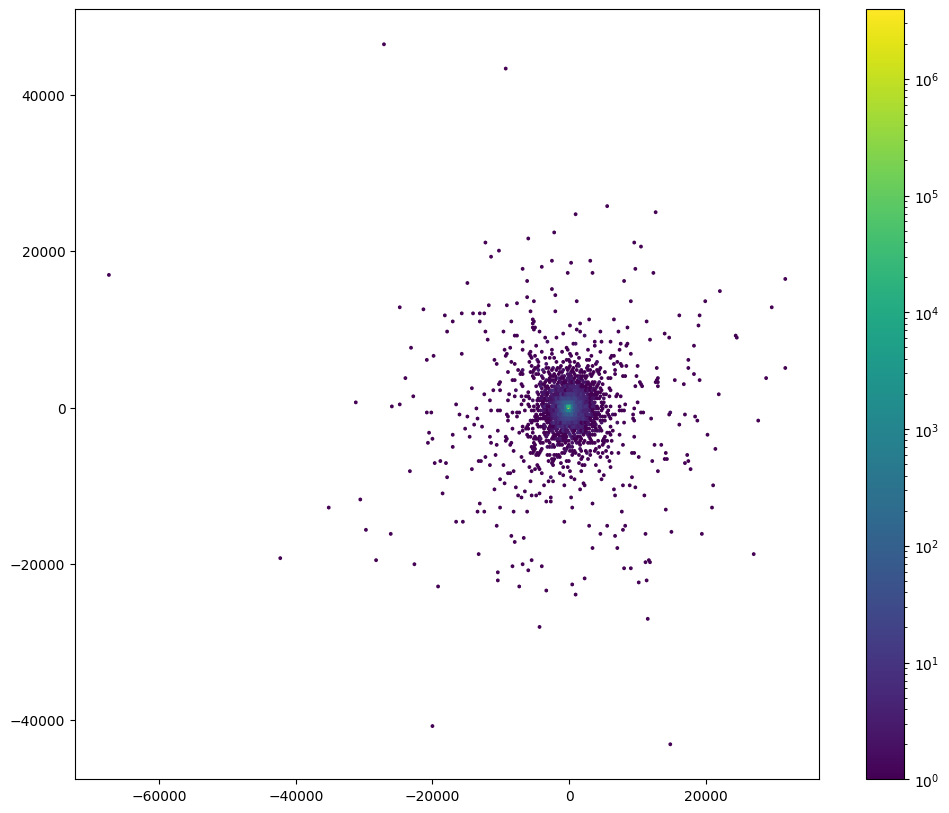

In [120]:
plt.figure(figsize=(12,10))

plt.hexbin(

    emb[:,0],
    emb[:,1],

    gridsize=300,
    bins='log'
)

plt.colorbar()

TypeError: 'tuple' object is not callable

<Axes: >

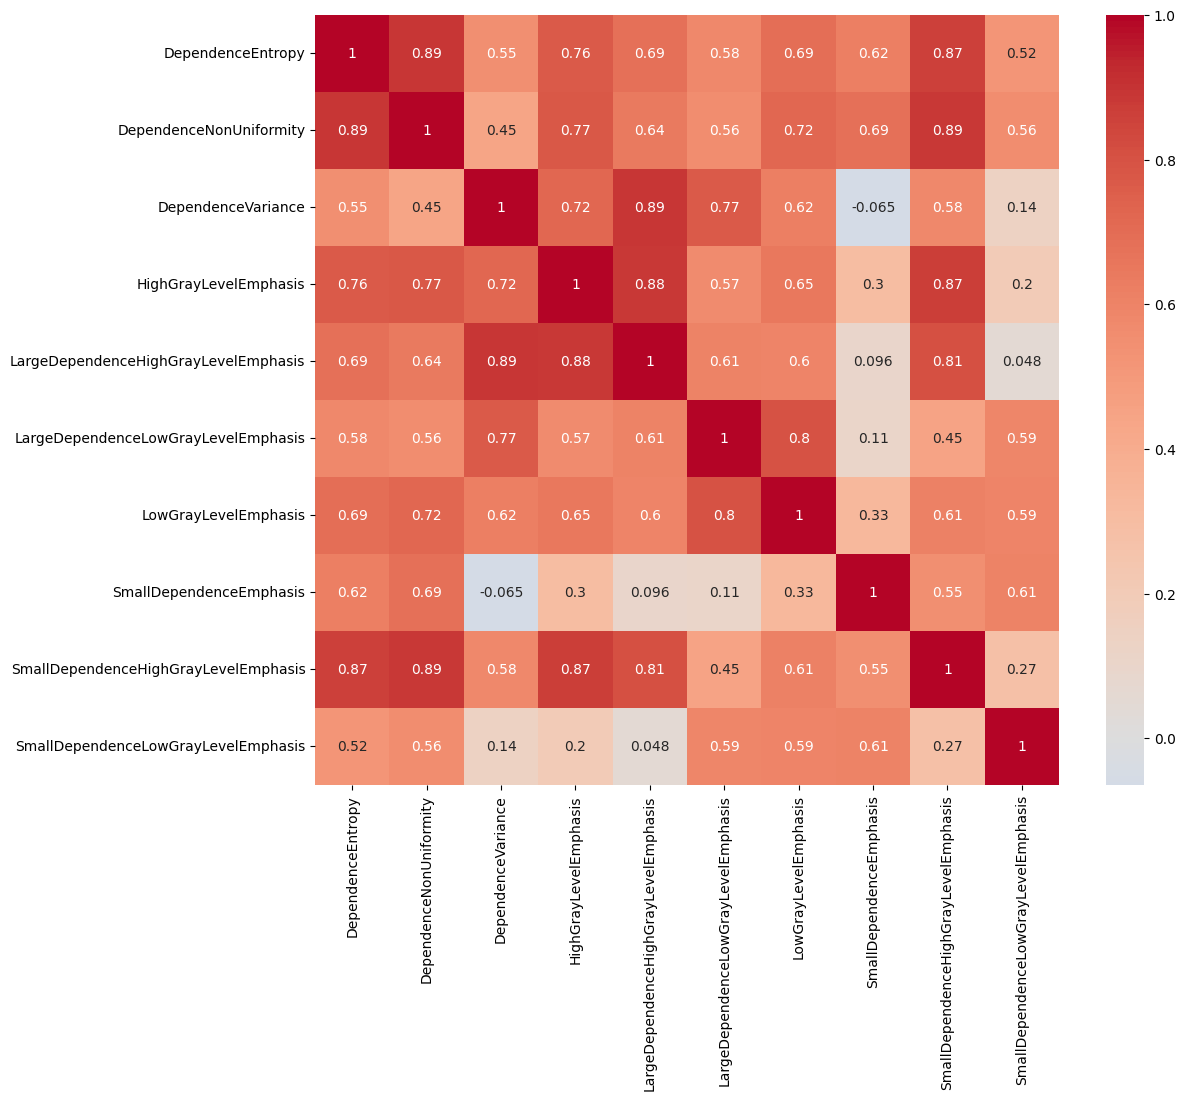

In [831]:
corr = pd.DataFrame(
    X_plot,
    columns=FEATURES
).corr("spearman")

plt.figure(figsize=(12,10))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,annot=True
)

<Axes: >

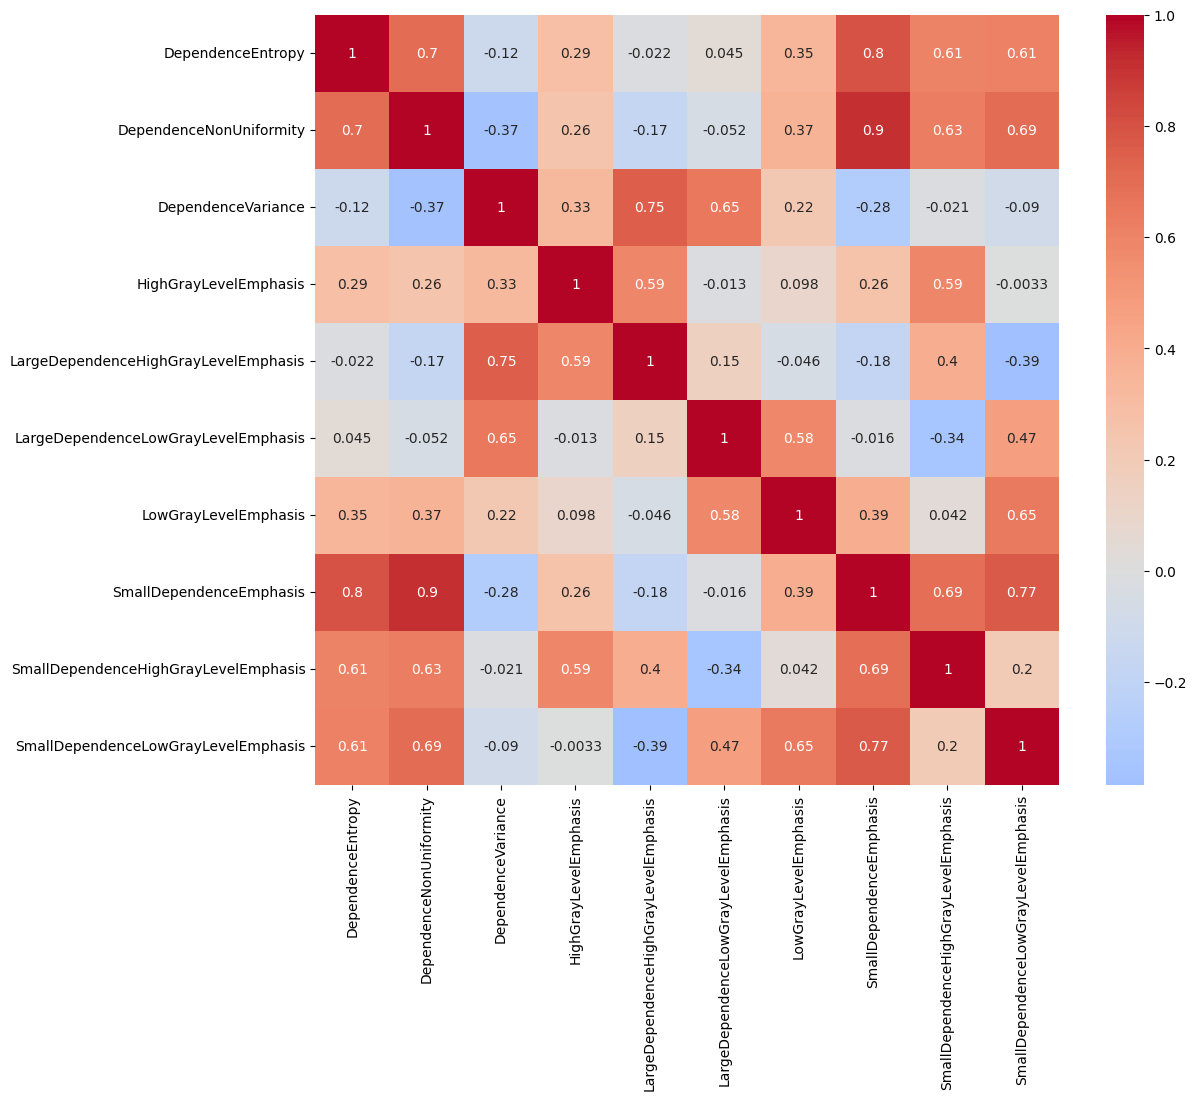

In [ ]:
#

<Axes: >

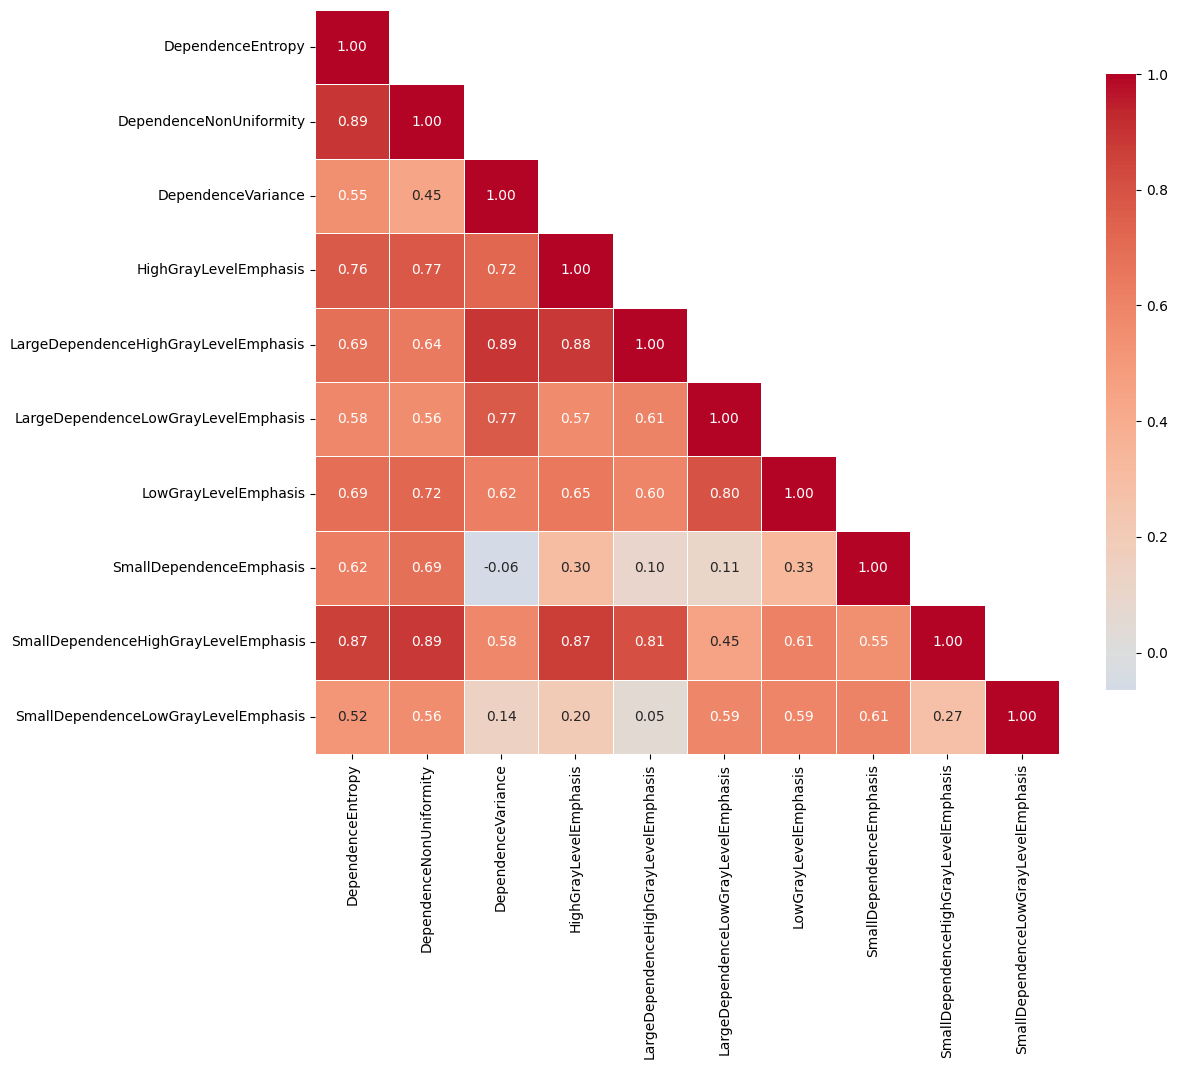

In [996]:
import numpy as np

# 1. Set the figure size
plt.figure(figsize=(12, 10))

# 2. Generate the upper triangle mask (k=1 keeps the diagonal visible)
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

# 3. Plot the masked heatmap
sns.heatmap(
    corr,
    mask=mask,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",  # Limits annotations to 2 decimal places for neatness
    square=True,  # Forces cells to be perfectly square
    linewidths=0.5,  # Adds clean spacing lines between cells
    cbar_kws={"shrink": 0.8},  # Shrinks color bar to match layout
)

<Axes: >

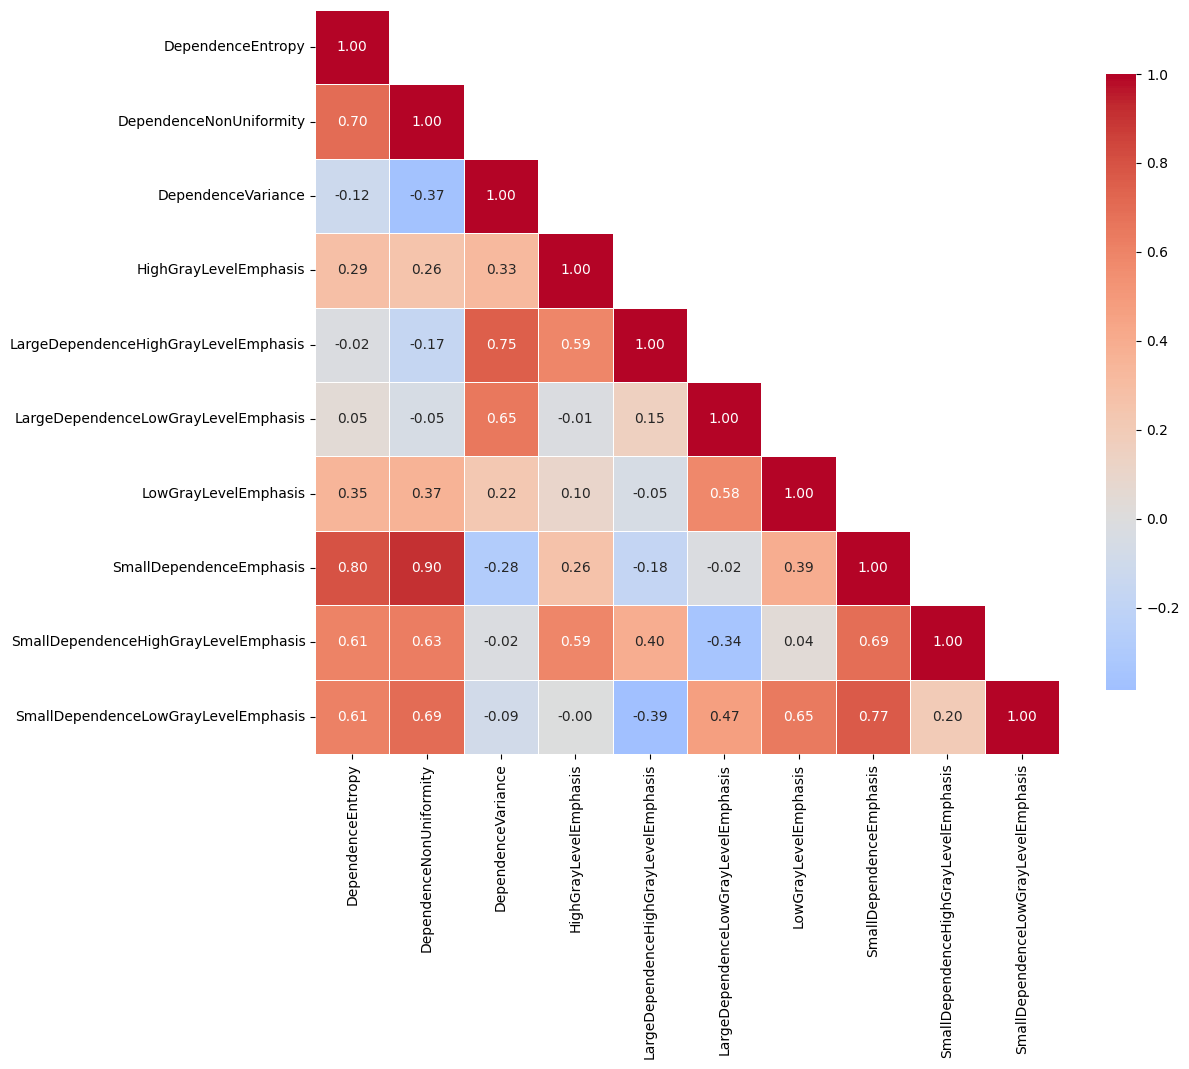

In [ ]:
# old

In [1014]:
feature_names_14 = [
    "DependenceEntropy",
    "DependenceNonUniformity",
    "DependenceVariance",
    "HighGrayLevelEmphasis",
    "LargeDependenceEmphasis",
    "LargeDependenceHighGrayLevelEmphasis",
    "LargeDependenceLowGrayLevelEmphasis",
    "LowGrayLevelEmphasis",
    "SmallDependenceEmphasis",
    "SmallDependenceHighGrayLevelEmphasis",
    "SmallDependenceLowGrayLevelEmphasis",
    "DependenceNonUniformityNormalized",
    "GrayLevelNonUniformity",
    "GrayLevelVariance"
]

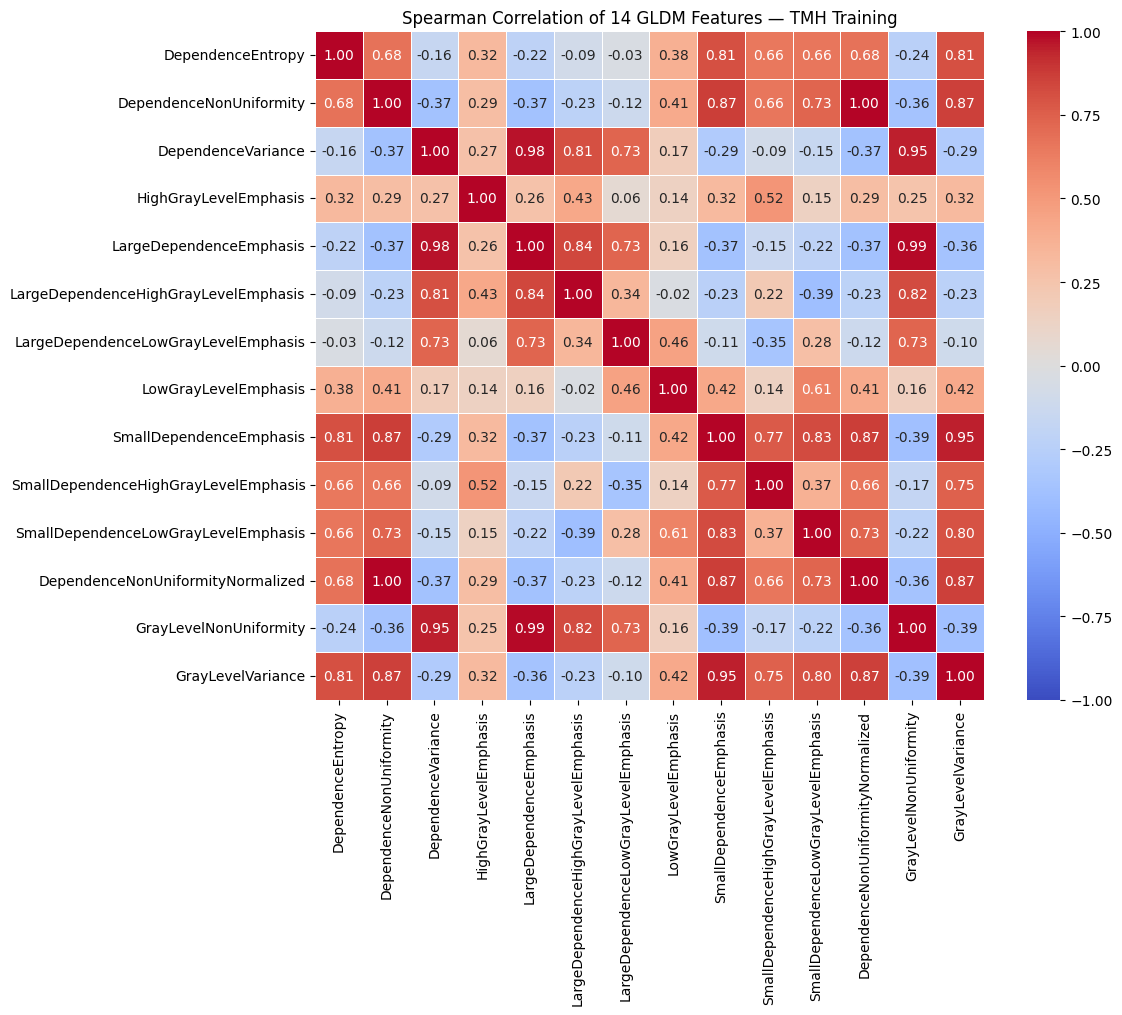

In [1018]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

corr_14 = pd.DataFrame(
    X_tmh_train_14,
    columns=feature_names_14
).corr(method="spearman")

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_14,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)

plt.title("Spearman Correlation of 14 GLDM Features — TMH Training")
plt.tight_layout()
plt.show()

In [1019]:
feature_names

['DependenceEntropy',
 'DependenceNonUniformity',
 'DependenceVariance',
 'HighGrayLevelEmphasis',
 'LargeDependenceHighGrayLevelEmphasis',
 'LargeDependenceLowGrayLevelEmphasis',
 'LowGrayLevelEmphasis',
 'SmallDependenceEmphasis',
 'SmallDependenceHighGrayLevelEmphasis',
 'SmallDependenceLowGrayLevelEmphasis']

In [1021]:
high_corr = (
    corr_14.where(
        (abs(corr_14) > 0.9) & (abs(corr_14) < 1)
    )
    .stack()
    .sort_values(key=abs, ascending=False)
)

print(high_corr)

LargeDependenceEmphasis  GrayLevelNonUniformity     0.986703
GrayLevelNonUniformity   LargeDependenceEmphasis    0.986703
DependenceVariance       LargeDependenceEmphasis    0.976424
LargeDependenceEmphasis  DependenceVariance         0.976424
SmallDependenceEmphasis  GrayLevelVariance          0.949246
GrayLevelVariance        SmallDependenceEmphasis    0.949246
DependenceVariance       GrayLevelNonUniformity     0.948069
GrayLevelNonUniformity   DependenceVariance         0.948069
dtype: float64


In [1020]:
high_corr

NameError: name 'high_corr' is not defined

In [1017]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

corr = pd.DataFrame(
    X_tmh_train_scaled,
    columns=feature_names_14
).corr(method="spearman")

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True)
plt.title("Spearman Correlation of 14 GLDM Features — TMH Training")
plt.tight_layout()
plt.show()

ValueError: Shape of passed values is (21252318, 10), indices imply (21252318, 14)

In [32]:
# old plot

In [22]:
# check variance importance
import pandas as pd
s = pd.Series(
    X_tmh_train.var(axis=0),
    index=FEATURES
).sort_values()

print(s.to_string(float_format="{:.10f}".format))

SmallDependenceLowGrayLevelEmphasis             0.0000045539
SmallDependenceEmphasis                         0.0502173044
DependenceEntropy                               1.4694442749
LowGrayLevelEmphasis                            1.9868409634
LargeDependenceLowGrayLevelEmphasis             3.8207547665
DependenceNonUniformity                        14.6094207764
DependenceVariance                             42.0776786804
SmallDependenceHighGrayLevelEmphasis       268530.2187500000
HighGrayLevelEmphasis                  1975540608.0000000000
LargeDependenceHighGrayLevelEmphasis   5091275776.0000000000


In [63]:
X_train_all = np.concatenate(
    [X_tmh_train, X_lung_train],
    axis=0
)

variance = X_train_all.var(axis=0)

su=pd.Series(
    variance,
    index=FEATURES
).sort_values()

print(su.to_string(float_format="{:.10f}".format))

SmallDependenceLowGrayLevelEmphasis             0.0000056061
SmallDependenceEmphasis                         0.0513069555
LowGrayLevelEmphasis                            0.7701075673
DependenceEntropy                               1.5188251734
LargeDependenceLowGrayLevelEmphasis             1.6468232870
DependenceNonUniformity                        15.6953754425
DependenceVariance                             26.9735469818
SmallDependenceHighGrayLevelEmphasis       262461.7500000000
HighGrayLevelEmphasis                  1077403520.0000000000
LargeDependenceHighGrayLevelEmphasis   2934778112.0000000000


In [64]:
# # after dropping go to # short UMAP cell
# DROP = [
#     "DependenceNonUniformityNormalized"
# ]

# keep_idx = [

#     i for i,f in enumerate(FEATURES)

#     if f not in DROP
# ]

# X_tmh_train = X_tmh_train[:, keep_idx]
# X_tmh_test = X_tmh_test[:, keep_idx]
# X_lung_train = X_lung_train[:, keep_idx]
# X_lung_test = X_lung_test[:, keep_idx]

# FEATURES = [
#     FEATURES[i]
#     for i in keep_idx
# ]

### STEP 2 — Train Autoencoder

In [ ]:
### 1. Build AE Training Matrix


In [26]:
X_ae_raw = np.concatenate([

    X_tmh_train,
    X_lung_train

], axis=0)

print(X_ae_raw.shape)

(57023838, 10)


In [1034]:
# tmh model

### TMH model: TMH_train → TMH StandardScaler → TMH AE → TMH SOM → LUNG1_test

X_tmh_train





array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], dtype=float32)

In [315]:
# scale tmh


z_scaler_tmh = StandardScaler()

X_tmh_train_scaled = z_scaler_tmh.fit_transform(
    X_tmh_train
).astype(np.float32)

joblib.dump(
    z_scaler_tmh,
    "tmh_standard_scaler_10features.pkl"
)

print("Saved tmh_standard_scaler_10features.pkl")









Saved tmh_standard_scaler_10features.pkl


In [832]:
print("NaN:", np.isnan(X_tmh_train_scaled).sum())
print("Inf:", np.isinf(X_tmh_train_scaled).sum())
print(X_tmh_train_scaled.shape)

NaN: 0
Inf: 0
(21252318, 10)


In [ ]:
ae is X_tmh_train_scaled

In [294]:
# change to z scaling

In [27]:
from sklearn.preprocessing import StandardScaler
import joblib
import numpy as np

z_scaler = StandardScaler()

X_ae = z_scaler.fit_transform(
    X_ae_raw
).astype(np.float32)

joblib.dump(
    z_scaler,
    "standard_scaler_10features.pkl"
)

print("Saved standard_scaler_10features.pkl")

Saved standard_scaler_10features.pkl


In [833]:
print("NaN:", np.isnan(X_ae).sum())
print("Inf:", np.isinf(X_ae).sum())

print("\nMean:")
print(X_ae.mean(axis=0))

print("\nStd:")
print(X_ae.std(axis=0))

print("\nMax abs:")
print(np.max(np.abs(X_ae), axis=0))

NaN: 0
Inf: 0

Mean:
[-3.1339689e-09  2.0768967e-08 -2.2533965e-07  2.1406892e-08
 -6.6100199e-08  4.2886565e-08  4.7962141e-09  5.0677606e-08
 -5.1804676e-09 -4.9148081e-08]

Std:
[0.9999999  1.0000002  1.         0.99999887 1.0000004  1.0000012
 0.9999988  0.99999994 0.9999999  0.99999917]

Max abs:
[ 2.7959719  5.2624946  4.8206635 17.222603  10.312588  79.21398
 51.78789    3.0950418 30.034521  67.43267  ]


In [835]:
for f, x in zip(
    FEATURES,
    X_ae.T
):
    print(
        f"{f:45s}"
        f" p99={np.percentile(np.abs(x),99):.3f}"
        f" p99.9={np.percentile(np.abs(x),99.9):.3f}"
        f" max={np.max(np.abs(x)):.3f}"
    )

DependenceEntropy                             p99=2.796 p99.9=2.796 max=2.796
DependenceNonUniformity                       p99=2.907 p99.9=4.328 max=5.262
DependenceVariance                            p99=3.855 p99.9=4.325 max=4.821
HighGrayLevelEmphasis                         p99=4.774 p99.9=10.076 max=17.223
LargeDependenceHighGrayLevelEmphasis          p99=4.335 p99.9=6.507 max=10.313
LargeDependenceLowGrayLevelEmphasis           p99=1.518 p99.9=14.880 max=79.214
LowGrayLevelEmphasis                          p99=0.331 p99.9=9.139 max=51.788
SmallDependenceEmphasis                       p99=2.359 p99.9=2.850 max=3.095
SmallDependenceHighGrayLevelEmphasis          p99=3.995 p99.9=6.554 max=30.035
SmallDependenceLowGrayLevelEmphasis           p99=3.571 p99.9=10.292 max=67.433


In [834]:
X_ae.shape

(57023838, 10)

In [301]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = AE().to(device)

x = torch.tensor(
    X_ae[:1024],
    dtype=torch.float32,
    device=device
)

model.eval()

with torch.no_grad():

    out, z = model(x)

    loss = (
        0.5 * F.l1_loss(out, x)
        +
        0.5 * F.mse_loss(out, x)
    )

print("Input finite :", torch.isfinite(x).all().item())
print("Output finite:", torch.isfinite(out).all().item())
print("Latent finite:", torch.isfinite(z).all().item())
print("Loss:", loss.item())

Input finite : True
Output finite: True
Latent finite: True
Loss: 1.1802457571029663


In [318]:
### tmh sanity check

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = AE().to(device)

x = torch.tensor(
    X_tmh_train_scaled[:1024],
    dtype=torch.float32,
    device=device
)

model.eval()

with torch.no_grad():

    out, z = model(x)

    loss = (
        0.5 * F.l1_loss(out, x)
        +
        0.5 * F.mse_loss(out, x)
    )

print("Input finite :", torch.isfinite(x).all().item())
print("Output finite:", torch.isfinite(out).all().item())
print("Latent finite:", torch.isfinite(z).all().item())
print("Loss:", loss.item())

Input finite : True
Output finite: True
Latent finite: True
Loss: 1.0597236156463623


In [297]:
# from sklearn.preprocessing import RobustScaler, StandardScaler
# scaler = RobustScaler()

# X_ae_scaled = scaler.fit_transform(
#     X_ae
# ).astype(np.float32)

In [313]:
X_ae.shape

(57023838, 10)

In [29]:
X_ae

array([[-2.7959719 , -1.5526915 , -0.789277  , ..., -1.3197649 ,
        -0.81245035, -0.4522547 ],
       [-2.7959719 , -1.5526915 , -0.789277  , ..., -1.3197649 ,
        -0.81245035, -0.4522547 ],
       [-2.7959719 , -1.5526915 , -0.789277  , ..., -1.3197649 ,
        -0.81245035, -0.4522547 ],
       ...,
       [-2.7959719 , -1.5526915 , -0.789277  , ..., -1.3197649 ,
        -0.81245035, -0.4522547 ],
       [-2.7959719 , -1.5526915 , -0.789277  , ..., -1.3197649 ,
        -0.81245035, -0.4522547 ],
       [-2.7959719 , -1.5526915 , -0.789277  , ..., -1.3197649 ,
        -0.81245035, -0.4522547 ]], dtype=float32)

In [78]:
# idx = FEATURES.index("HighGrayLevelEmphasis")

# print("Training raw median:",
#       np.median(X_tmh_train[:, idx]))

# print("Scaler center:",
#       scaler.center_[idx])

# print("Scaler scale:",
#       scaler.scale_[idx])

# print("Training transformed median:",
#       np.median(
#           scaler.transform(
#               X_tmh_train[:100000, :]
#           )[:, idx]
#       ))

In [225]:
### 2. Z Scaling

In [30]:
# Scaling the test cohorts:

z_scaler = joblib.load(
    "standard_scaler_10features.pkl"
)

X_tmh_test = z_scaler.transform(
    X_tmh_test
).astype(np.float32)

X_lung_test = z_scaler.transform(
    X_lung_test
).astype(np.float32)

In [31]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torch.utils.data import Dataset, DataLoader
import torch

print(torch.__version__)
print(torch.cuda.is_available())
print(torch.cuda.device_count())
print(torch.cuda.get_device_name(0))

2.8.0a0+5228986c39.nv25.06
True
1
NVIDIA A100-SXM4-80GB


In [32]:
class VoxDataset(Dataset):

    def __init__(self, x):

        self.x = x

    def __len__(self):

        return len(self.x)

    def __getitem__(self, i):

        return torch.from_numpy(
            self.x[i]
        ).float()

In [33]:
### 5. Autoencoder

class AE(nn.Module):

    def __init__(self):

        super().__init__()

        self.enc = nn.Sequential(

            nn.Linear(10, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 8)
        )

        self.dec = nn.Sequential(

            nn.Linear(8, 16),
            nn.ReLU(),

            nn.Linear(16, 32),
            nn.ReLU(),

            nn.Linear(32, 64),
            nn.ReLU(),

            nn.Linear(64, 10)
        )

    def forward(self, x):

        z = self.enc(x)

        out = self.dec(z)

        return out, z



In [34]:
# ds_tmh = VoxDataset(X_ae)

In [320]:
ds_tmh = VoxDataset(X_tmh_train_scaled)

In [ ]:
X_tmh_train_scaled

In [ ]:
### 4. TMH DataLoader

loader_tmh = DataLoader(

    ds_tmh,

    batch_size=131072,

    shuffle=True,

    num_workers=8,

    pin_memory=True,

    persistent_workers=False
)

# 6 GPU
device = "cuda"

model = AE().to(device)

opt = torch.optim.Adam(

    model.parameters(),

    lr=1e-4,

    weight_decay=1e-5
)

In [179]:
# # 7 Training 

# #Training
# losses = []

# for epoch in range(100):

#     running = 0

#     model.train()

#     for x in loader:

#         x = x.to(
#             device,
#             non_blocking=True
#         )

#         out,z = model(x)

#         loss = (

#             0.5*F.l1_loss(out,x)

#             +

#             0.5*F.mse_loss(out,x)

#         )

#         opt.zero_grad()

#         loss.backward()

#         opt.step()

#         running += loss.item()

#     running /= len(loader)

#     losses.append(running)

#     print(
#         epoch,
#         running
#     )


In [45]:
# ### 7. Training
# from tqdm.auto import tqdm
# import time
# import numpy as np

# losses = []

# total_start = time.time()

# for epoch in range(100):

#     model.train()

#     running = 0.0
#     batch_losses = []

#     epoch_start = time.time()

#     pbar = tqdm(
#         loader,
#         desc=f"Epoch {epoch+1:03d}/100",
#         leave=True
#     )
#     # 1. Wrapped tqdm in a context manager ('with') to avoid notebook crashes
#     # with tqdm(loader, desc=f"Epoch {epoch+1:03d}/100", leave=True) as pbar:
#     for i, x in enumerate(pbar):

#         x = x.to(
#             device,
#             non_blocking=True
#         )

#         out, z = model(x)

#         loss = (
#             0.5 * F.l1_loss(out, x)
#             +
#             0.5 * F.mse_loss(out, x)
#         )

#         opt.zero_grad()

#         loss.backward()

#         opt.step()

#         loss_val = loss.item()

#         running += loss_val
#         batch_losses.append(loss_val)

#         if torch.cuda.is_available():

#             gpu_mem = (
#                 torch.cuda.memory_allocated()
#                 / 1024**3
#             )

#         else:
#             gpu_mem = 0

#         pbar.set_postfix({

#             "loss":
#                 f"{loss_val:.5f}",

#             "avg":
#                 f"{np.mean(batch_losses):.5f}",

#             "gpu":
#                 f"{gpu_mem:.1f}GB"
#         })

#     epoch_loss = running / len(loader)

#     losses.append(epoch_loss)

#     epoch_time = (
#         time.time()
#         - epoch_start
#     )

#     total_elapsed = (
#         time.time()
#         - total_start
#     )

#     avg_epoch_time = (
#         total_elapsed
#         / (epoch + 1)
#     )

#     eta = (
#         avg_epoch_time
#         * (100 - epoch - 1)
#     )

#     print("\n" + "="*80)

#     print(
#         f"Epoch {epoch+1:03d}/100"
#     )

#     print(
#         f"Loss      : {epoch_loss:.6f}"
#     )

#     print(
#         f"Epoch Time: {epoch_time/60:.2f} min"
#     )

#     print(
#         f"Elapsed   : {total_elapsed/3600:.2f} hr"
#     )

#     print(
#         f"ETA       : {eta/3600:.2f} hr"
#     )

#     if torch.cuda.is_available():

#         print(
#             f"GPU Mem   : "
#             f"{torch.cuda.max_memory_allocated()/1024**3:.2f} GB"
#         )

#     print("="*80)

In [ ]:
# final training

In [38]:
z_scaler

StandardScaler()

In [44]:
print("X_ae shape:", X_ae.shape)

print("NaN:", np.isnan(X_ae).sum())
print("Inf:", np.isinf(X_ae).sum())

print("\nMax abs per feature:")
for f, v in zip(FEATURES, np.max(np.abs(X_ae), axis=0)):
    print(f"{f:45s} {v:.6g}")

print("\nScaler scale:")
for f, v in zip(FEATURES, z_scaler.scale_):
    print(f"{f:45s} {v:.8g}")

X_ae shape: (57023838, 10)
NaN: 0
Inf: 0

Max abs per feature:
DependenceEntropy                             2.79597
DependenceNonUniformity                       5.26249
DependenceVariance                            4.82066
HighGrayLevelEmphasis                         17.2226
LargeDependenceHighGrayLevelEmphasis          10.3126
LargeDependenceLowGrayLevelEmphasis           79.214
LowGrayLevelEmphasis                          51.7879
SmallDependenceEmphasis                       3.09504
SmallDependenceHighGrayLevelEmphasis          30.0345
SmallDependenceLowGrayLevelEmphasis           67.4327

Scaler scale:
DependenceEntropy                             1.2324064
DependenceNonUniformity                       3.9617407
DependenceVariance                            5.1936028
HighGrayLevelEmphasis                         32823.829
LargeDependenceHighGrayLevelEmphasis          54173.551
LargeDependenceLowGrayLevelEmphasis           1.2832846
LowGrayLevelEmphasis                          0

In [324]:
from tqdm import tqdm
import time
import numpy as np
import torch
import torch.nn.functional as F

amp_scaler = torch.cuda.amp.GradScaler()
losses = []

N_EPOCHS = 100
SAVE_EVERY = 25


total_start = time.time()

for epoch in range(N_EPOCHS):

    model.train()

    running = 0.0
    batch_losses = []

    epoch_start = time.time()

    pbar = tqdm(
        loader_tmh, # here is the data in coming
        desc=f"Epoch {epoch+1:03d}/{N_EPOCHS}",
        leave=True
    )

    for i, x in enumerate(pbar): # x is the data getting trained

        x = x.to(
            device,
            non_blocking=True
        )

        ##################################################
        # Forward
        ##################################################

        with torch.cuda.amp.autocast():

            out, z = model(x)

            loss = (

                0.5 * F.l1_loss(out, x)

                +

                0.5 * F.mse_loss(out, x)

            )

        ##################################################
        # NaN check
        ##################################################

        if torch.isnan(loss):

            print("NaN detected!")

            break

        ##################################################
        # Backward
        ##################################################

        opt.zero_grad()

        amp_scaler.scale(loss).backward()

        amp_scaler.step(opt)

        amp_scaler.update()

        ##################################################
        # Logging
        ##################################################

        loss_val = loss.item()

        running += loss_val
        batch_losses.append(loss_val)

        gpu_mem = (
            torch.cuda.memory_allocated()
            / 1024**3
        )

        pbar.set_postfix({

            "loss":
                f"{loss_val:.5f}",

            "avg":
                f"{np.mean(batch_losses):.5f}",

            "gpu":
                f"{gpu_mem:.1f}GB"
        })

    ##################################################
    # Epoch Summary
    ##################################################

    epoch_loss = running / len(loader)

    losses.append(epoch_loss)

    epoch_time = (
        time.time()
        - epoch_start
    )

    total_elapsed = (
        time.time()
        - total_start
    )

    avg_epoch_time = (
        total_elapsed
        / (epoch + 1)
    )

    eta = (
        avg_epoch_time
        * (N_EPOCHS - epoch - 1)
    )

    vox_per_sec = (
        len(loader.dataset)
        / epoch_time
    )

    print("\n" + "="*90)

    print(
        f"Epoch       : {epoch+1}/{N_EPOCHS}"
    )

    print(
        f"Loss         : {epoch_loss:.6f}"
    )

    print(
        f"LR           : "
        f"{opt.param_groups[0]['lr']:.2e}"
    )

    print(
        f"Epoch Time   : "
        f"{epoch_time/60:.2f} min"
    )

    print(
        f"Elapsed Time : "
        f"{total_elapsed/3600:.2f} hr"
    )

    print(
        f"ETA          : "
        f"{eta/3600:.2f} hr"
    )

    print(
        f"Throughput   : "
        f"{vox_per_sec/1e6:.2f} M vox/sec"
    )

    print(
        f"GPU Memory   : "
        f"{torch.cuda.max_memory_allocated()/1024**3:.2f} GB"
    )

    print("="*90)

    ##################################################
    # Save checkpoint
    ##################################################

    if (epoch + 1) % SAVE_EVERY == 0:

        ckpt = {

            "epoch":
                epoch,

            "model":
                model.state_dict(),

            "optimizer":
                opt.state_dict(),

            "losses":
                losses
        }

        torch.save(

            ckpt,

            f"gb_tmh_ae_epoch_{epoch+1}.pth"
        )

        print(
            f"Checkpoint saved:"
            f" gb_tmh_ae_epoch_{epoch+1}.pth"
        )

    ##################################################
    # Clear cache
    ##################################################

    torch.cuda.empty_cache()

/tmp/ipykernel_2379577/663145133.py:7: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  amp_scaler = torch.cuda.amp.GradScaler()
Epoch 001/100:   0%|                                                                                                                         | 0/163 [00:00<?, ?it/s]/tmp/ipykernel_2379577/663145133.py:42: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Epoch 001/100: 100%|█████████████████████████████████████████████████████████████████████████| 163/163 [00:19<00:00,  8.32it/s, loss=0.78225, avg=0.78299, gpu=0.0GB]



Epoch       : 1/100
Loss         : 0.292725
LR           : 1.00e-04
Epoch Time   : 0.33 min
Elapsed Time : 0.01 hr
ETA          : 0.54 hr
Throughput   : 2.91 M vox/sec
GPU Memory   : 0.11 GB


Epoch 002/100: 100%|█████████████████████████████████████████████████████████████████████████| 163/163 [00:21<00:00,  7.73it/s, loss=0.54266, avg=0.66552, gpu=0.0GB]



Epoch       : 2/100
Loss         : 0.248807
LR           : 1.00e-04
Epoch Time   : 0.35 min
Elapsed Time : 0.01 hr
ETA          : 0.56 hr
Throughput   : 2.70 M vox/sec
GPU Memory   : 0.11 GB


Epoch 003/100: 100%|█████████████████████████████████████████████████████████████████████████| 163/163 [00:19<00:00,  8.54it/s, loss=0.41185, avg=0.48760, gpu=0.0GB]



Epoch       : 3/100
Loss         : 0.182289
LR           : 1.00e-04
Epoch Time   : 0.32 min
Elapsed Time : 0.02 hr
ETA          : 0.55 hr
Throughput   : 2.99 M vox/sec
GPU Memory   : 0.11 GB


... (190 outputs left out)

Epoch 099/100: 100%|█████████████████████████████████████████████████████████████████████████| 163/163 [00:21<00:00,  7.60it/s, loss=0.01630, avg=0.01638, gpu=0.0GB]



Epoch       : 99/100
Loss         : 0.006125
LR           : 1.00e-04
Epoch Time   : 0.36 min
Elapsed Time : 0.57 hr
ETA          : 0.01 hr
Throughput   : 2.66 M vox/sec
GPU Memory   : 0.11 GB


Epoch 100/100: 100%|█████████████████████████████████████████████████████████████████████████| 163/163 [00:21<00:00,  7.67it/s, loss=0.01635, avg=0.01627, gpu=0.0GB]


Epoch       : 100/100
Loss         : 0.006082
LR           : 1.00e-04
Epoch Time   : 0.35 min
Elapsed Time : 0.57 hr
ETA          : 0.00 hr
Throughput   : 2.68 M vox/sec
GPU Memory   : 0.11 GB
Checkpoint saved: gb_tmh_ae_epoch_100.pth


In [ ]:
    
# old train    

/tmp/ipykernel_2379577/783269207.py:7: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  amp_scaler = torch.cuda.amp.GradScaler()
Epoch 001/100:   0%|                                                                                                                         | 0/436 [00:00<?, ?it/s]/tmp/ipykernel_2379577/783269207.py:42: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Epoch 001/100: 100%|█████████████████████████████████████████████████████████████████████████| 436/436 [00:50<00:00,  8.65it/s, loss=0.02907, avg=0.03037, gpu=0.0GB]



Epoch       : 1/100
Loss         : 0.030375
LR           : 1.00e-04
Epoch Time   : 0.84 min
Elapsed Time : 0.01 hr
ETA          : 1.39 hr
Throughput   : 1.13 M vox/sec
GPU Memory   : 0.11 GB


Epoch 002/100: 100%|█████████████████████████████████████████████████████████████████████████| 436/436 [00:53<00:00,  8.19it/s, loss=0.02720, avg=0.02808, gpu=0.0GB]



Epoch       : 2/100
Loss         : 0.028083
LR           : 1.00e-04
Epoch Time   : 0.89 min
Elapsed Time : 0.03 hr
ETA          : 1.41 hr
Throughput   : 1.07 M vox/sec
GPU Memory   : 0.11 GB


Epoch 003/100: 100%|█████████████████████████████████████████████████████████████████████████| 436/436 [01:04<00:00,  6.72it/s, loss=0.02554, avg=0.02612, gpu=0.0GB]



Epoch       : 3/100
Loss         : 0.026115
LR           : 1.00e-04
Epoch Time   : 1.08 min
Elapsed Time : 0.05 hr
ETA          : 1.52 hr
Throughput   : 0.88 M vox/sec
GPU Memory   : 0.11 GB


... (190 outputs left out)

Epoch 099/100: 100%|█████████████████████████████████████████████████████████████████████████| 436/436 [00:50<00:00,  8.72it/s, loss=0.00781, avg=0.00779, gpu=0.0GB]



Epoch       : 99/100
Loss         : 0.007787
LR           : 1.00e-04
Epoch Time   : 0.83 min
Elapsed Time : 1.34 hr
ETA          : 0.01 hr
Throughput   : 1.14 M vox/sec
GPU Memory   : 0.11 GB


Epoch 100/100: 100%|█████████████████████████████████████████████████████████████████████████| 436/436 [00:48<00:00,  9.01it/s, loss=0.00759, avg=0.00769, gpu=0.0GB]



Epoch       : 100/100
Loss         : 0.007691
LR           : 1.00e-04
Epoch Time   : 0.81 min
Elapsed Time : 1.35 hr
ETA          : 0.00 hr
Throughput   : 1.18 M vox/sec
GPU Memory   : 0.11 GB
Checkpoint saved: ae_epoch_100.pth


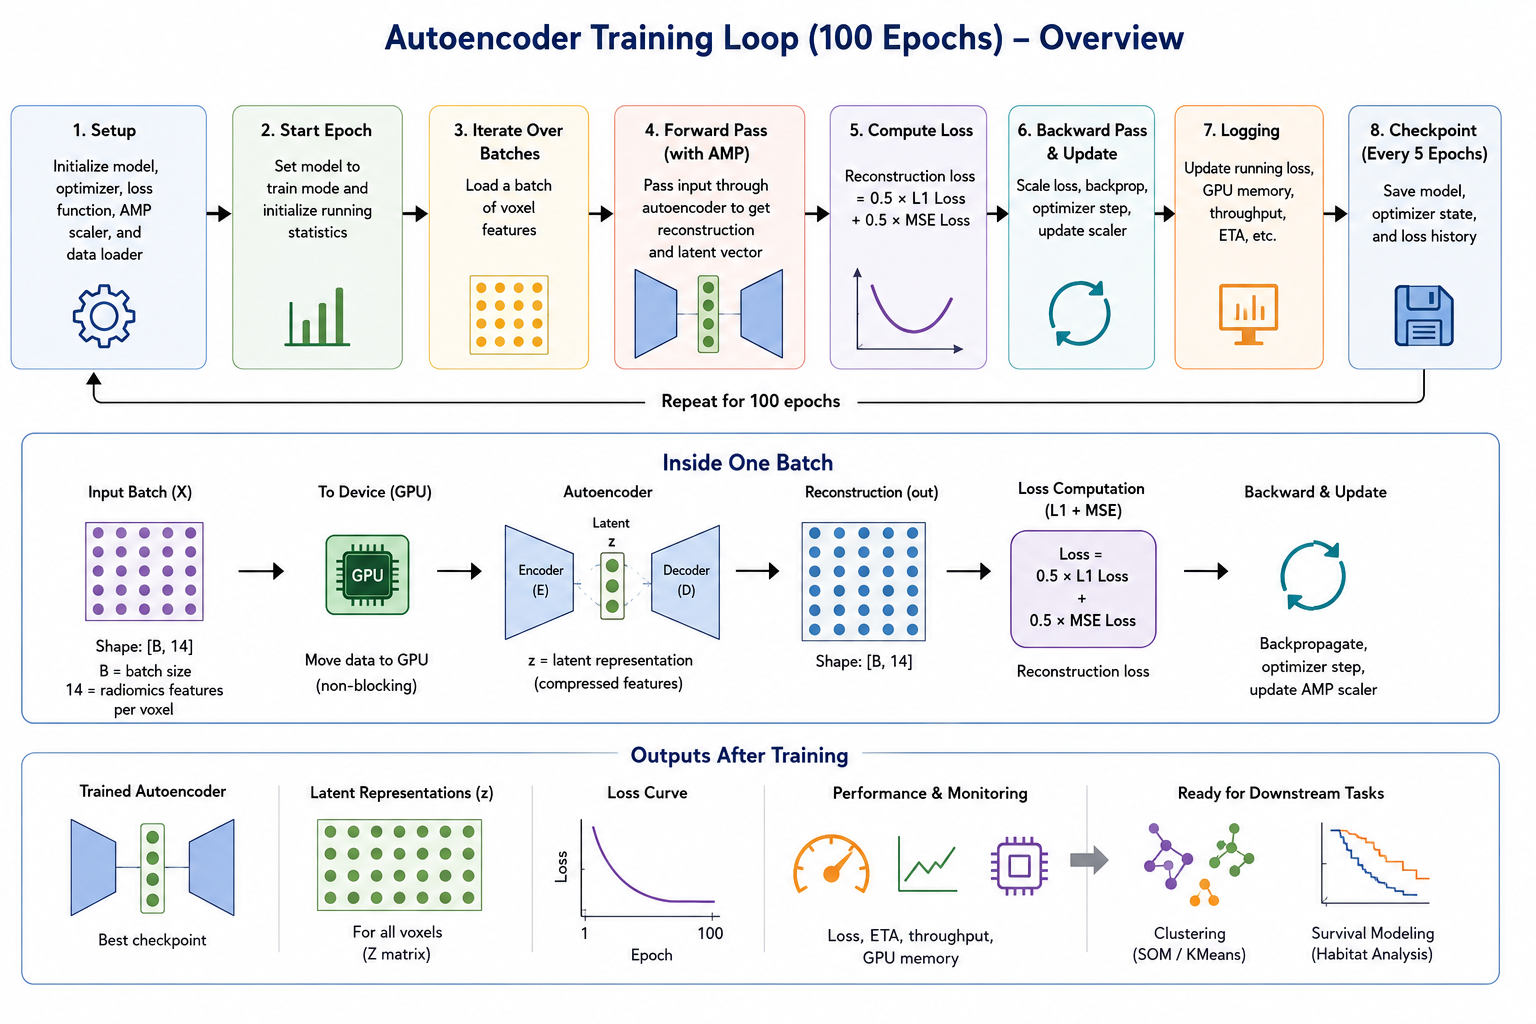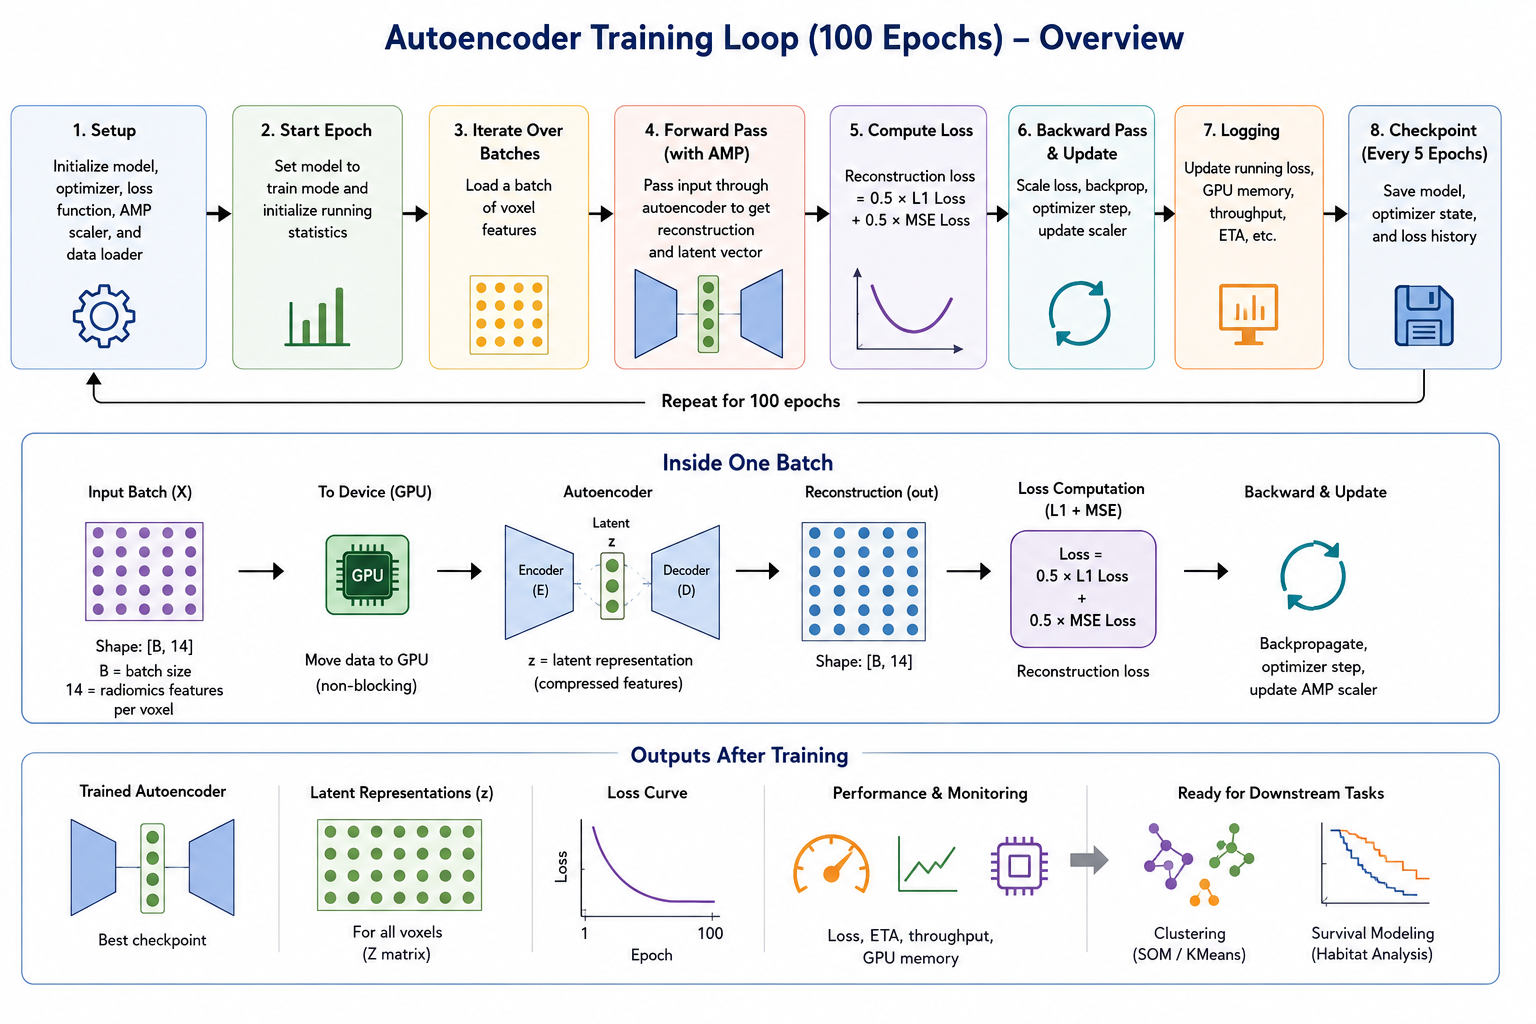

In [30]:
# import time
# import numpy as np
# import torch
# import torch.nn.functional as F
# from torch.amp import autocast, GradScaler
# from tqdm.auto import tqdm

# # ==========================================
# # EXTRACTION: Move entire dataset to GPU 
# # ==========================================
# print("Pre-loading entire dataset onto the A100 GPU to bypass CPU bottlenecks...")
# # Extracting underlying tensors from your dataset 'ds'
# # Adjust '.tensors[0]' if your dataset structure is custom (e.g., ds.data, ds.X)
# if hasattr(ds, 'tensors'):
#     X_all = ds.tensors[0].to(device, non_blocking=True)
#     print('standard')
# else:
#     # Fallback if it's a standard custom dataset: load via a quick single-worker loop
#     X_all = torch.cat([x.unsqueeze(0) if x.dim() == 0 else x for x in ds], dim=0).to(device)
#     print('non-standard fallback')
# dataset_size = X_all.size(0)
# batch_size = 131072
# num_batches = int(np.ceil(dataset_size / batch_size))

# # Initialize AMP GradScaler for A100 Tensor Cores acceleration
# scaler = GradScaler('cuda')

# losses = []
# total_start = time.time()

# print(f"Dataset ready on GPU. Total samples: {dataset_size} | Batches per epoch: {num_batches}")
# print("Starting accelerated training loop...\n")

# for epoch in range(100):
#     model.train()
#     running = 0.0
#     batch_losses = []
#     epoch_start = time.time()

#     # Create a random permutation directly on the GPU for blistering-fast shuffling
#     indices = torch.randperm(dataset_size, device=device)
#     X_shuffled = X_all[indices]

#     # Clean progress bar using context manager
#     with tqdm(range(num_batches), desc=f"Epoch {epoch+1:03d}/100", leave=True) as pbar:
#         for b_idx in pbar:
#             # Slicing directly in GPU memory (instantaneous)
#             start_i = b_idx * batch_size
#             end_i = min(start_i + batch_size, dataset_size)
#             x = X_shuffled[start_i:end_i]

#             opt.zero_grad(set_to_none=True) # More efficient than zero_grad()

#             # Forward pass wrapped in Automatic Mixed Precision (AMP)
#             with autocast('cuda', dtype=torch.bfloat16): 
#                 out, z = model(x)
#                 loss = 0.5 * F.l1_loss(out, x) + 0.5 * F.mse_loss(out, x)

#             # Scaled backward pass and optimization
#             scaler.scale(loss).backward()
#             scaler.step(opt)
#             scaler.update()

#             loss_val = loss.item()
#             running += loss_val
#             batch_losses.append(loss_val)

#             # Performance checking
#             gpu_mem = torch.cuda.memory_allocated() / 1024**3

#             pbar.set_postfix({
#                 "loss": f"{loss_val:.5f}",
#                 "avg": f"{np.mean(batch_losses):.5f}",
#                 "gpu": f"{gpu_mem:.1f}GB"
#             })

#     # Calculations for Metrics
#     epoch_loss = running / num_batches
#     losses.append(epoch_loss)

#     epoch_time = time.time() - epoch_start
#     total_elapsed = time.time() - total_start
#     avg_epoch_time = total_elapsed / (epoch + 1)
#     eta = avg_epoch_time * (100 - epoch - 1)

#     print("\n" + "="*80)
#     print(f"Epoch {epoch+1:03d}/100")
#     print(f"Loss      : {epoch_loss:.6f}")
#     print(f"Epoch Time: {epoch_time/60:.2f} min")
#     print(f"Elapsed   : {total_elapsed/3600:.2f} hr")
#     print(f"ETA       : {eta/3600:.2f} hr")
#     print(f"Max GPU   : {torch.cuda.max_memory_allocated()/1024**3:.2f} GB")


In [325]:
torch.save(

    model.state_dict(),

    "tmh_ae_final.pth"
)

In [230]:
torch.save(

    model.state_dict(),

    "ae_final.pth"
)

In [ ]:
# resume training , if crashed
ckpt = torch.load(
    "ae_epoch_20.pth"
)

model.load_state_dict(
    ckpt["model"]
)

opt.load_state_dict(
    ckpt["optimizer"]
)

losses = ckpt["losses"]

start_epoch = (
    ckpt["epoch"] + 1
)

In [ ]:
TMH_train → TMH scaler → TMH AE → TMH SOM → LUNG1_test

and separately:

LUNG1_train → LUNG1 scaler → LUNG1 AE → LUNG1 SOM → TMH_test

#### plottting

In [41]:
import matplotlib.pyplot as plt

In [38]:
del(plt)

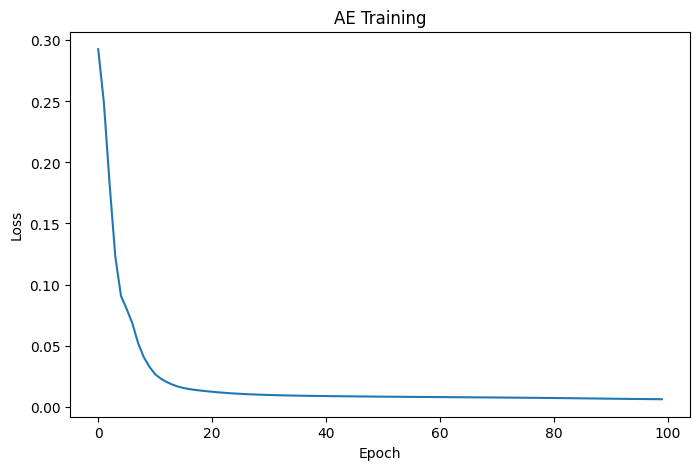

In [326]:
### 9. Plot Loss
plt.figure(figsize=(8,5))

plt.plot(losses)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title(
    "AE Training"
)

plt.show()

In [156]:
# 10. Save Model


### STEP 3 — Extract Latent

In [232]:
### from the econder , extract the latent representation z for every voxel,
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
import numpy as np
import torch


class VoxDataset(Dataset):

    def __init__(self, X):
        self.X = X.astype(np.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx]


def get_latent(model, X, batch_size=131072):

    ds = VoxDataset(X)

    loader = DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=False
    )

    model.eval()

    z_all = []

    with torch.no_grad():

        for x in tqdm(loader):

            x = x.cuda(non_blocking=True)

            z = model.enc(x)

            z_all.append(
                z.cpu().numpy()
            )

    return np.vstack(z_all)

In [327]:
X_tmh_train.shape

(21252318, 10)

In [332]:
# TMH TEST → use TMH scaler
X_tmh_test_scaled = z_scaler_tmh.transform(
    X_tmh_test
).astype(np.float32)

In [333]:
X_tmh_test_scaled.shape

(8804043, 10)

In [331]:
Z_tmh_train = get_latent(
    model,
    X_tmh_train_scaled
)

print(Z_tmh_train.shape)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 163/163 [01:44<00:00,  1.56it/s]


(21252318, 8)


In [334]:
Z_tmh_test = get_latent(
    model,
    X_tmh_test_scaled
)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 68/68 [00:38<00:00,  1.76it/s]


In [972]:
# LUNG1 TEST → TMH-trained pipeline
X_lung_test_scaled_tmh = z_scaler_tmh.transform(
    X_lung_test_raw
).astype(np.float32)

In [ ]:
Z_lung_test = get_latent(
    model,
    X_lung_test_scaled_tmh
)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 118/118 [01:09<00:00,  1.69it/s]


In [336]:
# Z_tmh_train = get_latent(
#     model,
#     X_tmh_train
# )

# Z_tmh_test = get_latent(
#     model,
#     X_tmh_test
# )

# Z_lung_train = get_latent(
#     model,
#     X_lung_train
# )

# Z_lung_test = get_latent(
#     model,
#     X_lung_test
# )

In [330]:
del(Z_tmh_train)

In [135]:
# latent extraction
# or extract latents  using checkpointed model 
model = AE().cuda()
model.load_state_dict(
    #torch.load("ae_epoch_100.pth")
    torch.load("ae_final.pth")
)

Z_tmh_train = get_latent(
    model,
    X_tmh_train
)

Z_tmh_test = get_latent(
    model,
    X_tmh_test
)

Z_lung_train = get_latent(
    model,
    X_lung_train
)

Z_lung_test = get_latent(
    model,
    X_lung_test
)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 118/118 [00:23<00:00,  5.00it/s]


In [244]:
# save latents
np.save(
    "Z_tmh_train_latents.npy",
    Z_tmh_train
)

np.save(
    "Z_lung_train_latents.npy",
    Z_lung_train
)

In [245]:
np.save(
    "Z_tmh_test_latents.npy",
    Z_tmh_test
)

np.save(
    "Z_lung_test_latents.npy",
    Z_lung_test
)

In [234]:
import numpy as np 

import seaborn as sns

def sample_vox(X, n=250000):
    """
    Randomly sample voxels from a large matrix.

    Parameters
    ----------
    X : np.ndarray
        Shape = (N_voxels, n_features)

    n : int
        Number of voxels to sample

    Returns
    -------
    np.ndarray
    """

    n = min(n, X.shape[0])

    idx = np.random.choice(
        X.shape[0],
        n,
        replace=False
    )

    return X[idx]

In [235]:
def latent_umap(
        Z1,
        Z2,
        label1="TMH",
        label2="LUNG1",
        n=250000):

    X1 = sample_vox(Z1, n)
    X2 = sample_vox(Z2, n)

    X = np.vstack([X1, X2])

    labels = np.array(
        [label1]*len(X1) +
        [label2]*len(X2)
    )

    print("PCA...")

    X_pca = PCA(
        n_components=min(
            8,
            X.shape[1]
        ),
        random_state=42
    ).fit_transform(X)

    print("UMAP...")

    emb = UMAP(
        n_neighbors=30,
        min_dist=0.1,
        metric="euclidean",
        random_state=42,
        verbose=True
    ).fit_transform(X_pca)

    plt.figure(figsize=(10,8))

    sns.scatterplot(
        x=emb[:,0],
        y=emb[:,1],
        hue=labels,
        s=4,
        alpha=0.5,
        palette="Dark2"
    )

    plt.title(
        "Latent Space UMAP"
    )

    plt.tight_layout()

    plt.show()

    return emb, labels

In [53]:
from sklearn.decomposition import PCA
emb, labels = latent_umap(
    Z_tmh_train,
    Z_lung_train,
    n=500000
)

PCA...
UMAP...


NameError: name 'UMAP' is not defined

PCA...
UMAP...
[2026-08-08 06:25:07.754] [CUML] [info] build_algo set to brute_force_knn because random_state is given
[2026-08-08 06:25:08.046] [CUML] [debug] Computing KNN Graph
[2026-08-08 06:25:14.408] [CUML] [debug] Computing fuzzy simplicial set


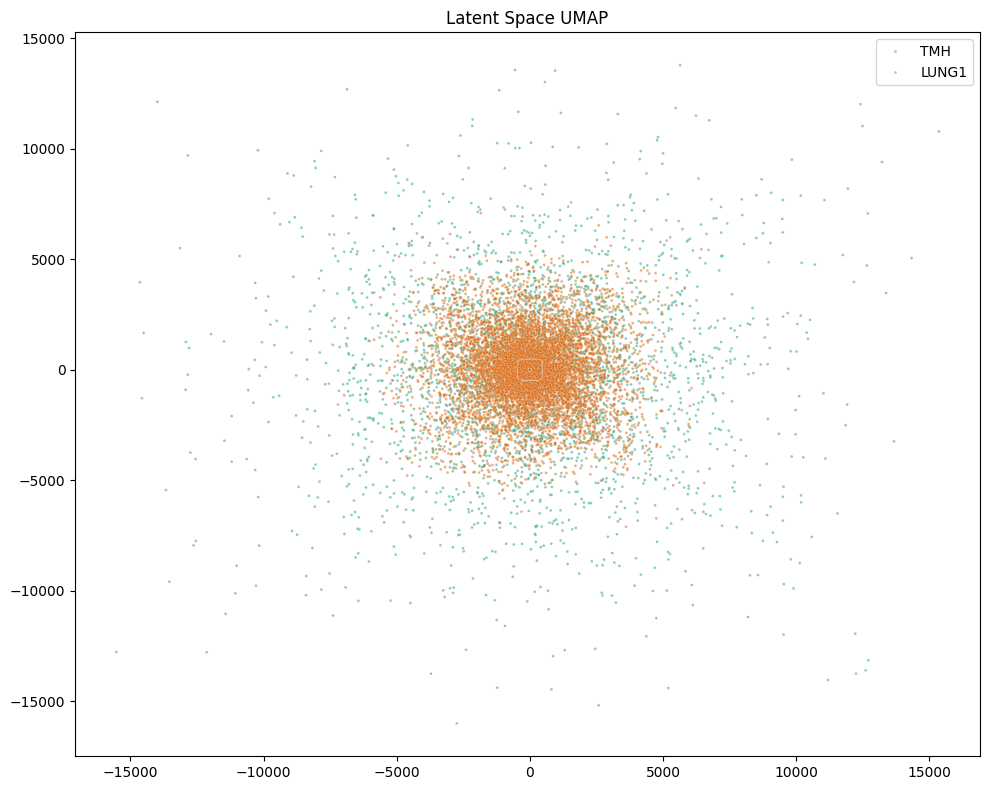

In [ ]:
# old

In [67]:
plt.savefig(
    "latent_umap.png",
    dpi=600,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [55]:
# combine both latents


latent_sample = np.vstack([

    sample_vox(Z_tmh_train, 500000),

    sample_vox(Z_lung_train, 500000)

])

In [56]:
from sklearn.decomposition import PCA

pca = PCA()
pca.fit(latent_sample)

print(
    np.cumsum(
        pca.explained_variance_ratio_
    )
)

[0.957719   0.99997884 0.9999961  0.9999994  0.9999998  0.9999999
 0.9999999  0.9999999 ]


In [57]:
pca.explained_variance_ratio_

array([9.5771903e-01, 4.2259805e-02, 1.7294366e-05, 3.2754401e-06,
       4.4017949e-07, 3.8132210e-08, 0.0000000e+00, 0.0000000e+00],
      dtype=float32)

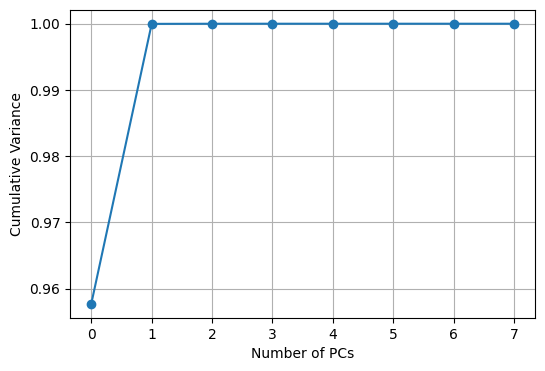

In [58]:
plt.figure(figsize=(6,4))

plt.plot(
    np.cumsum(
        pca.explained_variance_ratio_
    ),
    marker='o'
)

plt.xlabel("Number of PCs")
plt.ylabel("Cumulative Variance")
plt.grid()
plt.show()

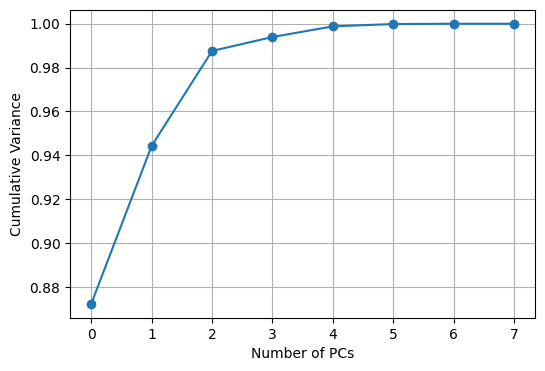

In [ ]:
# old

In [59]:
emb.shape

NameError: name 'emb' is not defined

In [112]:
latent_sample.shape

(1000000, 8)

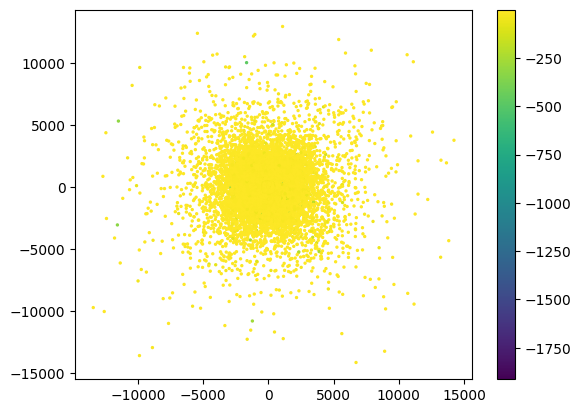

In [46]:
plt.scatter(
    emb[:,0],
    emb[:,1],
    c=latent_sample[:,0],
    s=2,
    cmap='viridis'
)
plt.colorbar()

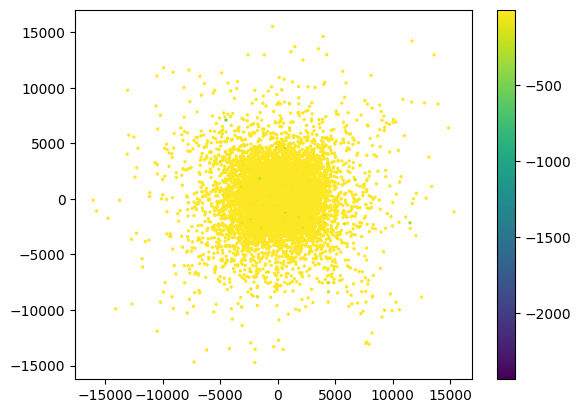

In [ ]:
# old

In [106]:
# check latent activity
print(latent_sample.std(axis=0))

# build xyz latent
X_som = np.concatenate(
    [
        latent,
        0.25*coords
    ],
    axis=1
)

# train SOM

NameError: name 'latent_sample' is not defined

In [84]:
latent_sample.std(axis=0)

array([35.514095, 11.41097 , 20.597273,  8.744742, 15.14077 , 34.010685,
        8.477785, 31.271162], dtype=float32)

In [54]:
vmin = np.percentile(
    latent_sample[:,0],
    1
)

vmax = np.percentile(
    latent_sample[:,0],
    99
)

plt.scatter(
    emb[:,0],
    emb[:,1],
    c=latent_sample[:,0],
    s=2,
    cmap="viridis",
    vmin=vmin,
    vmax=vmax
)
plt.colorbar()

NameError: name 'latent_sample' is not defined

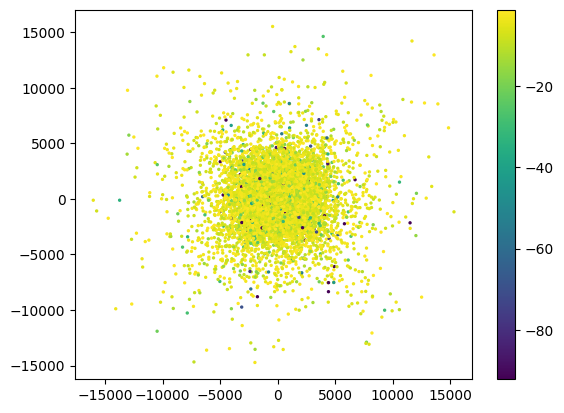

In [ ]:
# old

<Axes: >

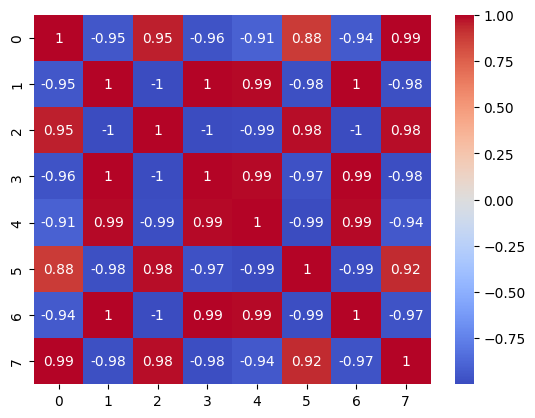

In [60]:
import seaborn as sns
import pandas as pd
sns.heatmap(
    pd.DataFrame(
        latent_sample
    ).corr(method='spearman'),
    annot=True,
    cmap='coolwarm'
)

<Axes: >

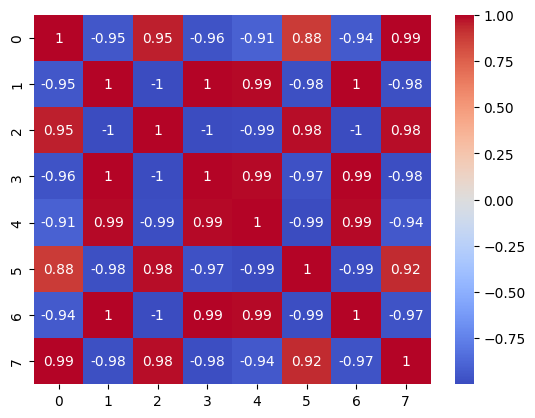

In [61]:
import seaborn as sns
import pandas as pd
sns.heatmap(
    pd.DataFrame(
        latent_sample
    ).corr(method='spearman'),
    annot=True,
    cmap='coolwarm'
)

In [ ]:
latent = get_latent(...)

### gb som 

In [337]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from minisom import MiniSom

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

from tqdm import tqdm

In [339]:
# 2. Build training matrix

# For now start with latent only:

# latent_train = np.vstack([
#     Z_tmh_train,
#     Z_lung_train
# ])

print(Z_tmh_train.shape)

# try later

# latent_xyz = np.concatenate(
#     [
#         latent,
#         0.25*coords
#     ],
#     axis=1
# )

(21252318, 8)


In [349]:
# 3. Sample voxels for SOM


# Never train on all 57M.

#N = 3_000_000
N = 10_000_000

idx = np.random.choice(
    len(Z_tmh_train),
    N,
    replace=False
)

X_som = Z_tmh_train[idx]

print(X_som.shape)

(10000000, 8)


In [ ]:
def bmu_to_labels(
        som,
        X,
        ncols):

    labels = []

    for x in tqdm(X):

        i, j = som.winner(x)

        labels.append(
            i*ncols + j
        )

    return np.array(labels)

In [350]:
### Grid Search

results = []

grids = [
    (2,2),
    (3,3),
    (4,4),
    (5,5),
    (6,6)
]

In [351]:
X_som.shape

(10000000, 8)

In [352]:
import time

results = []
som_models = {}
grid_results = {}
for nx, ny in grids:

    print("\n" + "="*80)
    print(f"STARTING SOM GRID : {nx} x {ny}")
    print("="*80)

    t0 = time.time()

    print("Creating SOM...")

    som = MiniSom(
        x=nx,
        y=ny,
        input_len=X_som.shape[1],
        sigma=1.5,
        learning_rate=0.5,
        neighborhood_function='gaussian',
        random_seed=42
    )

    print("PCA initialization...")
    t1 = time.time()

    som.pca_weights_init(X_som)

    print(
        f"PCA init completed "
        f"({(time.time()-t1):.1f} sec)"
    )

    print("Training SOM...")
    t1 = time.time()

    som.train_random(
        X_som,
        500000
    )

    train_time = time.time()-t1

    print(
        f"SOM training completed "
        f"({train_time/60:.2f} min)"
    )

    print("Computing Quantization Error...")
    qe = som.quantization_error(X_som)

    print(f"QE : {qe:.5f}")

    print("Computing Topographic Error...")
    te = som.topographic_error(X_som)

    print(f"TE : {te:.5f}")

    print("Assigning BMUs...")
    t1 = time.time()

    labels = bmu_to_labels(
        som,
        X_som,
        ny
    )

    print(
        f"BMU assignment completed "
        f"({(time.time()-t1)/60:.2f} min)"
    )

    print("Number of habitats:")

    uniq, cnt = np.unique(
        labels,
        return_counts=True
    )

    print(
        dict(
            zip(
                uniq,
                cnt
            )
        )
    )

    # for faster silhouvette calculations 

    metric_idx = np.random.choice(
    len(X_som),
    100000,
    replace=False)

    X_metric = X_som[metric_idx]
    L_metric = labels[metric_idx]
    
    
    print("Computing Silhouette...")
    sil = silhouette_score(
    X_metric,
    L_metric)
    print(f"Silhouette : {sil:.5f}")

    print("Computing Davies-Bouldin...")
    dbi = davies_bouldin_score(
        X_metric,
        L_metric
    )
    print(f"DBI : {dbi:.5f}")

    print("Computing Calinski-Harabasz...")
    chi = calinski_harabasz_score(
        X_metric,
        L_metric
    )
    print(f"CHI : {chi:.2f}")

    total_time = (
        time.time()-t0
    )/60

    print("\nFINAL METRICS")
    print("-"*60)
    print(f"Grid         : {nx}x{ny}")
    print(f"QE           : {qe:.5f}")
    print(f"TE           : {te:.5f}")
    print(f"Silhouette   : {sil:.5f}")
    print(f"DBI          : {dbi:.5f}")
    print(f"CHI          : {chi:.2f}")
    print(
        f"Total Time   : "
        f"{total_time:.2f} min"
    )

    
    som_models[f"{nx}x{ny}"] = som
    
    results.append([
        f"{nx}x{ny}",
        qe,
        te,
        sil,
        dbi,
        chi,
        total_time
    ])
    grid_results[f"{nx}x{ny}"] = {
    "som": som,
    "qe": qe,
    "te": te,
    "silhouette": sil,
    "dbi": dbi,
    "chi": chi,
    "labels": labels}


STARTING SOM GRID : 2 x 2
Creating SOM...
PCA initialization...
PCA init completed (2.4 sec)
Training SOM...
SOM training completed (0.34 min)
Computing Quantization Error...
QE : 4.22182
Computing Topographic Error...
TE : 0.00000
Assigning BMUs...


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10000000/10000000 [01:57<00:00, 85268.49it/s]


BMU assignment completed (1.97 min)
Number of habitats:
{0: 897961, 1: 2746427, 2: 1805921, 3: 4549691}
Computing Silhouette...
Silhouette : 0.30521
Computing Davies-Bouldin...
DBI : 1.10289
Computing Calinski-Harabasz...
CHI : 24182.04

FINAL METRICS
------------------------------------------------------------
Grid         : 2x2
QE           : 4.22182
TE           : 0.00000
Silhouette   : 0.30521
DBI          : 1.10289
CHI          : 24182.04
Total Time   : 4.74 min

STARTING SOM GRID : 3 x 3
Creating SOM...
PCA initialization...
PCA init completed (0.8 sec)
Training SOM...
SOM training completed (0.34 min)
Computing Quantization Error...
QE : 2.99342
Computing Topographic Error...
TE : 0.00015
Assigning BMUs...


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10000000/10000000 [02:00<00:00, 83242.63it/s]


BMU assignment completed (2.01 min)
Number of habitats:
{0: 2194122, 1: 2116870, 2: 1566515, 3: 976152, 4: 1095478, 5: 386226, 6: 1055706, 7: 305028, 8: 303903}
Computing Silhouette...
Silhouette : 0.36938
Computing Davies-Bouldin...
DBI : 1.06893
Computing Calinski-Harabasz...
CHI : 23086.72

FINAL METRICS
------------------------------------------------------------
Grid         : 3x3
QE           : 2.99342
TE           : 0.00015
Silhouette   : 0.36938
DBI          : 1.06893
CHI          : 23086.72
Total Time   : 4.76 min

STARTING SOM GRID : 4 x 4
Creating SOM...
PCA initialization...
PCA init completed (0.7 sec)
Training SOM...
SOM training completed (0.34 min)
Computing Quantization Error...
QE : 2.26484
Computing Topographic Error...
TE : 0.00703
Assigning BMUs...


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10000000/10000000 [02:03<00:00, 81113.36it/s]


BMU assignment completed (2.07 min)
Number of habitats:
{0: 667434, 1: 1018614, 2: 1042357, 3: 882574, 4: 363378, 5: 543602, 6: 868520, 7: 1444889, 8: 125720, 9: 250764, 10: 765958, 11: 245797, 12: 86343, 13: 304897, 14: 337547, 15: 1051606}
Computing Silhouette...
Silhouette : 0.31141
Computing Davies-Bouldin...
DBI : 1.11574
Computing Calinski-Harabasz...
CHI : 27790.54

FINAL METRICS
------------------------------------------------------------
Grid         : 4x4
QE           : 2.26484
TE           : 0.00703
Silhouette   : 0.31141
DBI          : 1.11574
CHI          : 27790.54
Total Time   : 4.80 min

STARTING SOM GRID : 5 x 5
Creating SOM...
PCA initialization...
PCA init completed (0.7 sec)
Training SOM...
SOM training completed (0.37 min)
Computing Quantization Error...
QE : 1.75294
Computing Topographic Error...
TE : 0.01548
Assigning BMUs...


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10000000/10000000 [02:11<00:00, 76301.33it/s]


BMU assignment completed (2.20 min)
Number of habitats:
{0: 1051380, 1: 3782, 2: 222077, 3: 123892, 4: 46869, 5: 7544, 6: 491492, 7: 274912, 8: 152066, 9: 124710, 10: 403820, 11: 308343, 12: 353692, 13: 407402, 14: 298142, 15: 822276, 16: 556055, 17: 571550, 18: 495512, 19: 466088, 20: 975260, 21: 575666, 22: 458532, 23: 542672, 24: 266266}
Computing Silhouette...
Silhouette : 0.33496
Computing Davies-Bouldin...
DBI : 1.01532
Computing Calinski-Harabasz...
CHI : 27395.80

FINAL METRICS
------------------------------------------------------------
Grid         : 5x5
QE           : 1.75294
TE           : 0.01548
Silhouette   : 0.33496
DBI          : 1.01532
CHI          : 27395.80
Total Time   : 4.95 min

STARTING SOM GRID : 6 x 6
Creating SOM...
PCA initialization...
PCA init completed (0.7 sec)
Training SOM...
SOM training completed (0.38 min)
Computing Quantization Error...
QE : 1.42810
Computing Topographic Error...
TE : 0.01368
Assigning BMUs...


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10000000/10000000 [02:13<00:00, 74682.12it/s]


BMU assignment completed (2.24 min)
Number of habitats:
{0: 520655, 1: 371263, 2: 404681, 3: 404649, 4: 424294, 5: 199004, 6: 437635, 7: 454370, 8: 504959, 9: 384290, 10: 342104, 11: 257930, 12: 373378, 13: 268510, 14: 303851, 15: 270611, 16: 283692, 17: 272978, 18: 318461, 19: 262784, 20: 274392, 21: 35888, 22: 272460, 23: 163603, 24: 3505, 25: 373276, 26: 196414, 27: 101606, 28: 74175, 29: 68195, 30: 1051378, 31: 1867, 32: 111853, 33: 131962, 34: 52443, 35: 26884}
Computing Silhouette...
Silhouette : 0.33751
Computing Davies-Bouldin...
DBI : 0.98482
Computing Calinski-Harabasz...
CHI : 32225.10

FINAL METRICS
------------------------------------------------------------
Grid         : 6x6
QE           : 1.42810
TE           : 0.01368
Silhouette   : 0.33751
DBI          : 0.98482
CHI          : 32225.10
Total Time   : 5.11 min


In [836]:
#### k-means

import time
import numpy as np

from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

results_kmeans = []
kmeans_models = {}
kmeans_results = {}

for nx, ny in grids:

    k = nx * ny

    print("\n" + "="*80)
    print(f"STARTING K-MEANS : k = {k} ({nx}x{ny} equivalent)")
    print("="*80)

    t0 = time.time()

    # ---------------------------------------------------------
    # CREATE K-MEANS
    # ---------------------------------------------------------

    print("Creating K-means...")

    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        max_iter=300,
        random_state=42,
        verbose=0
    )

    # ---------------------------------------------------------
    # TRAIN
    # ---------------------------------------------------------

    print("Training K-means...")
    t1 = time.time()

    labels = kmeans.fit_predict(X_som)

    train_time = time.time() - t1

    print(
        f"K-means training completed "
        f"({train_time/60:.2f} min)"
    )

    # ---------------------------------------------------------
    # QUANTIZATION ERROR
    # ---------------------------------------------------------
    # Analogous to SOM QE:
    # mean distance of each sample to its assigned centroid

    print("Computing Quantization Error...")

    distances = np.linalg.norm(
        X_som - kmeans.cluster_centers_[labels],
        axis=1
    )

    qe = distances.mean()

    print(f"QE : {qe:.5f}")

    # ---------------------------------------------------------
    # NO TOPOGRAPHIC ERROR FOR K-MEANS
    # ---------------------------------------------------------

    te = np.nan

    print("Topographic Error : N/A")
    print("K-means does not preserve neighborhood topology.")

    # ---------------------------------------------------------
    # HABITAT COUNTS
    # ---------------------------------------------------------

    print("Number of habitats:")

    uniq, cnt = np.unique(
        labels,
        return_counts=True
    )

    habitat_counts = dict(
        zip(
            uniq,
            cnt
        )
    )

    print(habitat_counts)

    # ---------------------------------------------------------
    # METRICS SUBSAMPLE
    # ---------------------------------------------------------

    metric_idx = np.random.choice(
        len(X_som),
        100000,
        replace=False
    )

    X_metric = X_som[metric_idx]
    L_metric = labels[metric_idx]

    # ---------------------------------------------------------
    # SILHOUETTE
    # ---------------------------------------------------------

    print("Computing Silhouette...")

    sil = silhouette_score(
        X_metric,
        L_metric
    )

    print(f"Silhouette : {sil:.5f}")

    # ---------------------------------------------------------
    # DAVIES-BOULDIN
    # ---------------------------------------------------------

    print("Computing Davies-Bouldin...")

    dbi = davies_bouldin_score(
        X_metric,
        L_metric
    )

    print(f"DBI : {dbi:.5f}")

    # ---------------------------------------------------------
    # CALINSKI-HARABASZ
    # ---------------------------------------------------------

    print("Computing Calinski-Harabasz...")

    chi = calinski_harabasz_score(
        X_metric,
        L_metric
    )

    print(f"CHI : {chi:.2f}")

    # ---------------------------------------------------------
    # TOTAL TIME
    # ---------------------------------------------------------

    total_time = (
        time.time() - t0
    ) / 60

    print("\nFINAL METRICS")
    print("-"*60)
    print(f"K            : {k}")
    print(f"Equivalent   : {nx}x{ny}")
    print(f"QE           : {qe:.5f}")
    print(f"TE           : N/A")
    print(f"Silhouette   : {sil:.5f}")
    print(f"DBI          : {dbi:.5f}")
    print(f"CHI          : {chi:.2f}")
    print(f"Total Time   : {total_time:.2f} min")

    # ---------------------------------------------------------
    # STORE MODEL
    # ---------------------------------------------------------

    key = f"{nx}x{ny}"

    kmeans_models[key] = kmeans

    results_kmeans.append([
        key,
        qe,
        te,
        sil,
        dbi,
        chi,
        total_time
    ])

    kmeans_results[key] = {
        "kmeans": kmeans,
        "k": k,
        "qe": qe,
        "te": te,
        "silhouette": sil,
        "dbi": dbi,
        "chi": chi,
        "labels": labels
    }



STARTING K-MEANS : k = 4 (2x2 equivalent)
Creating K-means...
Training K-means...
K-means training completed (1.07 min)
Computing Quantization Error...
QE : 4.27946
Topographic Error : N/A
K-means does not preserve neighborhood topology.
Number of habitats:
{0: 3671105, 1: 5913991, 2: 376189, 3: 38715}
Computing Silhouette...
Silhouette : 0.35508
Computing Davies-Bouldin...
DBI : 0.97338
Computing Calinski-Harabasz...
CHI : 74183.15

FINAL METRICS
------------------------------------------------------------
K            : 4
Equivalent   : 2x2
QE           : 4.27946
TE           : N/A
Silhouette   : 0.35508
DBI          : 0.97338
CHI          : 74183.15
Total Time   : 2.92 min

STARTING K-MEANS : k = 9 (3x3 equivalent)
Creating K-means...
Training K-means...
K-means training completed (1.91 min)
Computing Quantization Error...
QE : 2.78326
Topographic Error : N/A
K-means does not preserve neighborhood topology.
Number of habitats:
{0: 1052195, 1: 1310034, 2: 47872, 3: 116209, 4: 8260, 

In [841]:
### only SOM

import time
import numpy as np
from minisom import MiniSom
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# ============================================================
# 1. Z-SCALE: FIT ONLY ON TMH TRAIN
# ============================================================

z_scaler_direct = StandardScaler()

X_tmh_train_scaled = z_scaler_direct.fit_transform(
    X_tmh_train
)

print("Scaled shape:", X_tmh_train_scaled.shape)


# ============================================================
# 2. SAME 10M VOXEL SAMPLE FOR FAIR COMPARISON
# ============================================================

N_SOM = 10_000_000

rng = np.random.default_rng(42)

idx_som = rng.choice(
    len(X_tmh_train_scaled),
    N_SOM,
    replace=False
)

X_som_direct = X_tmh_train_scaled[idx_som]

print("SOM sample:", X_som_direct.shape)


# ============================================================
# 3. TRAIN DIRECT SOM
# ============================================================

nx, ny = 6 ,6

t0 = time.time()

som_direct = MiniSom(
    x=nx,
    y=ny,
    input_len=X_som_direct.shape[1],   # 10 features
    sigma=1.5,
    learning_rate=0.5,
    neighborhood_function="gaussian",
    random_seed=42
)

print("PCA initialization...")
som_direct.pca_weights_init(X_som_direct)

print("Training SOM...")

som_direct.train_random(
    X_som_direct,
    500_000,
    verbose=True
)

train_time = (time.time() - t0) / 60

print(f"\nTraining time: {train_time:.2f} min")


# ============================================================
# 4. SOM METRICS
# ============================================================

print("\nComputing QE...")
qe = som_direct.quantization_error(X_som_direct)

print("Computing TE...")
te = som_direct.topographic_error(X_som_direct)

print("Assigning BMUs...")

labels = bmu_to_labels(
    som_direct,
    X_som_direct,
    ny
)

# Habitat occupancy
uniq, cnt = np.unique(
    labels,
    return_counts=True
)

print("\nHabitat counts:")
print(dict(zip(uniq, cnt)))


# ============================================================
# 5. FIXED METRIC SUBSAMPLE
# ============================================================

metric_idx = rng.choice(
    len(X_som_direct),
    100_000,
    replace=False
)

X_metric = X_som_direct[metric_idx]
L_metric = labels[metric_idx]


# ============================================================
# 6. CLUSTERING METRICS
# ============================================================

print("\nComputing Silhouette...")

sil = silhouette_score(
    X_metric,
    L_metric
)

print(f"Silhouette : {sil:.5f}")


print("Computing Davies-Bouldin...")

dbi = davies_bouldin_score(
    X_metric,
    L_metric
)

print(f"DBI : {dbi:.5f}")


print("Computing Calinski-Harabasz...")

chi = calinski_harabasz_score(
    X_metric,
    L_metric
)

print(f"CHI : {chi:.2f}")


# ============================================================
# 7. FINAL RESULTS
# ============================================================

total_time = (time.time() - t0) / 60

print("\n" + "="*60)
print("DIRECT SOM RESULTS")
print("="*60)

print(f"Grid         : {nx}x{ny}")
print(f"Input        : 10-D Z-scored GLDM")
print(f"QE           : {qe:.5f}")
print(f"TE           : {te:.5f}")
print(f"Silhouette   : {sil:.5f}")
print(f"DBI          : {dbi:.5f}")
print(f"CHI          : {chi:.2f}")
print(f"Total Time   : {total_time:.2f} min")


# ============================================================
# 8. SAVE EVERYTHING
# ============================================================

direct_som_results = {
    "som": som_direct,
    "grid": "6x6",
    "qe": qe,
    "te": te,
    "silhouette": sil,
    "dbi": dbi,
    "chi": chi,
    "labels": labels
}

Scaled shape: (21252318, 10)
SOM sample: (10000000, 10)
PCA initialization...
Training SOM...
 [ 500000 / 500000 ] 100% - 0:00:00 left 
 quantization error: 0.7071610596408374

Training time: 8.18 min

Computing QE...
Computing TE...
Assigning BMUs...


  0%|          | 0/10000000 [00:00<?, ?it/s]


Habitat counts:
{0: 158443, 1: 206464, 2: 129008, 3: 440782, 4: 343108, 5: 474581, 6: 186004, 7: 301458, 8: 266507, 9: 499449, 10: 291038, 11: 240238, 12: 89787, 13: 365254, 14: 521683, 15: 339189, 16: 299180, 17: 90382, 18: 294897, 19: 452495, 20: 237800, 21: 373810, 22: 85602, 23: 84874, 24: 284501, 25: 217570, 26: 336464, 27: 288270, 28: 119003, 30: 257723, 31: 208717, 32: 311721, 33: 151733, 35: 1052265}

Computing Silhouette...
Silhouette : 0.28426
Computing Davies-Bouldin...
DBI : 1.21255
Computing Calinski-Harabasz...
CHI : 14296.84

DIRECT SOM RESULTS
Grid         : 6x6
Input        : 10-D Z-scored GLDM
QE           : 0.70716
TE           : 0.02239
Silhouette   : 0.28426
DBI          : 1.21255
CHI          : 14296.84
Total Time   : 16.20 min


In [ ]:
#### 5x5

Scaled shape: (21252318, 10)
SOM sample: (10000000, 10)
PCA initialization...
Training SOM...
 [ 500000 / 500000 ] 100% - 0:00:00 left 
 quantization error: 0.8158002657053289

Training time: 8.78 min

Computing QE...
Computing TE...
Assigning BMUs...


  0%|          | 0/10000000 [00:00<?, ?it/s]


Habitat counts:
{0: 1052265, 1: 74, 2: 538548, 3: 69342, 4: 278884, 5: 18, 6: 602852, 7: 568283, 8: 291073, 9: 439394, 10: 439738, 11: 603395, 12: 500612, 13: 709604, 14: 272656, 15: 184952, 16: 457225, 17: 463238, 18: 502982, 19: 522488, 20: 100726, 21: 168143, 22: 357237, 23: 513999, 24: 362272}

Computing Silhouette...
Silhouette : 0.29353
Computing Davies-Bouldin...
DBI : 1.15988
Computing Calinski-Harabasz...
CHI : 16945.82

DIRECT SOM RESULTS
Grid         : 5x5
Input        : 10-D Z-scored GLDM
QE           : 0.81580
TE           : 0.05522
Silhouette   : 0.29353
DBI          : 1.15988
CHI          : 16945.82
Total Time   : 14.59 min


In [ ]:
#### 4x4

Scaled shape: (21252318, 10)
SOM sample: (10000000, 10)
PCA initialization...
Training SOM...
 [ 500000 / 500000 ] 100% - 0:00:00 left 
 quantization error: 0.976506793044691

Training time: 6.58 min

Computing QE...
Computing TE...
Assigning BMUs...


  0%|          | 0/10000000 [00:00<?, ?it/s]


Habitat counts:
{0: 360618, 1: 870653, 2: 2450, 3: 1052265, 4: 831336, 5: 914785, 6: 755563, 7: 1689, 8: 795208, 9: 572717, 10: 883617, 11: 596144, 12: 601527, 13: 612689, 14: 778821, 15: 369918}

Computing Silhouette...
Silhouette : 0.29026
Computing Davies-Bouldin...
DBI : 1.29932
Computing Calinski-Harabasz...
CHI : 15688.26

DIRECT SOM RESULTS
Grid         : 4x4
Input        : 10-D Z-scored GLDM
QE           : 0.97651
TE           : 0.07270
Silhouette   : 0.29026
DBI          : 1.29932
CHI          : 15688.26
Total Time   : 10.83 min


In [ ]:
# 3x3

Scaled shape: (21252318, 10)
SOM sample: (10000000, 10)
PCA initialization...
Training SOM...
 [ 500000 / 500000 ] 100% - 0:00:00 left 
 quantization error: 1.3713834453708384

Training time: 6.46 min

Computing QE...
Computing TE...
Assigning BMUs...


  0%|          | 0/10000000 [00:00<?, ?it/s]


Habitat counts:
{0: 1052265, 1: 185702, 2: 1277455, 3: 1280192, 4: 2547687, 5: 635481, 6: 1237668, 7: 1652973, 8: 130577}

Computing Silhouette...
Silhouette : 0.27712
Computing Davies-Bouldin...
DBI : 1.35309
Computing Calinski-Harabasz...
CHI : 21436.10

DIRECT SOM RESULTS
Grid         : 3x3
Input        : 10-D Z-scored GLDM
QE           : 1.37138
TE           : 0.00860
Silhouette   : 0.27712
DBI          : 1.35309
CHI          : 21436.10
Total Time   : 10.65 min


In [ ]:
### 2x2

Scaled shape: (21252318, 10)
SOM sample: (10000000, 10)
PCA initialization...
Training SOM...
 [ 500000 / 500000 ] 100% - 0:00:00 left 
 quantization error: 1.9410093006418891

Training time: 6.40 min

Computing QE...
Computing TE...
Assigning BMUs...


  0%|          | 0/10000000 [00:00<?, ?it/s]


Habitat counts:
{0: 1337945, 1: 2324106, 2: 3622438, 3: 2715511}

Computing Silhouette...
Silhouette : 0.29257
Computing Davies-Bouldin...
DBI : 1.23474
Computing Calinski-Harabasz...
CHI : 24988.22

DIRECT SOM RESULTS
Grid         : 2x2
Input        : 10-D Z-scored GLDM
QE           : 1.94101
TE           : 0.00000
Silhouette   : 0.29257
DBI          : 1.23474
CHI          : 24988.22
Total Time   : 10.67 min


In [353]:
import joblib

# save everything
joblib.dump(grid_results, "gb_tmh_som_all_grids.pkl")

['gb_tmh_som_all_grids.pkl']

In [358]:
grid_results["2x2"]

{'som': <minisom.MiniSom at 0x7fb1dda206e0>,
 'qe': 4.221824460355508,
 'te': 0.0,
 'silhouette': 0.30520853,
 'dbi': 1.102893163814181,
 'chi': 24182.04140782839,
 'labels': array([1, 3, 3, ..., 2, 3, 3])}

In [ ]:
# save best model
joblib.dump(grid_results["4x4"], "som_4x4.pkl")

# save weights separately (deployment safe)
np.save(
    "som_4x4_weights.npy",
    grid_results["4x4"]["som"].get_weights()
)

In [360]:
results

[['2x2',
  4.221824460355508,
  0.0,
  0.30520853,
  1.102893163814181,
  24182.04140782839,
  4.744624718030294],
 ['3x3',
  2.9934208631886894,
  0.0001538,
  0.36937538,
  1.0689307010853175,
  23086.724614550254,
  4.763776318232218],
 ['4x4',
  2.2648408694893356,
  0.0070322,
  0.31140852,
  1.1157415977363632,
  27790.53746720719,
  4.800254380702972],
 ['5x5',
  1.7529352004479761,
  0.0154848,
  0.3349553,
  1.0153181950208747,
  27395.795204005237,
  4.95301992893219],
 ['6x6',
  1.428098697050371,
  0.0136759,
  0.3375118,
  0.9848249920306924,
  32225.103948639546,
  5.110234602292379]]

In [844]:
 pd.DataFrame(grid_results)

,2x2,3x3,4x4,5x5,6x6
som,<minisom.MiniSom object at 0x7fb1dda206e0>,<minisom.MiniSom object at 0x7fb1dc9c7e60>,<minisom.MiniSom object at 0x7fb1dda21880>,<minisom.MiniSom object at 0x7fb1dc9c4260>,<minisom.MiniSom object at 0x7fb1dc9c1640>
qe,4.221824,2.993421,2.264841,1.752935,1.428099
te,0.0,0.000154,0.007032,0.015485,0.013676
silhouette,0.305209,0.369375,0.311409,0.334955,0.337512
dbi,1.102893,1.068931,1.115742,1.015318,0.984825
chi,24182.041408,23086.724615,27790.537467,27395.795204,32225.103949
labels,"[1, 3, 3, 3, 1, 2, 3, 1, 1, 3, 1, 1, 3, 2, 2, ...","[2, 0, 0, 3, 5, 1, 1, 2, 2, 0, 1, 2, 6, 4, 4, ...","[1, 7, 7, 6, 4, 10, 2, 5, 0, 3, 1, 5, 15, 10, ...","[18, 20, 15, 10, 19, 23, 22, 13, 19, 16, 23, 1...","[10, 0, 6, 12, 23, 5, 2, 16, 17, 7, 5, 16, 30,..."


In [843]:
 pd.DataFrame(results)

,penalty,cindex_mean
0,0.001,0.488366
1,0.003,0.551758
2,0.010,0.515258
3,0.030,0.502448
4,0.100,0.476667
5,0.300,0.462489
6,0.500,0.516477
7,0.800,0.477928
8,1.000,0.526619


In [362]:
### rresults
som_results_tmh = pd.DataFrame(

    results,

    columns=[
        "Grid",
        "QE",
        "TE",
        "Silhouette",
        "DBI",
        "CHI",
        "Total_time_in_mins"
    ]
)


som_results_tmh.to_csv(
    "tmh_som_grid_search_1M_10fts.csv",
    index=False
)
som_results_tmh

,Grid,QE,TE,Silhouette,DBI,CHI,Total_time_in_mins
0,2x2,4.221824,0.000000,0.305209,1.102893,24182.041408,4.744625
1,3x3,2.993421,0.000154,0.369375,1.068931,23086.724615,4.763776
2,4x4,2.264841,0.007032,0.311409,1.115742,27790.537467,4.800254
3,5x5,1.752935,0.015485,0.334955,1.015318,27395.795204,4.953020
4,6x6,1.428099,0.013676,0.337512,0.984825,32225.103949,5.110235


In [363]:
grid_results

{'2x2': {'som': <minisom.MiniSom at 0x7fb1dda206e0>,
  'qe': 4.221824460355508,
  'te': 0.0,
  'silhouette': 0.30520853,
  'dbi': 1.102893163814181,
  'chi': 24182.04140782839,
  'labels': array([1, 3, 3, ..., 2, 3, 3])},
 '3x3': {'som': <minisom.MiniSom at 0x7fb1dc9c7e60>,
  'qe': 2.9934208631886894,
  'te': 0.0001538,
  'silhouette': 0.36937538,
  'dbi': 1.0689307010853175,
  'chi': 23086.724614550254,
  'labels': array([2, 0, 0, ..., 4, 0, 0])},
 '4x4': {'som': <minisom.MiniSom at 0x7fb1dda21880>,
  'qe': 2.2648408694893356,
  'te': 0.0070322,
  'silhouette': 0.31140852,
  'dbi': 1.1157415977363632,
  'chi': 27790.53746720719,
  'labels': array([ 1,  7,  7, ..., 14,  7,  3])},
 '5x5': {'som': <minisom.MiniSom at 0x7fb1dc9c4260>,
  'qe': 1.7529352004479761,
  'te': 0.0154848,
  'silhouette': 0.3349553,
  'dbi': 1.0153181950208747,
  'chi': 27395.795204005237,
  'labels': array([18, 20, 15, ...,  7, 15, 15])},
 '6x6': {'som': <minisom.MiniSom at 0x7fb1dc9c1640>,
  'qe': 1.428098697050

In [368]:
# load later
#grid_results = joblib.load("som_all_grids.pkl")

som_4x4 = grid_results["4x4"]["som"]
labels_4x4 = grid_results["4x4"]["labels"]

som_3x3 = grid_results["3x3"]["som"]
labels_3x3 = grid_results["3x3"]["labels"]

som_2x2 = grid_results["2x2"]["som"]
labels_2x2 = grid_results["2x2"]["labels"]

In [817]:
som_2x2

In [370]:
np.unique(labels_3x3)

array([0, 1, 2, 3, 4, 5, 6, 7, 8])

In [371]:
import pandas as pd

counts = pd.Series(labels).value_counts().sort_index()
print(counts)

0      520655
1      371263
2      404681
3      404649
4      424294
5      199004
6      437635
7      454370
8      504959
9      384290
10     342104
11     257930
12     373378
13     268510
14     303851
15     270611
16     283692
17     272978
18     318461
19     262784
20     274392
21      35888
22     272460
23     163603
24       3505
25     373276
26     196414
27     101606
28      74175
29      68195
30    1051378
31       1867
32     111853
33     131962
34      52443
35      26884
Name: count, dtype: int64


In [128]:
import numpy as np

for h in range(16):
    idx = labels == h
    mean_feat = X_ae[idx].mean(axis=0)

    print(f"Habitat {h}:", np.round(mean_feat, 3))

IndexError: boolean index did not match indexed array along dimension 0; dimension is 57023838 but corresponding boolean dimension is 3000000

In [58]:
som_results

,Grid,QE,TE,Silhouette,DBI,CHI,Total_time_in_mins
0,2x2,57319.677755,0.0,0.530597,0.685796,86096.514067,4.073902


In [372]:
som_results

,Grid,QE,TE,Silhouette,DBI,CHI,Total_time_in_mins
0,2x2,43931.639554,0.000000,0.565499,0.661411,93329.261450,5.554062
1,3x3,27860.744615,0.115165,0.523350,0.841842,95531.887820,5.170902
2,4x4,18638.536475,0.089245,0.506748,0.691476,103615.278311,7.036172
3,5x5,13708.154065,0.114580,0.454054,0.665683,102165.509496,7.360795
4,6x6,10478.745256,0.169535,0.454961,0.615743,117169.988575,5.324813


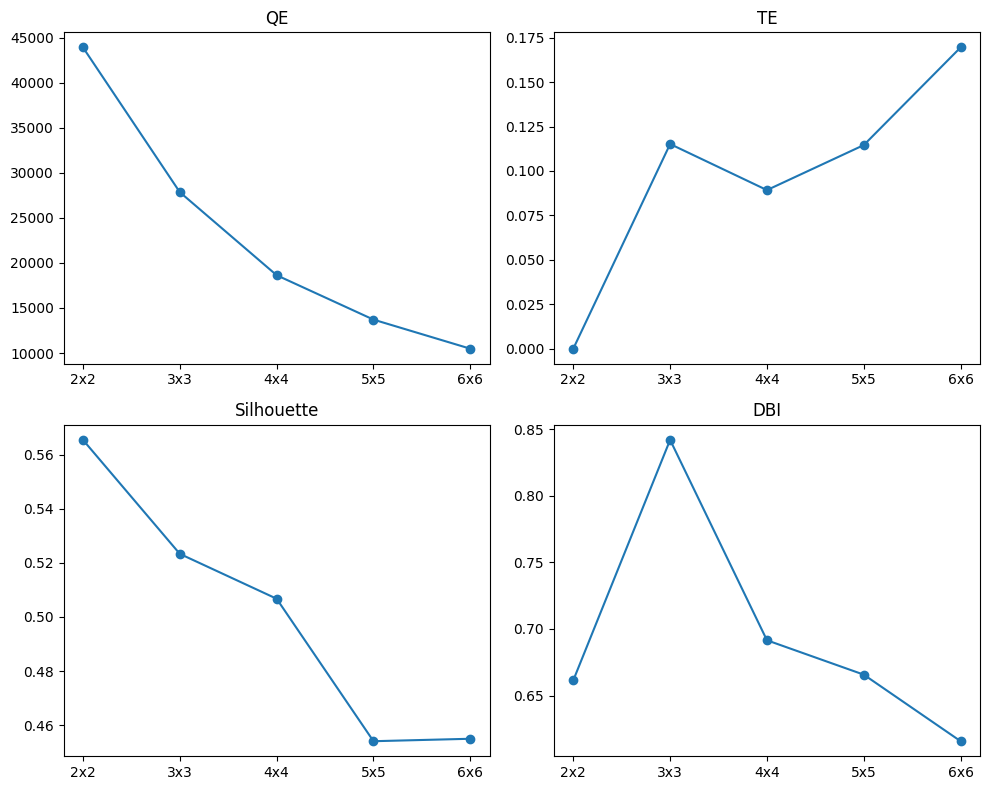

In [373]:
fig, ax = plt.subplots(
    2,
    2,
    figsize=(10,8)
)

metrics = [
    "QE",
    "TE",
    "Silhouette",
    "DBI"
]

for a,m in zip(
        ax.ravel(),
        metrics):

    a.plot(
        som_results["Grid"],
        som_results[m],
        marker='o'
    )

    a.set_title(m)

plt.tight_layout()

In [131]:
# old

In [ ]:
# check stability of silhovette

In [374]:
for seed in range(5):

    metric_idx = np.random.choice(
        len(X_som),
        50000,
        replace=False
    )

    X_metric = X_som[metric_idx]
    L_metric = labels[metric_idx]

    sil = silhouette_score(
        X_metric,
        L_metric
    )

    print(seed, sil)

0 0.33533698
1 0.33483633
2 0.33508956


KeyboardInterrupt: 

In [255]:
labels = assign_habitats(som, X_som, 4)

counts = pd.Series(labels).value_counts().sort_index()
print(counts)
print((counts / len(labels)).round(4))

NameError: name 'assign_habitats' is not defined

### checking if the habitats are meaningful?

In [375]:
counts = pd.Series(labels_2x2).value_counts().sort_index()

occupancy_22 = pd.DataFrame({
    "Habitat": counts.index,
    "Count": counts.values,
    "Percent": counts.values / len(labels_2x2) * 100
})

display(occupancy_22)

,Habitat,Count,Percent
0,0,897961,8.97961
1,1,2746427,27.46427
2,2,1805921,18.05921
3,3,4549691,45.49691


In [376]:
counts = pd.Series(labels_4x4).value_counts().sort_index()

occupancy_44 = pd.DataFrame({
    "Habitat": counts.index,
    "Count": counts.values,
    "Percent": counts.values / len(labels_4x4) * 100
})

display(occupancy_44)

,Habitat,Count,Percent
0,0,667434,6.67434
1,1,1018614,10.18614
2,2,1042357,10.42357
3,3,882574,8.82574
4,4,363378,3.63378
5,5,543602,5.43602
6,6,868520,8.68520
7,7,1444889,14.44889
8,8,125720,1.25720
9,9,250764,2.50764


In [377]:
counts = pd.Series(labels_3x3).value_counts().sort_index()

occupancy_33 = pd.DataFrame({
    "Habitat": counts.index,
    "Count": counts.values,
    "Percent": counts.values / len(labels_3x3) * 100
})

display(occupancy_33)


,Habitat,Count,Percent
0,0,2194122,21.94122
1,1,2116870,21.16870
2,2,1566515,15.66515
3,3,976152,9.76152
4,4,1095478,10.95478
5,5,386226,3.86226
6,6,1055706,10.55706
7,7,305028,3.05028
8,8,303903,3.03903


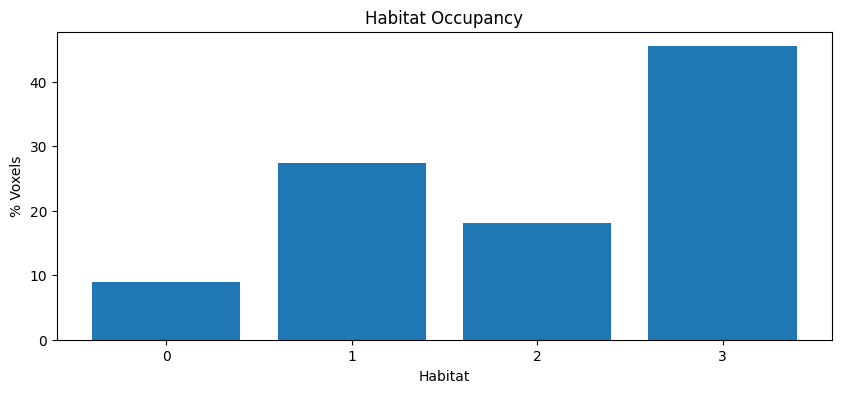

In [380]:
plt.figure(figsize=(10,4))
plt.bar(occupancy_22["Habitat"].astype(str), occupancy_22["Percent"])
plt.xlabel("Habitat")
plt.ylabel("% Voxels")
plt.title("Habitat Occupancy")
plt.show()

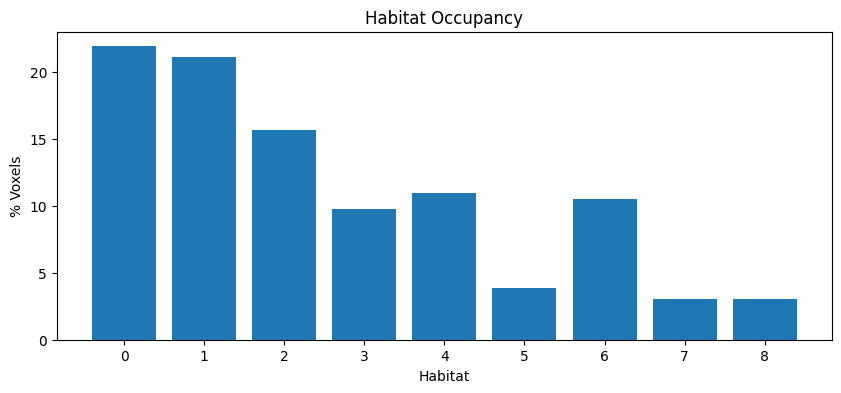

In [381]:
plt.figure(figsize=(10,4))
plt.bar(occupancy_33["Habitat"].astype(str), occupancy_33["Percent"])
plt.xlabel("Habitat")
plt.ylabel("% Voxels")
plt.title("Habitat Occupancy")
plt.show()

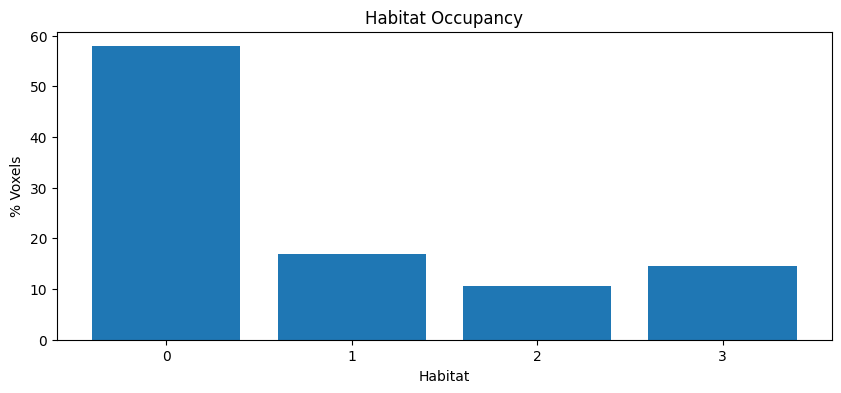

In [ ]:
# old

In [ ]:
### seems the best is the 3x3

In [383]:
som_2x2

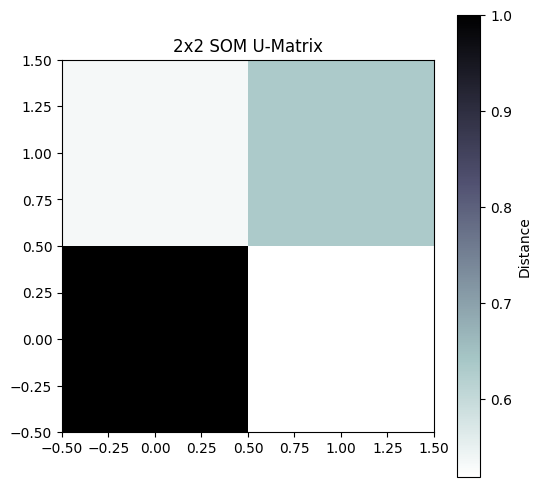

In [386]:
### plot U matrix

plt.figure(figsize=(6,6))

plt.imshow(
    som_2x2.distance_map().T,
    cmap="bone_r",
    origin="lower"
)

plt.colorbar(label="Distance")
plt.title("2x2 SOM U-Matrix")
plt.show()

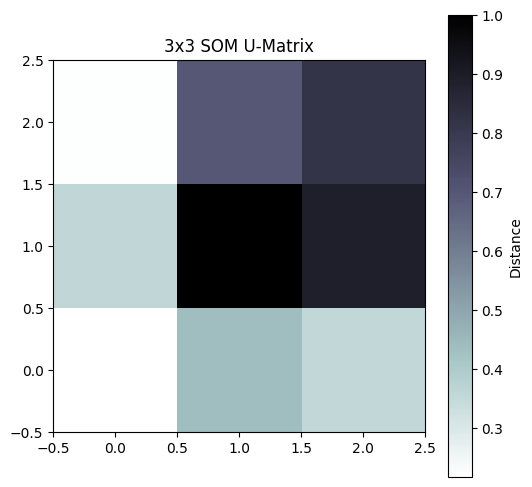

In [382]:
### plot U matrix

plt.figure(figsize=(6,6))

plt.imshow(
    som_3x3.distance_map().T,
    cmap="bone_r",
    origin="lower"
)

plt.colorbar(label="Distance")
plt.title("3x3 SOM U-Matrix")
plt.show()

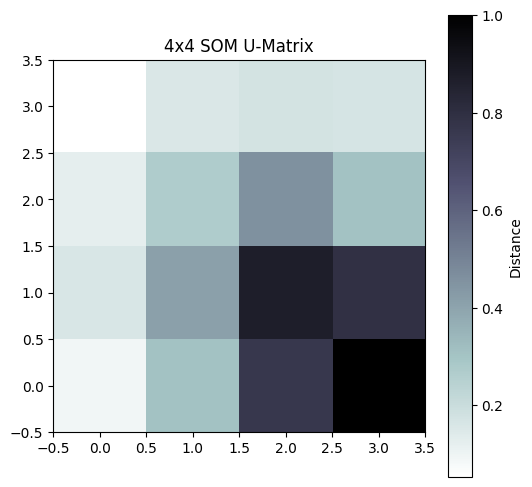

In [387]:
### plot U matrix

plt.figure(figsize=(6,6))

plt.imshow(
    som_4x4.distance_map().T,
    cmap="bone_r",
    origin="lower"
)

plt.colorbar(label="Distance")
plt.title("4x4 SOM U-Matrix")
plt.show()

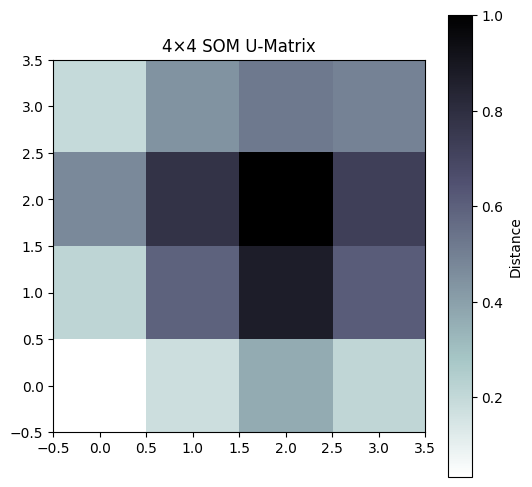

In [ ]:
## old

In [818]:
weights = som_2x2.get_weights()

print(weights.shape)

(2, 2, 8)


In [819]:
### flatten the code book

import pandas as pd

codebook = weights.reshape(-1, weights.shape[-1])

codebook_df = pd.DataFrame(
    codebook,
    columns=[f"Z{i}" for i in range(codebook.shape[1])]
)

display(codebook_df.round(3))

,Z0,Z1,Z2,Z3,Z4,Z5,Z6,Z7
0,5.456,-3.328,0.116,-12.271,-0.484,6.199,-11.592,2.453
1,2.535,-1.050,-1.270,-6.797,-1.004,4.055,-5.690,-0.539
2,2.269,-2.307,0.441,-5.586,0.060,2.633,-4.822,1.321
3,1.780,-0.975,-0.683,-3.710,-0.417,1.748,-3.410,0.576


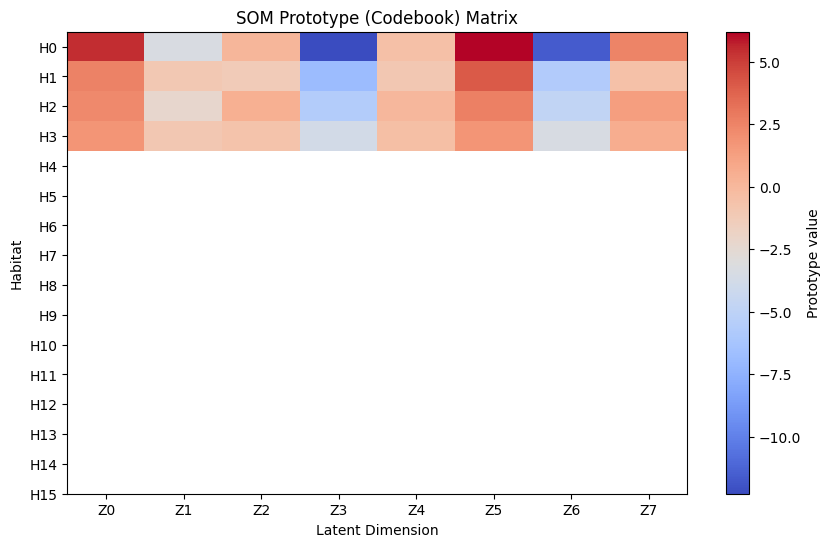

In [820]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.imshow(codebook, aspect="auto", cmap="coolwarm")
plt.colorbar(label="Prototype value")
plt.yticks(range(16), [f"H{i}" for i in range(16)])
plt.xticks(range(8), [f"Z{i}" for i in range(8)])
plt.xlabel("Latent Dimension")
plt.ylabel("Habitat")
plt.title("SOM Prototype (Codebook) Matrix")
plt.show()

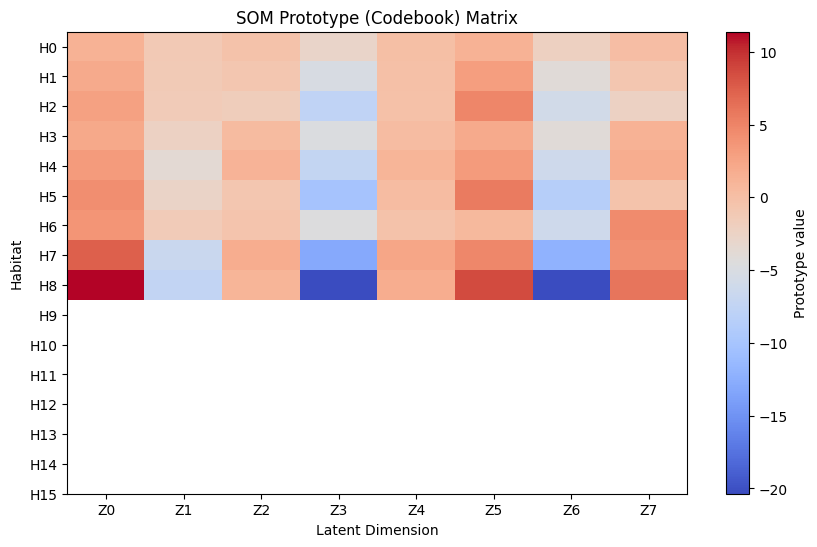

In [390]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.imshow(codebook, aspect="auto", cmap="coolwarm")
plt.colorbar(label="Prototype value")
plt.yticks(range(16), [f"H{i}" for i in range(16)])
plt.xticks(range(8), [f"Z{i}" for i in range(8)])
plt.xlabel("Latent Dimension")
plt.ylabel("Habitat")
plt.title("SOM Prototype (Codebook) Matrix")
plt.show()

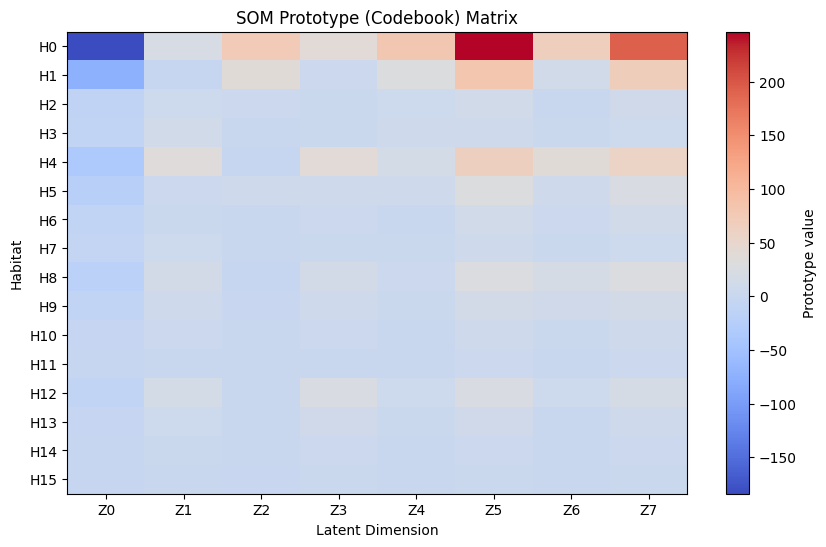

In [ ]:
#old

In [394]:
weights = som_3x3.get_weights().reshape(-1, 8)

prototype_var = pd.DataFrame({
    "Latent": [f"Z{i}" for i in range(8)],
    "Variance": weights.var(axis=0),
    "Range": weights.max(axis=0) - weights.min(axis=0)
})

display(prototype_var.sort_values("Variance", ascending=False))

,Latent,Variance,Range
6,Z6,26.960110,18.025767
3,Z3,26.486757,17.543228
0,Z0,9.136347,10.119405
7,Z7,6.928507,8.332261
5,Z5,5.403297,7.907472
1,Z1,4.974857,6.221047
2,Z2,1.154035,3.477943
4,Z4,0.832230,2.730666


In [1093]:
som_3x3

In [ ]:
# old

,Latent,Variance,Range
5,Z5,3424.936295,242.903053
7,Z7,2083.798951,187.553206
0,Z0,1974.244244,181.579462
4,Z4,353.637000,78.070559
2,Z2,353.543766,74.160997
6,Z6,277.371436,65.073666
3,Z3,140.739069,37.054951
1,Z1,71.783109,34.738534


### gb stability and reproducibility

In [860]:
som_models

{'2x2': <minisom.MiniSom at 0x7fb1dda206e0>,
 '3x3': <minisom.MiniSom at 0x7fb1dc9c7e60>,
 '4x4': <minisom.MiniSom at 0x7fb1dda21880>,
 '5x5': <minisom.MiniSom at 0x7fb1dc9c4260>,
 '6x6': <minisom.MiniSom at 0x7fb1dc9c1640>}

In [861]:
import numpy as np
import time

from minisom import MiniSom
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)
from scipy.optimize import linear_sum_assignment


# ============================================================
# SETTINGS
# ============================================================

B = 50
NX, NY = 3, 3
N_ITER = 500_000

rng = np.random.default_rng(42)

# ------------------------------------------------------------
# Reference SOM
# ------------------------------------------------------------

reference_som = som_models["3x3"]

# Use a FIXED evaluation set for every bootstrap SOM
N_EVAL = 100_000

eval_idx = rng.choice(
    len(X_som),
    N_EVAL,
    replace=False
)

X_eval = X_som[eval_idx]

# Reference labels
reference_labels = bmu_to_labels(
    reference_som,
    X_eval,
    NY
)

# Reference prototypes
reference_weights = reference_som.get_weights().reshape(
    NX * NY,
    X_som.shape[1]
)


# ============================================================
# STORAGE
# ============================================================

ari_scores = []
nmi_scores = []
dice_scores = []
centroid_corrs = []

bootstrap_soms = []


# ============================================================
# BOOTSTRAP LOOP
# ============================================================

for b in range(B):

    t0 = time.time()

    print("\n" + "="*70)
    print(f"BOOTSTRAP {b+1}/{B}")
    print("="*70)

    # --------------------------------------------------------
    # Bootstrap sample
    # --------------------------------------------------------

    boot_idx = rng.choice(
        len(X_som),
        len(X_som),
        replace=True
    )

    X_boot = X_som[boot_idx]

    # --------------------------------------------------------
    # Train SOM
    # --------------------------------------------------------

    som_b = MiniSom(
        x=NX,
        y=NY,
        input_len=X_som.shape[1],
        sigma=1.5,
        learning_rate=0.5,
        neighborhood_function="gaussian",
        random_seed=88 + b
    )

    som_b.pca_weights_init(X_boot)

    som_b.train_random(
        X_boot,
        N_ITER,
        verbose=False
    )

    # --------------------------------------------------------
    # Apply bootstrap SOM to SAME evaluation voxels
    # --------------------------------------------------------

    labels_b = bmu_to_labels(
        som_b,
        X_eval,
        NY
    )

    # --------------------------------------------------------
    # ARI / NMI
    # --------------------------------------------------------

    ari = adjusted_rand_score(
        reference_labels,
        labels_b
    )

    nmi = normalized_mutual_info_score(
        reference_labels,
        labels_b
    )

    # --------------------------------------------------------
    # Prototype matching
    # --------------------------------------------------------

    weights_b = som_b.get_weights().reshape(
        NX * NY,
        X_som.shape[1]
    )

    # Pairwise distances between reference and bootstrap
    distance_matrix = np.linalg.norm(
        reference_weights[:, None, :] -
        weights_b[None, :, :],
        axis=2
    )

    row_ind, col_ind = linear_sum_assignment(
        distance_matrix
    )

    # --------------------------------------------------------
    # Align bootstrap labels
    # --------------------------------------------------------

    mapping = {
        col: row
        for row, col in zip(row_ind, col_ind)
    }

    aligned_labels = np.array([
        mapping[label]
        for label in labels_b
    ])

    # --------------------------------------------------------
    # Dice per habitat
    # --------------------------------------------------------

    dice_per_habitat = []

    for h in range(NX * NY):

        ref_mask = reference_labels == h
        boot_mask = aligned_labels == h

        intersection = np.sum(
            ref_mask & boot_mask
        )

        denominator = (
            np.sum(ref_mask) +
            np.sum(boot_mask)
        )

        if denominator == 0:
            dice = np.nan
        else:
            dice = (
                2.0 * intersection /
                denominator
            )

        dice_per_habitat.append(dice)

    mean_dice = np.nanmean(
        dice_per_habitat
    )

    # --------------------------------------------------------
    # Centroid correlation
    # --------------------------------------------------------

    matched_ref = reference_weights[row_ind]
    matched_boot = weights_b[col_ind]

    centroid_corr = np.mean([
        np.corrcoef(
            matched_ref[i],
            matched_boot[i]
        )[0, 1]
        for i in range(len(row_ind))
    ])

    # --------------------------------------------------------
    # Store
    # --------------------------------------------------------

    ari_scores.append(ari)
    nmi_scores.append(nmi)
    dice_scores.append(mean_dice)
    centroid_corrs.append(centroid_corr)

    bootstrap_soms.append(som_b)

    print(f"ARI              : {ari:.4f}")
    print(f"NMI              : {nmi:.4f}")
    print(f"Mean Dice        : {mean_dice:.4f}")
    print(f"Centroid Corr.   : {centroid_corr:.4f}")
    print(f"Time             : {(time.time()-t0)/60:.2f} min")


# ============================================================
# SUMMARY
# ============================================================

print("\n" + "="*70)
print("SOM REPRODUCIBILITY RESULTS")
print("="*70)

def summarize(x):
    x = np.asarray(x)
    return (
        np.mean(x),
        np.std(x),
        np.percentile(x, 2.5),
        np.percentile(x, 97.5)
    )

for name, values in [
    ("ARI", ari_scores),
    ("NMI", nmi_scores),
    ("Dice", dice_scores),
    ("Centroid correlation", centroid_corrs)
]:

    mean, std, lo, hi = summarize(values)

    print(
        f"{name:22s}: "
        f"{mean:.4f} ± {std:.4f} "
        f"(95% range: {lo:.4f}–{hi:.4f})"
    )

  0%|          | 0/100000 [00:00<?, ?it/s]


BOOTSTRAP 1/50


  0%|          | 0/100000 [00:00<?, ?it/s]

ARI              : 0.6709
NMI              : 0.7619
Mean Dice        : 0.7300
Centroid Corr.   : 0.9864
Time             : 0.44 min

BOOTSTRAP 2/50


  0%|          | 0/100000 [00:00<?, ?it/s]

ARI              : 0.6153
NMI              : 0.7288
Mean Dice        : 0.6364
Centroid Corr.   : 0.9800
Time             : 0.39 min

BOOTSTRAP 3/50


... (92 outputs left out)

  0%|          | 0/100000 [00:00<?, ?it/s]

ARI              : 0.7425
NMI              : 0.7692
Mean Dice        : 0.7436
Centroid Corr.   : 0.9894
Time             : 0.38 min

BOOTSTRAP 50/50


  0%|          | 0/100000 [00:00<?, ?it/s]

ARI              : 0.7356
NMI              : 0.7796
Mean Dice        : 0.7892
Centroid Corr.   : 0.9839
Time             : 0.38 min

SOM REPRODUCIBILITY RESULTS
ARI                   : 0.7043 ± 0.0699 (95% range: 0.5641–0.8446)
NMI                   : 0.7735 ± 0.0362 (95% range: 0.7061–0.8474)
Dice                  : 0.7469 ± 0.0882 (95% range: 0.5701–0.8941)
Centroid correlation  : 0.9907 ± 0.0039 (95% range: 0.9839–0.9963)


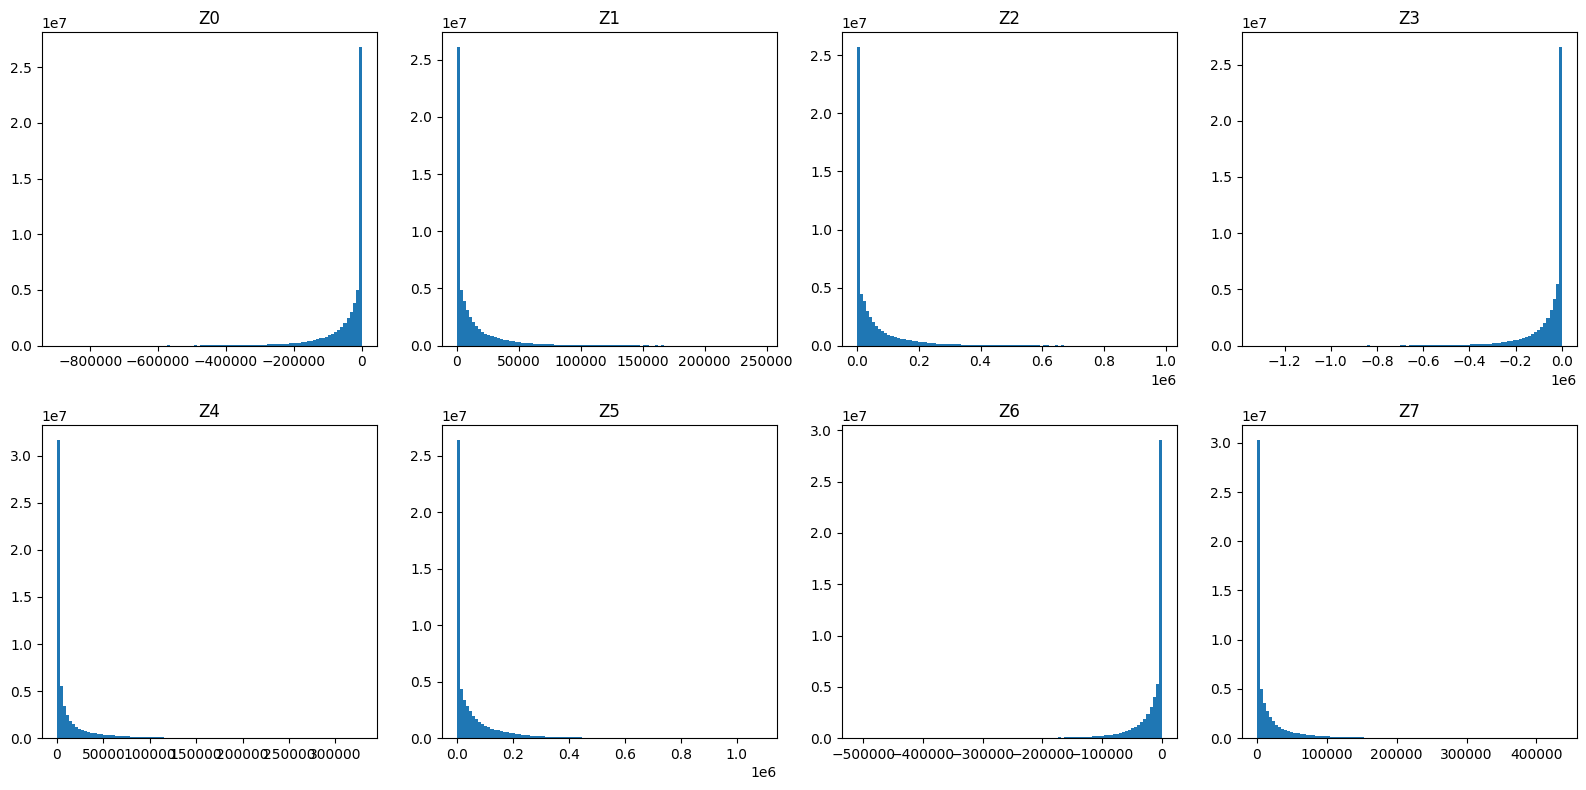

In [862]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i, ax in enumerate(axes.ravel()):
    ax.hist(latent_train[:, i], bins=100)
    ax.set_title(f"Z{i}")

plt.tight_layout()

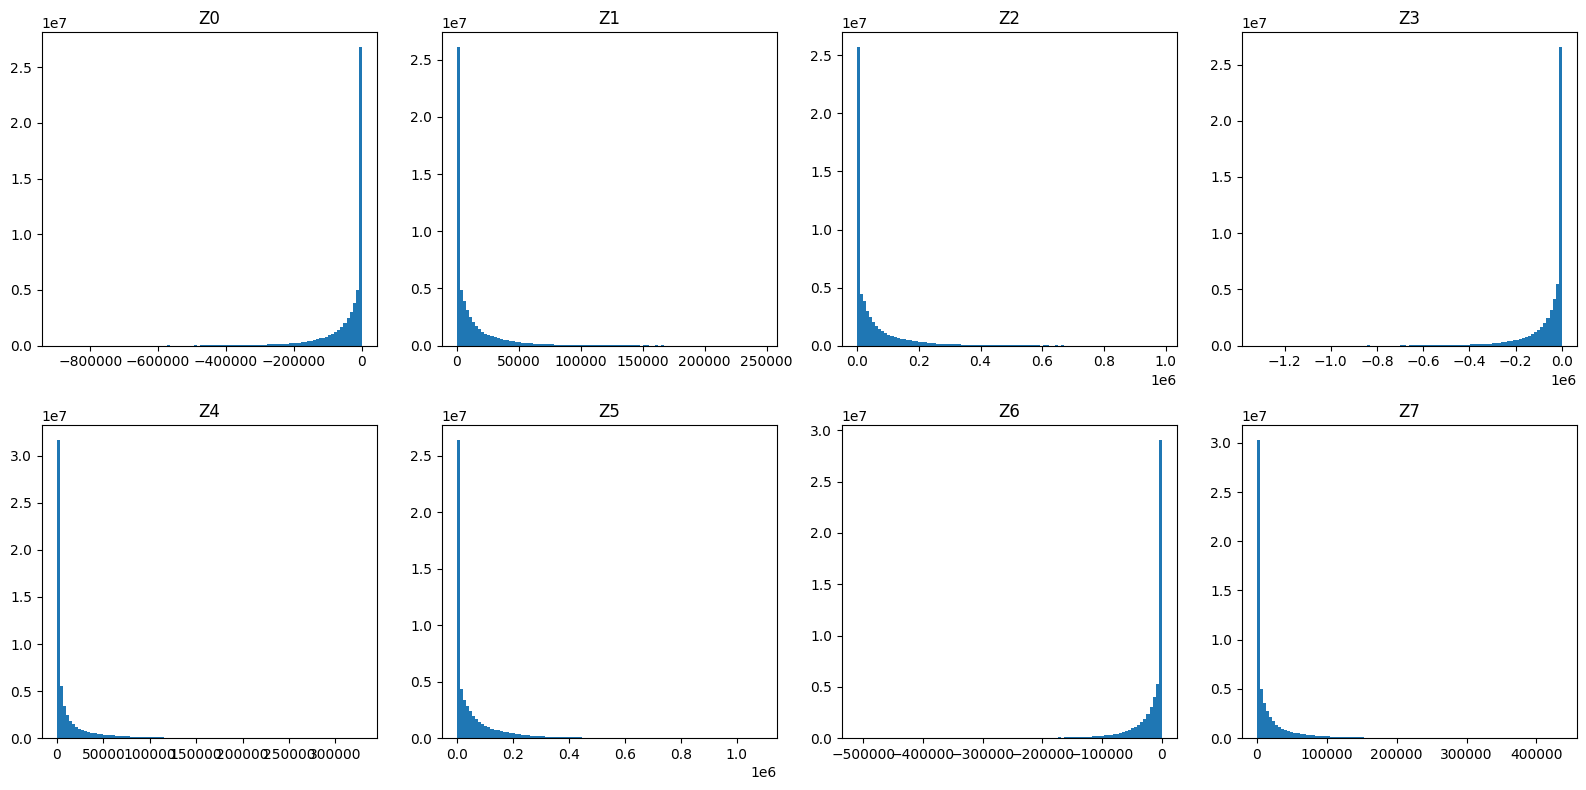

In [ ]:
# old

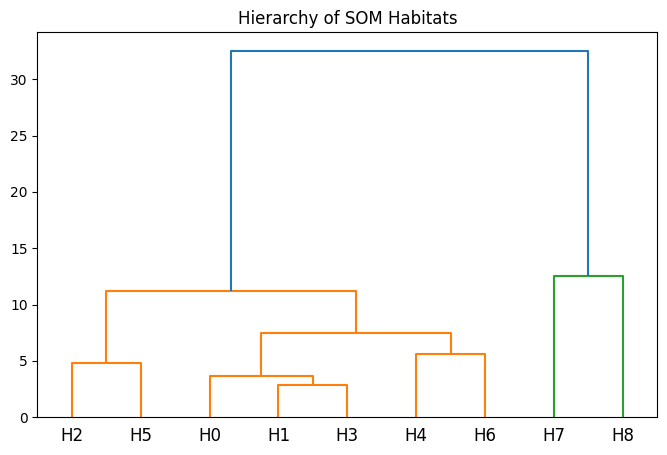

In [863]:
from scipy.cluster.hierarchy import linkage, dendrogram

weights = som_3x3.get_weights().reshape(-1, 8)

plt.figure(figsize=(8,5))

dendrogram(
    linkage(weights, method="ward"),
    labels=[f"H{i}" for i in range(9)]
)

plt.title("Hierarchy of SOM Habitats")
plt.show()

In [399]:
som_3x3.get_weights()

array([[[  1.25798253,  -1.17073244,  -0.28710977,  -2.82310975,
          -0.03013126,   1.30934656,  -2.24206093,   0.18967955],
        [  2.03284732,  -1.28808983,  -0.89027132,  -5.13083836,
          -0.13917325,   2.96100728,  -4.03702637,  -0.82857784],
        [  2.80407177,  -1.46516507,  -1.66872044,  -7.68367294,
          -0.24568973,   4.86454646,  -5.768556  ,  -2.37210751]],

       [[  2.19696006,  -2.36686616,   0.39509478,  -4.77661643,
           0.31947431,   1.9618508 ,  -4.05297779,   1.23233885],
        [  3.20572826,  -3.67917642,   1.13636942,  -7.293958  ,
           1.00126382,   3.22031194,  -6.17974535,   1.75273031],
        [  4.30129052,  -2.6664581 ,  -0.80276691, -10.09137372,
           0.23949001,   5.66899794,  -8.65036982,  -0.51849804]],

       [[  3.79817173,  -1.51543397,  -0.59184831,  -4.61162486,
          -0.33334768,   0.66768605,  -6.21358312,   4.55338697],
        [  7.4057012 ,  -6.72211172,   1.80922276, -13.01787977,
           2.3

In [823]:
som_2x2.get_weights()

array([[[  5.45603913,  -3.32839983,   0.11613584, -12.27101555,
          -0.48411346,   6.19941094, -11.59193803,   2.45261635],
        [  2.53524429,  -1.04989773,  -1.2700723 ,  -6.79720866,
          -1.00443367,   4.05543039,  -5.68957336,  -0.53897044]],

       [[  2.26862176,  -2.30667143,   0.44120036,  -5.58600022,
           0.06008664,   2.63304144,  -4.82178089,   1.32082959],
        [  1.78042125,  -0.97488517,  -0.6831786 ,  -3.70964763,
          -0.41736318,   1.74846286,  -3.40989604,   0.57551324]]])

In [ ]:
# $gb infer

In [ ]:
# gb$

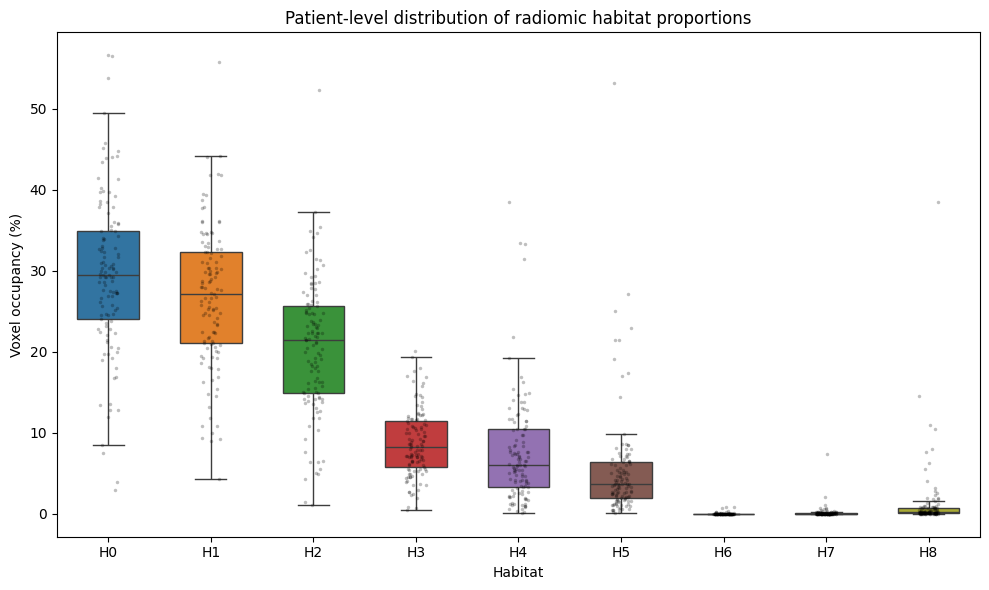

In [1106]:
import matplotlib.pyplot as plt
import seaborn as sns

# H0-H8 habitat proportion columns
habitat_cols = [f"H{i}_proportion" for i in range(9)]

# Convert proportion to percentage
plot_df = tmh_train_features[habitat_cols].copy() * 100
plot_df.columns = [f"H{i}" for i in range(9)]

# Plot
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=plot_df,
    width=0.6,
    fliersize=0
)

sns.stripplot(
    data=plot_df,
    color="black",
    alpha=0.25,
    size=2.5
)

plt.xlabel("Habitat")
plt.ylabel("Voxel occupancy (%)")
plt.title("Patient-level distribution of radiomic habitat proportions")

plt.tight_layout()
plt.show()

### gb cross cohort analysis

In [ ]:
X_tmh_train
X_tmh_test
z_scaler_tmh
ae_tmh
tmh_som_3x3

In [911]:
X_tmh_train

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], dtype=float32)

array([3.8100810e+00, 3.5925925e+00, 4.5294924e+00, 2.0719260e+03,
       4.9803109e+04, 1.3597258e-02, 6.3882733e-05, 1.4592755e-01,
       3.7125992e+02, 6.3882733e-05], dtype=float32)

In [912]:
X_tmh_train.shape

(21252318, 10)

In [913]:
X_tmh_test

array([[-2.7959719 , -1.5526915 , -0.789277  , ..., -1.3197649 ,
        -0.81245035, -0.4522547 ],
       [-2.7959719 , -1.5526915 , -0.789277  , ..., -1.3197649 ,
        -0.81245035, -0.4522547 ],
       [-2.7959719 , -1.5526915 , -0.789277  , ..., -1.3197649 ,
        -0.81245035, -0.4522547 ],
       ...,
       [-2.7959719 , -1.5526915 , -0.789277  , ..., -1.3197649 ,
        -0.81245035, -0.4522547 ],
       [-2.7959719 , -1.5526915 , -0.789277  , ..., -1.3197649 ,
        -0.81245035, -0.4522547 ],
       [-2.7959719 , -1.5526915 , -0.789277  , ..., -1.3197649 ,
        -0.81245035, -0.4522547 ]], dtype=float32)

In [917]:
X_tmh_test.shape

(8804043, 10)

In [973]:
X_lung_test_scaled_tmh

array([[-2.817594 , -1.4932722, -0.8477028, ..., -1.170432 , -0.7873331,
        -0.3475832],
       [-2.817594 , -1.4932722, -0.8477028, ..., -1.170432 , -0.7873331,
        -0.3475832],
       [-2.817594 , -1.4932722, -0.8477028, ..., -1.170432 , -0.7873331,
        -0.3475832],
       ...,
       [-2.817594 , -1.4932722, -0.8477028, ..., -1.170432 , -0.7873331,
        -0.3475832],
       [-2.817594 , -1.4932722, -0.8477028, ..., -1.170432 , -0.7873331,
        -0.3475832],
       [-2.817594 , -1.4932722, -0.8477028, ..., -1.170432 , -0.7873331,
        -0.3475832]], dtype=float32)

In [971]:
X_lung_test_scaled_tmh.shape

NameError: name 'X_lung_test_scaled_tmh' is not defined

In [ ]:
## load the final tmh model

In [926]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ae_tmh = AE().to(device)

checkpoint = torch.load(
    "tmh_ae_final.pth",
    map_location=device
)

ae_tmh.load_state_dict(checkpoint)

ae_tmh.eval()

print("TMH AE loaded successfully")

TMH AE loaded successfully


In [927]:
print(type(checkpoint))

if isinstance(checkpoint, dict):
    print(checkpoint.keys())

<class 'collections.OrderedDict'>
odict_keys(['enc.0.weight', 'enc.0.bias', 'enc.2.weight', 'enc.2.bias', 'enc.4.weight', 'enc.4.bias', 'enc.6.weight', 'enc.6.bias', 'dec.0.weight', 'dec.0.bias', 'dec.2.weight', 'dec.2.bias', 'dec.4.weight', 'dec.4.bias', 'dec.6.weight', 'dec.6.bias'])


In [983]:
Z_tmh = get_latent(
    ae_tmh,
    X_tmh_train_scaled
)

print("TMH latent shape:", Z_tmh.shape)

  0%|          | 0/163 [00:00<?, ?it/s]

TMH latent shape: (21252318, 8)


In [974]:
# Then encode LUNG1

Z_lung_test_tmh = get_latent(
    ae_tmh,
    X_lung_test_scaled_tmh
)

print("LUNG1 latent shape:", Z_lung_test_tmh.shape)

  0%|          | 0/118 [00:00<?, ?it/s]

LUNG1 latent shape: (15405803, 8)


In [930]:
print("Shape:", Z_lung_test_tmh.shape)
print("NaN:", np.isnan(Z_lung_test_tmh).sum())
print("Inf:", np.isinf(Z_lung_test_tmh).sum())
print("Min:", Z_lung_test_tmh.min(axis=0))
print("Max:", Z_lung_test_tmh.max(axis=0))

Shape: (15405803, 8)
NaN: 0
Inf: 0
Min: [ 2.8177443e+00 -8.3702370e+01 -1.5430294e+04 -7.4768812e+04
 -3.0000467e+04 -1.8478652e+00 -7.4334766e+04 -2.5493710e+00]
Max: [ 2.1713359e+04  9.2028721e+03  1.3816698e+01 -2.1284380e+00
  6.4663841e+01  5.2138266e+04 -4.0519361e+00  7.2004624e+03]


In [976]:
tmh_som_3x3 = som_models["3x3"]

In [977]:
lung1_bmu = np.array([
    tmh_som_3x3.winner(z)
    for z in Z_lung_test_tmh
])

In [978]:
weights = tmh_som_3x3.get_weights()   # (3, 3, 8)

weights_flat = weights.reshape(-1, 8)

# Process in chunks to avoid excessive RAM
chunk_size = 500_000

lung1_labels = np.empty(
    len(Z_lung_test_tmh),
    dtype=np.int8
)

for start in range(0, len(Z_lung_test_tmh), chunk_size):

    end = min(start + chunk_size, len(Z_lung_test_tmh))

    Z_chunk = Z_lung_test_tmh[start:end]

    distances = (
        ((Z_chunk[:, None, :] - weights_flat[None, :, :]) ** 2)
        .sum(axis=2)
    )

    lung1_labels[start:end] = np.argmin(
        distances,
        axis=1
    )

print("LUNG1 habitat labels:", lung1_labels.shape)
print("Habitats:", np.unique(lung1_labels))

LUNG1 habitat labels: (15405803,)
Habitats: [0 1 2 3 4 5 6 7 8]


In [988]:
unique, counts = np.unique(
    lung1_labels,
    return_counts=True
)
print("Lung1 habitat occupancy:")
for h, c in zip(unique, counts):
    print(
        f"H{h}: {c:,} voxels "
        f"({100*c/len(lung1_labels):.2f}%)"
    )

Lung1 habitat occupancy:
H0: 2,724,620 voxels (17.69%)
H1: 3,677,266 voxels (23.87%)
H2: 3,210,229 voxels (20.84%)
H3: 1,156,795 voxels (7.51%)
H4: 912,037 voxels (5.92%)
H5: 1,514,494 voxels (9.83%)
H6: 1,712,124 voxels (11.11%)
H7: 211,446 voxels (1.37%)
H8: 286,792 voxels (1.86%)


In [986]:
tmh_labels = np.empty(
    len(Z_tmh),
    dtype=np.int8
)

weights = tmh_som_3x3.get_weights().reshape(-1, 8)

chunk_size = 500_000

for start in range(0, len(Z_tmh), chunk_size):

    end = min(start + chunk_size, len(Z_tmh))

    Z_chunk = Z_tmh[start:end]

    distances = (
        ((Z_chunk[:, None, :] - weights[None, :, :]) ** 2)
        .sum(axis=2)
    )

    tmh_labels[start:end] = np.argmin(
        distances,
        axis=1
    )

print("TMH labels:", tmh_labels.shape)
print("Habitats:", np.unique(tmh_labels))

TMH labels: (21252318,)
Habitats: [0 1 2 3 4 5 6 7 8]


In [987]:
unique, counts = np.unique(
    tmh_labels,
    return_counts=True
)

print("TMH habitat occupancy:")

for h, c in zip(unique, counts):
    print(
        f"H{h}: {c:,} voxels "
        f"({100*c/len(tmh_labels):.2f}%)"
    )

TMH habitat occupancy:
H0: 4,661,280 voxels (21.93%)
H1: 4,499,548 voxels (21.17%)
H2: 3,331,677 voxels (15.68%)
H3: 2,073,903 voxels (9.76%)
H4: 2,329,308 voxels (10.96%)
H5: 819,084 voxels (3.85%)
H6: 2,245,099 voxels (10.56%)
H7: 647,915 voxels (3.05%)
H8: 644,504 voxels (3.03%)


In [981]:
# lung1 bmu distance

weights = tmh_som_3x3.get_weights().reshape(-1, 8)

chunk_size = 500_000
min_dist_lung1 = np.empty(
    len(Z_lung_test_tmh),
    dtype=np.float32
)

for start in range(0, len(Z_lung_test_tmh), chunk_size):

    end = min(start + chunk_size, len(Z_lung_test_tmh))

    Z_chunk = Z_lung_test_tmh[start:end]

    distances = np.sqrt(
        ((Z_chunk[:, None, :] - weights[None, :, :]) ** 2)
        .sum(axis=2)
    )

    min_dist_lung1[start:end] = distances.min(axis=1)

print("LUNG1 BMU distance")
print("Mean   :", min_dist_lung1.mean())
print("Median :", np.median(min_dist_lung1))
print("95%    :", np.percentile(min_dist_lung1, 95))
print("99%    :", np.percentile(min_dist_lung1, 99))

LUNG1 BMU distance
Mean   : 3.083398
Median : 2.348999
95%    : 7.0196526527404615
99%    : 16.467620582580572


In [984]:
# tmh bmu distance

weights = tmh_som_3x3.get_weights().reshape(-1, 8)

chunk_size = 500_000

min_dist_tmh = np.empty(
    len(Z_tmh),
    dtype=np.float32
)

for start in range(0, len(Z_tmh), chunk_size):

    end = min(start + chunk_size, len(Z_tmh))

    Z_chunk = Z_tmh[start:end]

    distances = np.sqrt(
        ((Z_chunk[:, None, :] - weights[None, :, :]) ** 2)
        .sum(axis=2)
    )

    min_dist_tmh[start:end] = distances.min(axis=1)

print("TMH BMU distance")
print("Mean   :", min_dist_tmh.mean())
print("Median :", np.median(min_dist_tmh))
print("95%    :", np.percentile(min_dist_tmh, 95))
print("99%    :", np.percentile(min_dist_tmh, 99))

TMH BMU distance
Mean   : 2.9926705
Median : 2.0794072
95%    : 5.906804370880124
99%    : 18.316345558166347


In [ ]:
### quantify occupancy similarity

In [989]:
from scipy.spatial.distance import jensenshannon
import numpy as np

tmh_prop = np.array([
    0.2193, 0.2117, 0.1568,
    0.0976, 0.1096, 0.0385,
    0.1056, 0.0305, 0.0303
])

lung1_prop = np.array([
    0.1769, 0.2387, 0.2084,
    0.0751, 0.0592, 0.0983,
    0.1111, 0.0137, 0.0186
])

js_distance = jensenshannon(
    tmh_prop,
    lung1_prop
)

print("Jensen-Shannon distance:", js_distance)

Jensen-Shannon distance: 0.13063676916610714


In [ ]:
########### debugging

In [948]:
print(selected_features)
print(X_tmh_train.shape)
print(X_lung_test.shape)

['H6_components', 'H4_components', 'H7_volume_mm3', 'H7_components', 'H2_proportion', 'transition_entropy', 'H4_largest_component_fraction', 'H7_proportion', 'H6_proportion', 'H5_components', 'H3_proportion', 'H7_largest_component_fraction', 'H4_proportion', 'H6_volume_mm3', 'H2_largest_component_fraction', 'H6_largest_component_fraction', 'H5_proportion', 'habitat_entropy', 'H8_volume_mm3']
(21252318, 10)
(15405803, 10)


In [949]:
print("RAW LUNG1")
print("mean:", X_lung_test.mean(axis=0))
print("std :", X_lung_test.std(axis=0))

print("\nTMH")
print("mean:", X_tmh_train.mean(axis=0))
print("std :", X_tmh_train.std(axis=0))

RAW LUNG1
mean: [ 0.00672236  0.01735842 -0.06322096 -0.05195644 -0.13640171  0.00045837
 -0.01278619  0.03530965 -0.12460109  0.1847194 ]
std : [1.00691    1.0087311  0.90134275 0.76373744 0.78769237 0.59881294
 0.35646355 1.0026143  0.8684138  1.1484829 ]

TMH
mean: [3.4155025e+00 5.7076249e+00 5.4988146e+00 1.6037353e+04 4.8839473e+04
 2.1448910e-01 7.7823631e-02 2.6228502e-01 4.0799545e+02 7.4173760e-04]
std : [1.2122064e+00 3.8222272e+00 6.4867311e+00 4.4447055e+04 7.1353180e+04
 1.9546751e+00 1.4095534e+00 2.2409219e-01 5.1819904e+02 2.1339857e-03]


In [950]:
print("TMH scaler mean:")
print(z_scaler_tmh.mean_)

print("\nTMH scaler scale:")
print(z_scaler_tmh.scale_)

TMH scaler mean:
[3.41550415e+00 5.70762463e+00 5.49882107e+00 1.60373439e+04
 4.88394034e+04 2.14489056e-01 7.78236870e-02 2.62284870e-01
 4.07995156e+02 7.41737606e-04]

TMH scaler scale:
[1.21220589e+00 3.82222643e+00 6.48673255e+00 4.44470526e+04
 7.13531631e+04 1.95467504e+00 1.40956393e+00 2.24092364e-01
 5.18198926e+02 2.13398570e-03]


In [951]:
manual = (
    X_lung_test.mean(axis=0) - z_scaler_tmh.mean_
) / z_scaler_tmh.scale_

print(manual)

[-2.81204853e+00 -1.48873080e+00 -8.57448952e-01 -3.60820233e-01
 -6.84476170e-01 -1.09496811e-01 -6.42822059e-02 -1.01286458e+00
 -7.87573530e-01  8.62131647e+01]


In [952]:
X_lung_test_scaled_tmh.mean(axis=0)

array([-2.81204939e+00, -1.48873234e+00, -8.57448757e-01, -3.60826135e-01,
       -6.84466124e-01, -1.09496884e-01, -6.42821565e-02, -1.01286495e+00,
       -7.87574589e-01,  8.62132187e+01], dtype=float32)

In [953]:
print("FEATURES:")
print(selected_features)

print("\nRAW LUNG1:")
print("mean:", X_lung_test.mean(axis=0))
print("std :", X_lung_test.std(axis=0))

print("\nTMH SCALER:")
print("mean:", z_scaler_tmh.mean_)
print("scale:", z_scaler_tmh.scale_)

FEATURES:
['H6_components', 'H4_components', 'H7_volume_mm3', 'H7_components', 'H2_proportion', 'transition_entropy', 'H4_largest_component_fraction', 'H7_proportion', 'H6_proportion', 'H5_components', 'H3_proportion', 'H7_largest_component_fraction', 'H4_proportion', 'H6_volume_mm3', 'H2_largest_component_fraction', 'H6_largest_component_fraction', 'H5_proportion', 'habitat_entropy', 'H8_volume_mm3']

RAW LUNG1:
mean: [ 0.00672236  0.01735842 -0.06322096 -0.05195644 -0.13640171  0.00045837
 -0.01278619  0.03530965 -0.12460109  0.1847194 ]
std : [1.00691    1.0087311  0.90134275 0.76373744 0.78769237 0.59881294
 0.35646355 1.0026143  0.8684138  1.1484829 ]

TMH SCALER:
mean: [3.41550415e+00 5.70762463e+00 5.49882107e+00 1.60373439e+04
 4.88394034e+04 2.14489056e-01 7.78236870e-02 2.62284870e-01
 4.07995156e+02 7.41737606e-04]
scale: [1.21220589e+00 3.82222643e+00 6.48673255e+00 4.44470526e+04
 7.13531631e+04 1.95467504e+00 1.40956393e+00 2.24092364e-01
 5.18198926e+02 2.13398570e-03]


In [955]:
X_lung_test.shape

(15405803, 10)

In [956]:
print("X_lung_test_scaled_tmh shape:",
      X_lung_test_scaled_tmh.shape)

X_lung_test_scaled_tmh shape: (15405803, 10)


In [957]:
print("First 5 rows:")
print(X_lung_test_scaled_tmh[:5])

First 5 rows:
[[-5.1241097e+00 -1.8994992e+00 -9.6937829e-01 -3.6082640e-01
  -6.8448269e-01 -1.6530256e-01 -9.1261610e-02 -7.0598111e+00
  -7.8890091e-01 -2.1227718e+02]
 [-5.1241097e+00 -1.8994992e+00 -9.6937829e-01 -3.6082640e-01
  -6.8448269e-01 -1.6530256e-01 -9.1261610e-02 -7.0598111e+00
  -7.8890091e-01 -2.1227718e+02]
 [-5.1241097e+00 -1.8994992e+00 -9.6937829e-01 -3.6082640e-01
  -6.8448269e-01 -1.6530256e-01 -9.1261610e-02 -7.0598111e+00
  -7.8890091e-01 -2.1227718e+02]
 [-5.1241097e+00 -1.8994992e+00 -9.6937829e-01 -3.6082640e-01
  -6.8448269e-01 -1.6530256e-01 -9.1261610e-02 -7.0598111e+00
  -7.8890091e-01 -2.1227718e+02]
 [-5.1241097e+00 -1.8994992e+00 -9.6937829e-01 -3.6082640e-01
  -6.8448269e-01 -1.6530256e-01 -9.1261610e-02 -7.0598111e+00
  -7.8890091e-01 -2.1227718e+02]]


In [959]:
for name, obj in globals().items():
    try:
        if hasattr(obj, "shape") and obj.shape == (15405803, 10):
            print(name, obj.shape)
    except:
        pass

X_lung_test (15405803, 10)
X_lung_test_scaled_tmh (15405803, 10)
_921 (15405803, 10)
_922 (15405803, 10)
_954 (15405803, 10)


In [961]:
candidates = [
    ("X_lung_test", X_lung_test),
    ("X_lung_test_scaled_tmh", X_lung_test_scaled_tmh),
    ("_921", _921),
    ("_922", _922),
    ("_954", _954),
]

for name, arr in candidates:
    print("\n", "="*60)
    print(name)
    print("shape:", arr.shape)
    print("mean:", arr.mean(axis=0))
    print("std :", arr.std(axis=0))
    print("min :", arr.min(axis=0))
    print("max :", arr.max(axis=0))


X_lung_test
shape: (15405803, 10)
mean: [ 0.00672236  0.01735842 -0.06322096 -0.05195644 -0.13640171  0.00045837
 -0.01278619  0.03530965 -0.12460109  0.1847194 ]
std : [1.00691    1.0087311  0.90134275 0.76373744 0.78769237 0.59881294
 0.35646355 1.0026143  0.8684138  1.1484829 ]
min : [-2.7959719  -1.5526915  -0.789277   -0.32549995 -0.60044384 -0.10862374
 -0.05081539 -1.3197649  -0.81245035 -0.4522547 ]
max : [ 1.0622422  5.2624946  4.789497  16.443962   9.560196  35.340054
 22.988611   3.0950418 14.036223  58.298454 ]

X_lung_test_scaled_tmh
shape: (15405803, 10)
mean: [-2.81204939e+00 -1.48873234e+00 -8.57448757e-01 -3.60826135e-01
 -6.84466124e-01 -1.09496884e-01 -6.42821565e-02 -1.01286495e+00
 -7.87574589e-01  8.62132187e+01]
std : [8.3064348e-01 2.6391223e-01 1.3895167e-01 1.8168250e-05 1.4927510e-05
 3.0634904e-01 2.5288919e-01 4.4741139e+00 1.6758315e-03 5.3818689e+02]
min : [-5.1241097e+00 -1.8994992e+00 -9.6937829e-01 -3.6082640e-01
 -6.8448269e-01 -1.6530256e-01 -9.1261

In [962]:
X_lung_test_raw

NameError: name 'X_lung_test_raw' is not defined

In [ ]:
# train Lung1






In [1026]:
X_lung_train.shape

(35771520, 10)

In [1029]:
X_lung_test

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], dtype=float32)

In [1027]:
X_tmh_test.shape

(8804043, 10)

In [1028]:
X_tmh_train

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], dtype=float32)

In [1031]:
X_tmh_test

array([[-2.7959719 , -1.5526915 , -0.789277  , ..., -1.3197649 ,
        -0.81245035, -0.4522547 ],
       [-2.7959719 , -1.5526915 , -0.789277  , ..., -1.3197649 ,
        -0.81245035, -0.4522547 ],
       [-2.7959719 , -1.5526915 , -0.789277  , ..., -1.3197649 ,
        -0.81245035, -0.4522547 ],
       ...,
       [-2.7959719 , -1.5526915 , -0.789277  , ..., -1.3197649 ,
        -0.81245035, -0.4522547 ],
       [-2.7959719 , -1.5526915 , -0.789277  , ..., -1.3197649 ,
        -0.81245035, -0.4522547 ],
       [-2.7959719 , -1.5526915 , -0.789277  , ..., -1.3197649 ,
        -0.81245035, -0.4522547 ]], dtype=float32)

#### lung_train tmh test

In [1097]:
### gb habitat quantifiaction plot

import matplotlib.pyplot as plt
import seaborn as sns

# Replace with your actual dataframe name
df = habitat_features_df

# Habitat proportion columns
habitat_cols = [f"H{i}_proportion" for i in range(9)]

# Convert to percentage
plot_df = df[habitat_cols].copy() * 100
plot_df.columns = [f"H{i}" for i in range(9)]

# Boxplot
plt.figure(figsize=(11, 6))

sns.boxplot(data=plot_df)

plt.xlabel("Habitat")
plt.ylabel("Voxel occupancy (%)")
plt.title("Patient-level distribution of habitat proportions")

plt.tight_layout()
plt.show()

NameError: name 'habitat_features_df' is not defined

In [1099]:
# to check all dfs
import pandas as pd

# Find all pandas DataFrames currently in memory
dfs = {
    name: obj
    for name, obj in globals().items()
    if isinstance(obj, pd.DataFrame)
}

print("DataFrames found:")
for name, df in dfs.items():
    print(f"\n{name}: shape={df.shape}")
    print(df.columns.tolist()[:15])

DataFrames found:

__: shape=(1, 7)
['Grid', 'QE', 'TE', 'Silhouette', 'DBI', 'CHI', 'Total_time_in_mins']

___: shape=(1, 7)
['Grid', 'QE', 'TE', 'Silhouette', 'DBI', 'CHI', 'Total_time_in_mins']

results: shape=(9, 4)
['TMH_habitat', 'LUNG1_habitat', 'Spearman_rho', 'Candidate_conserved']

som_results: shape=(5, 7)
['Grid', 'QE', 'TE', 'Silhouette', 'DBI', 'CHI', 'Total_time_in_mins']

_55: shape=(1, 7)
['Grid', 'QE', 'TE', 'Silhouette', 'DBI', 'CHI', 'Total_time_in_mins']

_58: shape=(1, 7)
['Grid', 'QE', 'TE', 'Silhouette', 'DBI', 'CHI', 'Total_time_in_mins']

occupancy_22: shape=(4, 3)
['Habitat', 'Count', 'Percent']

_146: shape=(117, 23)
['patient_id', 'H0_proportion', 'H0_volume_mm3', 'H1_proportion', 'H1_volume_mm3', 'H2_proportion', 'H2_volume_mm3', 'H3_proportion', 'H3_volume_mm3', 'habitat_entropy', 'occupied_habitats', 'H0_components', 'H0_largest_component_fraction', 'H1_components', 'H1_largest_component_fraction']

gb_tmh_train_surv: shape=(117, 3)
['Patient', 'time', '

In [1102]:
tmh_train_features.shape

(117, 43)

In [1098]:
features

{'H0_proportion': 0.3012299741602067,
 'H0_volume_mm3': 233152.0,
 'H1_proportion': 0.3276485788113695,
 'H1_volume_mm3': 253600.0,
 'H2_proportion': 0.22352454780361758,
 'H2_volume_mm3': 173008.0,
 'H3_proportion': 0.08632558139534884,
 'H3_volume_mm3': 66816.0,
 'H4_proportion': 0.042160206718346256,
 'H4_volume_mm3': 32632.0,
 'H5_proportion': 0.0182015503875969,
 'H5_volume_mm3': 14088.0,
 'H6_proportion': 0.0,
 'H6_volume_mm3': 0.0,
 'H7_proportion': 6.201550387596899e-05,
 'H7_volume_mm3': 48.0,
 'H8_proportion': 0.0008475452196382429,
 'H8_volume_mm3': 656.0,
 'habitat_entropy': 2.1444208298373364,
 'occupied_habitats': 8,
 'H0_components': 479,
 'H0_largest_component_fraction': 0.9080771342300302,
 'H1_components': 493,
 'H1_largest_component_fraction': 0.9660567823343849,
 'H2_components': 263,
 'H2_largest_component_fraction': 0.9720244150559512,
 'H3_components': 1347,
 'H3_largest_component_fraction': 0.21851053639846743,
 'H4_components': 530,
 'H4_largest_component_fract

NameError: name 'plot_df' is not defined

In [1058]:
# ============================================================
# LUNG1 → TMH FROZEN CROSS-COHORT TRANSFER
# ============================================================

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from minisom import MiniSom
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment
import joblib
import pickle
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 0. CHECK INPUTS
# ------------------------------------------------------------

assert "X_lung_train" in globals(), "X_lung_train is missing"
assert "X_tmh_test_raw" in globals(), "X_tmh_test_raw is missing"

print("LUNG1 train:", X_lung_train.shape)
print("TMH test raw:", X_tmh_test_raw.shape)

LUNG1 train: (35771520, 10)
TMH test raw: (8804043, 10)


In [1057]:
X_tmh_test_raw

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], dtype=float32)

In [1045]:
X_tmh_test_scaled

array([[  -5.1241097,   -1.8994992,   -0.9693783, ...,   -7.059811 ,
          -0.7889009, -212.27718  ],
       [  -5.1241097,   -1.8994992,   -0.9693783, ...,   -7.059811 ,
          -0.7889009, -212.27718  ],
       [  -5.1241097,   -1.8994992,   -0.9693783, ...,   -7.059811 ,
          -0.7889009, -212.27718  ],
       ...,
       [  -5.1241097,   -1.8994992,   -0.9693783, ...,   -7.059811 ,
          -0.7889009, -212.27718  ],
       [  -5.1241097,   -1.8994992,   -0.9693783, ...,   -7.059811 ,
          -0.7889009, -212.27718  ],
       [  -5.1241097,   -1.8994992,   -0.9693783, ...,   -7.059811 ,
          -0.7889009, -212.27718  ]], dtype=float32)

In [1048]:
# Make sure everything is finite
assert np.isfinite(X_lung_train).all(), "NaN/Inf in X_lung_train"
assert np.isfinite(X_tmh_test_raw).all(), "NaN/Inf in X_tmh_test_raw"

In [1059]:
# ------------------------------------------------------------
# 1. Z-SCORE FIT ON LUNG1 TRAINING ONLY
# ------------------------------------------------------------

z_scaler_lung = StandardScaler()

X_lung_train_scaled = z_scaler_lung.fit_transform(
    X_lung_train
).astype(np.float32, copy=False)

X_tmh_test_scaled_lung = z_scaler_lung.transform(
    X_tmh_test_raw
).astype(np.float32, copy=False)

In [1060]:
X_tmh_test_raw.shape

(8804043, 10)

In [1061]:
print("\nLUNG1 scaled mean:", X_lung_train_scaled.mean(axis=0))
print("LUNG1 scaled std :", X_lung_train_scaled.std(axis=0))

print("\nTMH transformed mean:", X_tmh_test_scaled_lung.mean(axis=0))
print("TMH transformed std :", X_tmh_test_scaled_lung.std(axis=0))

# Save scaler
joblib.dump(z_scaler_lung, "lung1_z_scaler.pkl")


# ------------------------------------------------------------
# 2. AUTOENCODER
#    EXACT SAME ARCHITECTURE AS TMH MODEL
# ------------------------------------------------------------

class AE(nn.Module):
    def __init__(self):
        super().__init__()

        self.enc = nn.Sequential(
            nn.Linear(10, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 8)
        )

        self.dec = nn.Sequential(
            nn.Linear(8, 16),
            nn.ReLU(),

            nn.Linear(16, 32),
            nn.ReLU(),

            nn.Linear(32, 64),
            nn.ReLU(),

            nn.Linear(64, 10)
        )

    def forward(self, x):
        z = self.enc(x)
        out = self.dec(z)
        return out, z


class VoxDataset(Dataset):
    def __init__(self, X):
        self.X = X

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return torch.from_numpy(self.X[idx])


LUNG1 scaled mean: [ 1.0025925e-08  6.8591249e-10 -3.3485158e-08 -2.1526050e-08
  2.8685475e-08 -7.9204128e-09  1.2003468e-08  8.5039504e-09
  1.1070150e-08  2.2691419e-08]
LUNG1 scaled std : [1.0000006  0.9999995  1.0000001  0.99999905 1.0000001  0.9999999
 1.         1.0000004  0.9999999  1.0000001 ]

TMH transformed mean: [-0.00806062 -0.10824303  0.35195857  0.38584232  0.47126168  0.08176016
  0.22913429 -0.16022468  0.0361376  -0.14646463]
TMH transformed std : [0.9719291 0.9776379 1.4141725 1.863709  1.6305809 1.9114635 3.487991
 1.0111175 1.0478842 1.0741366]


In [1063]:
# ------------------------------------------------------------
# 3. TRAIN LUNG1 AE
# ------------------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("\nDevice:", device)

ae_lung = AE().to(device)

optimizer = torch.optim.Adam(
    ae_lung.parameters(),
    lr=1e-4
)

loss_l1 = nn.L1Loss()
loss_mse = nn.MSELoss()

# Keep this consistent with your large-voxel workflow
MAX_AE_TRAIN = min(10_000_000, len(X_lung_train_scaled))

rng = np.random.default_rng(88)

if len(X_lung_train_scaled) > MAX_AE_TRAIN:
    ae_idx = rng.choice(
        len(X_lung_train_scaled),
        MAX_AE_TRAIN,
        replace=False
    )
    X_lung_ae_train = X_lung_train_scaled[ae_idx]
else:
    X_lung_ae_train = X_lung_train_scaled

print("\nAE training voxels:", len(X_lung_ae_train))

loader = DataLoader(
    VoxDataset(X_lung_ae_train),
    batch_size=131072,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

EPOCHS = 100

amp_scaler = torch.cuda.amp.GradScaler(
    enabled=torch.cuda.is_available()
)

ae_lung.train()

for epoch in range(EPOCHS):

    running_loss = 0.0

    pbar = tqdm(
        loader,
        desc=f"AE Epoch {epoch+1}/{EPOCHS}",
        leave=False
    )

    for x in pbar:

        x = x.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast(
            enabled=torch.cuda.is_available()
        ):
            out, z = ae_lung(x)

            loss = (
                0.5 * loss_l1(out, x)
                +
                0.5 * loss_mse(out, x)
            )

        amp_scaler.scale(loss).backward()

        amp_scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            ae_lung.parameters(),
            max_norm=5.0
        )

        amp_scaler.step(optimizer)
        amp_scaler.update()

        running_loss += loss.item()

        pbar.set_postfix(loss=f"{loss.item():.5f}")

    epoch_loss = running_loss / len(loader)

    print(
        f"Epoch {epoch+1:03d}/{EPOCHS} | "
        f"Loss: {epoch_loss:.6f}"
    )

# Save AE
torch.save(
    {
        "model_state_dict": ae_lung.state_dict()
    },
    "lung1_ae_final.pth"
)

ae_lung.eval()

print("\nLUNG1 AE training completed.")


Device: cuda

AE training voxels: 10000000


/tmp/ipykernel_2379577/510147394.py:45: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  amp_scaler = torch.cuda.amp.GradScaler(


AE Epoch 1/100:   0%|          | 0/77 [00:00<?, ?it/s]

/tmp/ipykernel_2379577/510147394.py:67: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(


Epoch 001/100 | Loss: 0.781629


AE Epoch 2/100:   0%|          | 0/77 [00:00<?, ?it/s]

... (193 outputs left out)

AE Epoch 99/100:   0%|          | 0/77 [00:00<?, ?it/s]

Epoch 099/100 | Loss: 0.032838


AE Epoch 100/100:   0%|          | 0/77 [00:00<?, ?it/s]

Epoch 100/100 | Loss: 0.032600

LUNG1 AE training completed.


In [1066]:
# ------------------------------------------------------------
# 4. EXTRACT 8-D LATENT REPRESENTATION
# ------------------------------------------------------------

def get_latent(model, X, batch_size=131072):

    ds = VoxDataset(X)

    loader = DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    model.eval()

    z_all = []

    with torch.no_grad():

        for x in tqdm(loader, desc="Extracting latent"):

            x = x.to(device, non_blocking=True)

            z = model.enc(x)

            z_all.append(
                z.cpu().numpy().astype(np.float32)
            )

    return np.vstack(z_all)


print("\nExtracting LUNG1 latent...")
Z_lung_train = get_latent(
    ae_lung,
    X_lung_train_scaled
)

print("LUNG1 latent:", Z_lung_train.shape)

print("\nExtracting TMH-test latent...")
Z_tmh_test_lung = get_latent(
    ae_lung,
    X_tmh_test_scaled_lung
)

print("TMH latent:", Z_tmh_test_lung.shape)


Extracting LUNG1 latent...


Extracting latent:   0%|          | 0/273 [00:00<?, ?it/s]

LUNG1 latent: (35771520, 8)

Extracting TMH-test latent...


Extracting latent:   0%|          | 0/68 [00:00<?, ?it/s]

TMH latent: (8804043, 8)


In [1067]:
# ------------------------------------------------------------
# 5. TRAIN LUNG1 3×3 SOM
# ------------------------------------------------------------

som_train_idx = rng.choice(
    len(Z_lung_train),
    min(100_000, len(Z_lung_train)),
    replace=False
)

X_som_init = Z_lung_train[som_train_idx]

lung_som_3x3 = MiniSom(
    x=3,
    y=3,
    input_len=8,
    sigma=1.0,
    learning_rate=0.5,
    random_seed=42
)

# PCA initialization
lung_som_3x3.pca_weights_init(X_som_init)

print("\nTraining LUNG1 3×3 SOM...")

lung_som_3x3.train_random(
    Z_lung_train,
    500_000,
    verbose=True
)

print("LUNG1 3×3 SOM training completed.")


# ------------------------------------------------------------
# 6. VECTORISED BMU ASSIGNMENT
# ------------------------------------------------------------

def bmu_labels(X, som, batch_size=200_000):

    weights = som.get_weights()

    # shape: (3,3,8) -> (9,8)
    weights = weights.reshape(-1, weights.shape[-1])

    labels = np.empty(
        len(X),
        dtype=np.int16
    )

    for start in tqdm(
        range(0, len(X), batch_size),
        desc="BMU assignment"
    ):

        end = min(
            start + batch_size,
            len(X)
        )

        xb = X[start:end]

        # squared Euclidean distance
        d = (
            np.sum(xb**2, axis=1, keepdims=True)
            +
            np.sum(weights**2, axis=1)[None, :]
            -
            2 * xb @ weights.T
        )

        labels[start:end] = np.argmin(
            d,
            axis=1
        )

    return labels


Training LUNG1 3×3 SOM...
 [ 500000 / 500000 ] 100% - 0:00:00 left 
 quantization error: 3.5363563052097593
LUNG1 3×3 SOM training completed.


In [1069]:
tmh_test_labels_lung

NameError: name 'tmh_test_labels_lung' is not defined

In [1070]:
# ------------------------------------------------------------
# 7. HABITAT LABELS
# ------------------------------------------------------------

print("\nAssigning LUNG1 training habitats...")

lung_train_labels = bmu_labels(
    Z_lung_train,
    lung_som_3x3
)

print("\nAssigning frozen SOM to TMH test...")

tmh_test_labels_lung = bmu_labels(
    Z_tmh_test_lung,
    lung_som_3x3
)


Assigning LUNG1 training habitats...


BMU assignment:   0%|          | 0/179 [00:00<?, ?it/s]


Assigning frozen SOM to TMH test...


BMU assignment:   0%|          | 0/45 [00:00<?, ?it/s]

In [1071]:
# ------------------------------------------------------------
# 8. OCCUPANCY
# ------------------------------------------------------------

def occupancy(labels, n_habitats=9):

    counts = np.bincount(
        labels,
        minlength=n_habitats
    )

    proportions = counts / len(labels)

    return counts, proportions


lung_counts, lung_prop = occupancy(
    lung_train_labels
)

tmh_counts, tmh_prop = occupancy(
    tmh_test_labels_lung
)

print("\n" + "="*60)
print("LUNG1 → TMH HABITAT OCCUPANCY")
print("="*60)

for h in range(9):

    print(
        f"H{h}: "
        f"LUNG1={lung_counts[h]:,} "
        f"({lung_prop[h]*100:.2f}%)   |   "
        f"TMH={tmh_counts[h]:,} "
        f"({tmh_prop[h]*100:.2f}%)"
    )


LUNG1 → TMH HABITAT OCCUPANCY
H0: LUNG1=4,132,395 (11.55%)   |   TMH=961,347 (10.92%)
H1: LUNG1=3,323,553 (9.29%)   |   TMH=871,449 (9.90%)
H2: LUNG1=2,057,015 (5.75%)   |   TMH=707,207 (8.03%)
H3: LUNG1=9,001,508 (25.16%)   |   TMH=2,058,624 (23.38%)
H4: LUNG1=4,783,562 (13.37%)   |   TMH=569,735 (6.47%)
H5: LUNG1=2,178,613 (6.09%)   |   TMH=1,372,761 (15.59%)
H6: LUNG1=6,643,036 (18.57%)   |   TMH=1,582,915 (17.98%)
H7: LUNG1=2,681,214 (7.50%)   |   TMH=506,141 (5.75%)
H8: LUNG1=970,624 (2.71%)   |   TMH=173,864 (1.97%)


In [1075]:
# ------------------------------------------------------------
# 9. QUANTIZATION ERROR
# ------------------------------------------------------------

def quantization_error_vectorized(
    X,
    som,
    batch_size=200_000
):

    weights = som.get_weights().reshape(
        -1,
        som.get_weights().shape[-1]
    )

    total_dist = 0.0
    total_n = 0

    for start in tqdm(
        range(0, len(X), batch_size),
        desc="QE calculation"
    ):

        end = min(
            start + batch_size,
            len(X)
        )

        xb = X[start:end]

        d = (
            np.sum(xb**2, axis=1, keepdims=True)
            +
            np.sum(weights**2, axis=1)[None, :]
            -
            2 * xb @ weights.T
        )

        min_dist = np.sqrt(
            np.maximum(
                np.min(d, axis=1),
                0
            )
        )

        total_dist += min_dist.sum()
        total_n += len(xb)

    return total_dist / total_n


print("\nCalculating source QE...")
qe_lung = quantization_error_vectorized(
    Z_lung_train,
    lung_som_3x3
)

print("LUNG1 train QE:", qe_lung)

print("\nCalculating transferred TMH QE...")
qe_tmh = quantization_error_vectorized(
    Z_tmh_test_lung,
    lung_som_3x3
)

print("TMH transferred QE:", qe_tmh)

qe_change_pct = (
    (qe_tmh - qe_lung)
    / qe_lung
    * 100
)

print(
    f"QE change: {qe_change_pct:.2f}%"
)


Calculating source QE...


QE calculation:   0%|          | 0/179 [00:00<?, ?it/s]

LUNG1 train QE: 3.5363558499613013

Calculating transferred TMH QE...


QE calculation:   0%|          | 0/45 [00:00<?, ?it/s]

TMH transferred QE: 6.9483501098383655
QE change: 96.48%


In [1076]:
# ------------------------------------------------------------
# 10. JENSEN-SHANNON DISTANCE
# ------------------------------------------------------------

def js_distance(p, q):

    p = np.asarray(p, dtype=np.float64)
    q = np.asarray(q, dtype=np.float64)

    # Avoid log(0)
    p = np.clip(p, 1e-12, 1)
    q = np.clip(q, 1e-12, 1)

    p = p / p.sum()
    q = q / q.sum()

    m = 0.5 * (p + q)

    kl_pm = np.sum(
        p * np.log2(p / m)
    )

    kl_qm = np.sum(
        q * np.log2(q / m)
    )

    return np.sqrt(
        0.5 * (kl_pm + kl_qm)
    )


js_lung_tmh = js_distance(
    lung_prop,
    tmh_prop
)

print(
    "\nJensen-Shannon distance:",
    js_lung_tmh
)


Jensen-Shannon distance: 0.16555502382711298


In [1077]:
# ------------------------------------------------------------
# 11. SAVE MODEL OBJECTS
# ------------------------------------------------------------

with open(
    "lung1_som_3x3.pkl",
    "wb"
) as f:

    pickle.dump(
        lung_som_3x3,
        f
    )

In [1078]:
# ------------------------------------------------------------
# 12. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "="*70)
print("FINAL LUNG1 → TMH TRANSFER SUMMARY")
print("="*70)

print(f"LUNG1 source QE      : {qe_lung:.6f}")
print(f"TMH transferred QE   : {qe_tmh:.6f}")
print(f"QE change            : {qe_change_pct:.2f}%")
print(f"JS distance          : {js_lung_tmh:.6f}")

print("\nHabitat retention:")
for h in range(9):

    print(
        f"H{h}: "
        f"{tmh_prop[h]*100:.2f}%"
    )

print("\nAll 9 habitats present in TMH:",
      np.all(tmh_counts > 0))

print("\nSaved:")
print("  lung1_z_scaler.pkl")
print("  lung1_ae_final.pth")
print("  lung1_som_3x3.pkl")


FINAL LUNG1 → TMH TRANSFER SUMMARY
LUNG1 source QE      : 3.536356
TMH transferred QE   : 6.948350
QE change            : 96.48%
JS distance          : 0.165555

Habitat retention:
H0: 10.92%
H1: 9.90%
H2: 8.03%
H3: 23.38%
H4: 6.47%
H5: 15.59%
H6: 17.98%
H7: 5.75%
H8: 1.97%

All 9 habitats present in TMH: True

Saved:
  lung1_z_scaler.pkl
  lung1_ae_final.pth
  lung1_som_3x3.pkl


In [1079]:
print("LUNG1 train raw:")
print(X_lung_train.mean(axis=0))
print(X_lung_train.std(axis=0))

print("\nTMH test raw:")
print(X_tmh_test_raw.mean(axis=0))
print(X_tmh_test_raw.std(axis=0))

print("\nTMH test after LUNG1 scaler:")
print(X_tmh_test_scaled_lung.mean(axis=0))
print(X_tmh_test_scaled_lung.std(axis=0))

print("\nLUNG1 latent:")
print(Z_lung_train.mean(axis=0))
print(Z_lung_train.std(axis=0))

print("\nTMH latent:")
print(Z_tmh_test_lung.mean(axis=0))
print(Z_tmh_test_lung.std(axis=0))

LUNG1 train raw:
[3.4637582e+00 6.4149823e+00 3.2676575e+00 7.5037500e+03 2.2837475e+04
 9.4781123e-02 2.4849799e-02 3.2071832e-01 4.2111703e+02 1.2663208e-03]
[1.2439042e+00 4.0192161e+00 4.0180368e+00 2.2730367e+04 3.7437824e+04
 5.9153694e-01 2.1477546e-01 2.2512619e-01 5.0871661e+02 2.4756200e-03]

TMH test raw:
[3.4537292e+00 5.9799423e+00 4.6818390e+00 1.6274094e+04 4.0480492e+04
 1.4314516e-01 7.4062392e-02 2.8464743e-01 4.3950113e+02 9.0373179e-04]
[1.2089860e+00 3.9293408e+00 5.6821966e+00 4.2362766e+04 6.1045434e+04
 1.1307007e+00 7.4913609e-01 2.2762901e-01 5.3307605e+02 2.6591534e-03]

TMH test after LUNG1 scaler:
[-0.00806062 -0.10824303  0.35195857  0.38584232  0.47126168  0.08176016
  0.22913429 -0.16022468  0.0361376  -0.14646463]
[0.9719291 0.9776379 1.4141725 1.863709  1.6305809 1.9114635 3.487991
 1.0111175 1.0478842 1.0741366]

LUNG1 latent:
[ 2.1132126   3.8079255   5.4046626   2.139874   -2.1392546   1.4616964
  0.27986598  1.1449659 ]
[4.5354934 5.20591   7.80345

In [1080]:
print(X_lung_train.shape)
print(X_tmh_test_raw.shape)
print(np.isfinite(X_lung_train).all())
print(np.isfinite(X_tmh_test_raw).all())

(35771520, 10)
(8804043, 10)
True
True


In [1082]:
print("Feature order:")
print(feature_names)

print("\nLUNG1 scaler means:")
print(z_scaler_lung.mean_)

print("\nLUNG1 scaler scales:")
print(z_scaler_lung.scale_)

Feature order:
['DependenceEntropy', 'DependenceNonUniformity', 'DependenceVariance', 'HighGrayLevelEmphasis', 'LargeDependenceHighGrayLevelEmphasis', 'LargeDependenceLowGrayLevelEmphasis', 'LowGrayLevelEmphasis', 'SmallDependenceEmphasis', 'SmallDependenceHighGrayLevelEmphasis', 'SmallDependenceLowGrayLevelEmphasis']

LUNG1 scaler means:
[3.46375696e+00 6.41499073e+00 3.26765311e+00 7.50375546e+03
 2.28374670e+04 9.47809362e-02 2.48498029e-02 3.20718189e-01
 4.21117228e+02 1.26632243e-03]

LUNG1 scaler scales:
[1.24390380e+00 4.01921613e+00 4.01803641e+00 2.27303538e+04
 3.74378413e+04 5.91536839e-01 2.14775436e-01 2.25126214e-01
 5.08716545e+02 2.47561878e-03]


In [1083]:
# ============================================================
# VERIFY LUNG1 LATENT WAS GENERATED FROM LUNG1 DATA
# ============================================================

print("Current Z_lung_train shape:", Z_lung_train.shape)
print("X_lung_train_scaled shape:", X_lung_train_scaled.shape)

# Re-generate independently
Z_lung_train_check = get_latent(
    ae_lung,
    X_lung_train_scaled
)

print("\nRe-generated shape:", Z_lung_train_check.shape)

# Compare
print(
    "\nMaximum absolute difference:",
    np.max(np.abs(Z_lung_train - Z_lung_train_check))
)

print(
    "Mean absolute difference:",
    np.mean(np.abs(Z_lung_train - Z_lung_train_check))
)

Current Z_lung_train shape: (35771520, 8)
X_lung_train_scaled shape: (35771520, 10)


Extracting latent:   0%|          | 0/273 [00:00<?, ?it/s]


Re-generated shape: (35771520, 8)

Maximum absolute difference: 0.0
Mean absolute difference: 0.0


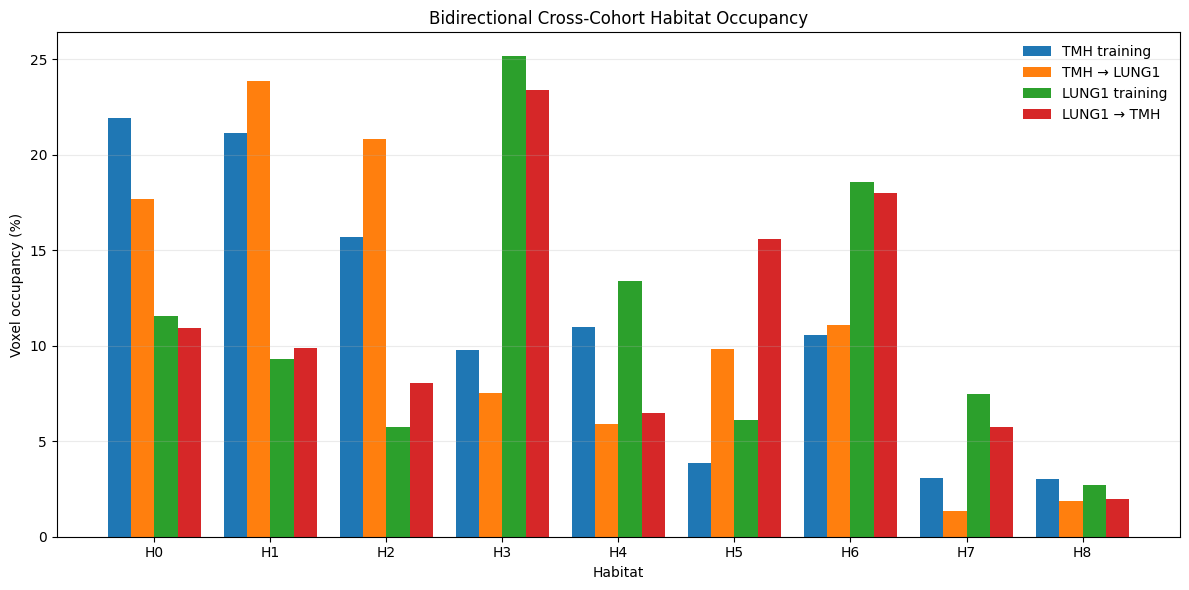

In [1085]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# OCCUPANCY DATA
# ------------------------------------------------------------

tmh_source_prop = np.array([
    21.93, 21.17, 15.68, 9.76, 10.96,
    3.85, 10.56, 3.05, 3.03
]) / 100

lung1_from_tmh_prop = np.array([
    17.69, 23.87, 20.84, 7.51, 5.92,
    9.83, 11.11, 1.37, 1.86
]) / 100

# LUNG1 source from current model
lung1_source_prop = lung_counts / lung_counts.sum()

# TMH after frozen LUNG1 model
tmh_from_lung_prop = np.array([
    10.92, 9.90, 8.03, 23.38, 6.47,
    15.59, 17.98, 5.75, 1.97
]) / 100

# ------------------------------------------------------------
# PLOT
# ------------------------------------------------------------

h = np.arange(9)
w = 0.20

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    h - 1.5*w,
    tmh_source_prop * 100,
    w,
    label="TMH training"
)

ax.bar(
    h - 0.5*w,
    lung1_from_tmh_prop * 100,
    w,
    label="TMH → LUNG1"
)

ax.bar(
    h + 0.5*w,
    lung1_source_prop * 100,
    w,
    label="LUNG1 training"
)

ax.bar(
    h + 1.5*w,
    tmh_from_lung_prop * 100,
    w,
    label="LUNG1 → TMH"
)

ax.set_xlabel("Habitat")
ax.set_ylabel("Voxel occupancy (%)")
ax.set_xticks(h)
ax.set_xticklabels([f"H{i}" for i in h])

ax.set_title("Bidirectional Cross-Cohort Habitat Occupancy")

ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

In [1086]:
print(lung_counts)
print(lung_counts.sum())

[4132395 3323553 2057015 9001508 4783562 2178613 6643036 2681214  970624]
35771520


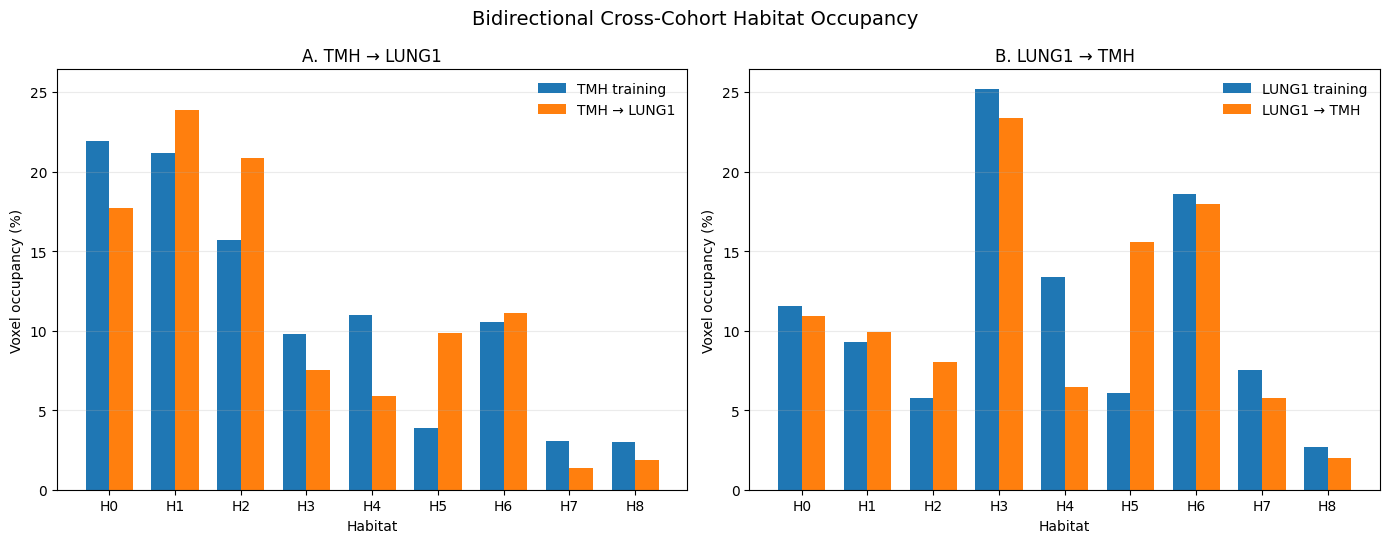

In [1107]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# DATA
# ============================================================

# -------------------------
# A: TMH → LUNG1
# -------------------------

tmh_source_prop = np.array([
    21.93, 21.17, 15.68, 9.76, 10.96,
    3.85, 10.56, 3.05, 3.03
])

lung1_from_tmh_prop = np.array([
    17.69, 23.87, 20.84, 7.51, 5.92,
    9.83, 11.11, 1.37, 1.86
])


# -------------------------
# B: LUNG1 → TMH
# -------------------------

# LUNG1 source occupancy
# Make sure lung_counts is from the LUNG1 source SOM
lung1_source_prop = (
    lung_counts / lung_counts.sum()
) * 100

# TMH after frozen LUNG1 model
tmh_from_lung_prop = np.array([
    10.92, 9.90, 8.03, 23.38, 6.47,
    15.59, 17.98, 5.75, 1.97
])

habitats = np.arange(9)
labels = [f"H{i}" for i in habitats]


# ============================================================
# PLOT
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5.5),
    sharey=True
)

width = 0.36


# ------------------------------------------------------------
# PANEL A: TMH → LUNG1
# ------------------------------------------------------------

axes[0].bar(
    habitats - width/2,
    tmh_source_prop,
    width,
    label="TMH training"
)

axes[0].bar(
    habitats + width/2,
    lung1_from_tmh_prop,
    width,
    label="TMH → LUNG1"
)

axes[0].set_title("A. TMH → LUNG1")
axes[0].set_xlabel("Habitat")
axes[0].set_ylabel("Voxel occupancy (%)")
axes[0].set_xticks(habitats)
axes[0].set_xticklabels(labels)
axes[0].legend(frameon=False)

axes[0].grid(
    axis="y",
    alpha=0.25
)


# ------------------------------------------------------------
# PANEL B: LUNG1 → TMH
# ------------------------------------------------------------

axes[1].bar(
    habitats - width/2,
    lung1_source_prop,
    width,
    label="LUNG1 training"
)

axes[1].bar(
    habitats + width/2,
    tmh_from_lung_prop,
    width,
    label="LUNG1 → TMH"
)

axes[1].set_title("B. LUNG1 → TMH")
axes[1].set_xlabel("Habitat")
axes[1].set_ylabel("Voxel occupancy (%)")  # Add y-axis label
axes[1].set_xticks(habitats)
axes[1].set_xticklabels(labels)
axes[1].tick_params(axis="y", labelleft=True)  # Show y-axis values
axes[1].legend(frameon=False)
axes[1].grid(
    axis="y",
    alpha=0.25
)


# ============================================================
# FINAL FORMATTING
# ============================================================

plt.suptitle(
    "Bidirectional Cross-Cohort Habitat Occupancy",
    fontsize=14
)

plt.tight_layout()

plt.show()

In [1088]:
import numpy as np
from tqdm.auto import tqdm

def get_bmu_distances(X, som, batch_size=200000):
    weights = som.get_weights().reshape(
        -1, som.get_weights().shape[-1]
    )

    all_distances = []

    for start in tqdm(
        range(0, len(X), batch_size),
        desc="Calculating BMU distances"
    ):
        end = min(start + batch_size, len(X))
        xb = X[start:end]

        d = (
            np.sum(xb**2, axis=1, keepdims=True)
            + np.sum(weights**2, axis=1)[None, :]
            - 2 * xb @ weights.T
        )

        min_dist = np.sqrt(
            np.maximum(np.min(d, axis=1), 0)
        )

        all_distances.append(min_dist)

    return np.concatenate(all_distances)


# LUNG1 source
bmu_dist_lung = get_bmu_distances(
    Z_lung_train,
    lung_som_3x3
)

# TMH transferred
bmu_dist_tmh = get_bmu_distances(
    Z_tmh_test_lung,
    lung_som_3x3
)


print("\n==============================")
print("LUNG1 → TMH BMU DISTANCE")
print("==============================")

print(f"LUNG1 mean   : {np.mean(bmu_dist_lung):.4f}")
print(f"LUNG1 median : {np.median(bmu_dist_lung):.4f}")

print(f"\nTMH mean     : {np.mean(bmu_dist_tmh):.4f}")
print(f"TMH median   : {np.median(bmu_dist_tmh):.4f}")

print(f"\nLUNG1 95th percentile : {np.percentile(bmu_dist_lung,95):.4f}")
print(f"TMH 95th percentile   : {np.percentile(bmu_dist_tmh,95):.4f}")

Calculating BMU distances:   0%|          | 0/179 [00:00<?, ?it/s]

Calculating BMU distances:   0%|          | 0/45 [00:00<?, ?it/s]


LUNG1 → TMH BMU DISTANCE
LUNG1 mean   : 3.5364
LUNG1 median : 2.3687

TMH mean     : 6.9484
TMH median   : 2.6149

LUNG1 95th percentile : 7.1468
TMH 95th percentile   : 25.4315


In [ ]:
#### universal habitat analysis

TMH SOM prototypes : (9, 8)
LUNG1 SOM prototypes: (9, 8)

Decoded TMH prototypes: (9, 10)
Decoded LUNG1 prototypes: (9, 10)

Spearman similarity matrix:
        LUNG1_H0  LUNG1_H1  LUNG1_H2  LUNG1_H3  LUNG1_H4  LUNG1_H5  LUNG1_H6  \
TMH_H0     0.552     0.988     0.964     0.976     0.988     0.527     0.988   
TMH_H1     0.418     0.939     0.927     0.952     0.976     0.394     0.976   
TMH_H2     0.418     0.939     0.927     0.952     0.976     0.394     0.976   
TMH_H3     0.539     1.000     0.988     0.952     0.964     0.552     0.964   
TMH_H4     0.455     0.952     0.964     0.939     0.915     0.527     0.915   
TMH_H5     0.430     0.964     0.939     0.939     0.964     0.406     0.964   
TMH_H6     0.079     0.576     0.552     0.539     0.576     0.018     0.576   
TMH_H7     0.418     0.964     0.976     0.903     0.927     0.442     0.927   
TMH_H8     0.091     0.624     0.612     0.552     0.588     0.079     0.588   

        LUNG1_H7  LUNG1_H8  
TMH_H0     0.927 

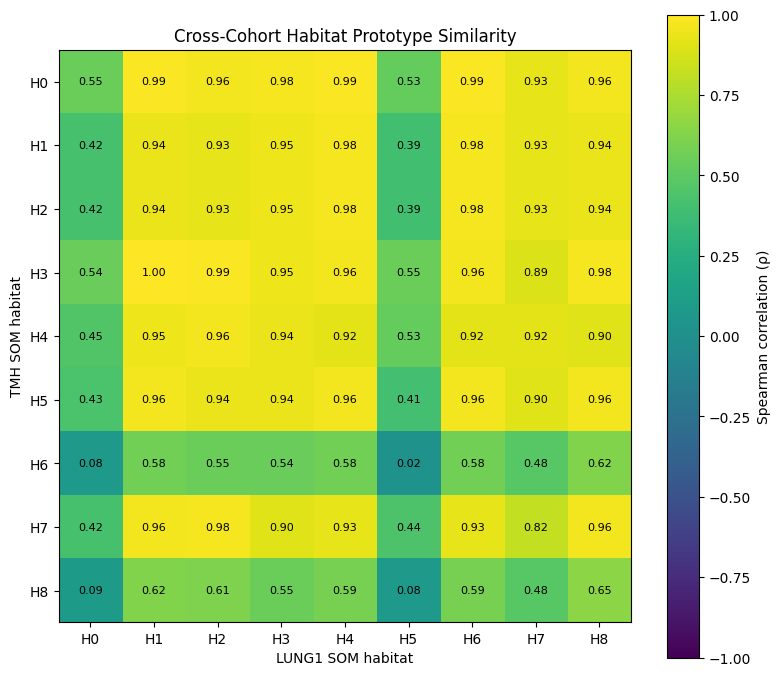


Saved:
TMH_LUNG1_habitat_correspondence.csv
TMH_LUNG1_prototype_similarity.npy


In [1089]:
# ============================================================
# CONSERVED / COHORT-SPECIFIC HABITAT ANALYSIS
# TMH SOM ↔ LUNG1 SOM
# ============================================================

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from scipy.stats import spearmanr
from scipy.optimize import linear_sum_assignment


# ------------------------------------------------------------
# 1. GET SOM PROTOTYPES IN 8-D LATENT SPACE
# ------------------------------------------------------------

tmh_som_proto = tmh_som_3x3.get_weights().reshape(9, 8)
lung_som_proto = lung_som_3x3.get_weights().reshape(9, 8)

print("TMH SOM prototypes :", tmh_som_proto.shape)
print("LUNG1 SOM prototypes:", lung_som_proto.shape)


# ------------------------------------------------------------
# 2. DECODE SOM PROTOTYPES BACK TO 10-D RADIOMIC SPACE
# ------------------------------------------------------------

ae_tmh.eval()
ae_lung.eval()

with torch.no_grad():

    tmh_z = torch.tensor(
        tmh_som_proto,
        dtype=torch.float32,
        device=device
    )

    lung_z = torch.tensor(
        lung_som_proto,
        dtype=torch.float32,
        device=device
    )

    tmh_proto_scaled = ae_tmh.dec(tmh_z).cpu().numpy()
    lung_proto_scaled = ae_lung.dec(lung_z).cpu().numpy()


# ------------------------------------------------------------
# 3. CONVERT BACK TO ORIGINAL RADIOMIC SCALE
# ------------------------------------------------------------

tmh_proto_raw = z_scaler_tmh.inverse_transform(
    tmh_proto_scaled
)

lung_proto_raw = z_scaler_lung.inverse_transform(
    lung_proto_scaled
)

print("\nDecoded TMH prototypes:", tmh_proto_raw.shape)
print("Decoded LUNG1 prototypes:", lung_proto_raw.shape)


# ------------------------------------------------------------
# 4. SPEARMAN SIMILARITY MATRIX
# ------------------------------------------------------------

similarity_matrix = np.zeros((9, 9))

for i in range(9):

    for j in range(9):

        rho, p = spearmanr(
            tmh_proto_raw[i],
            lung_proto_raw[j]
        )

        similarity_matrix[i, j] = rho


print("\nSpearman similarity matrix:")
print(
    pd.DataFrame(
        similarity_matrix,
        index=[f"TMH_H{i}" for i in range(9)],
        columns=[f"LUNG1_H{i}" for i in range(9)]
    ).round(3)
)


# ------------------------------------------------------------
# 5. HUNGARIAN ONE-TO-ONE MATCHING
# ------------------------------------------------------------

# Maximize correlation
row_ind, col_ind = linear_sum_assignment(
    -similarity_matrix
)

matched_rho = similarity_matrix[
    row_ind,
    col_ind
]

results = pd.DataFrame({
    "TMH_habitat": [f"H{i}" for i in row_ind],
    "LUNG1_habitat": [f"H{j}" for j in col_ind],
    "Spearman_rho": matched_rho
})

results = results.sort_values(
    "Spearman_rho",
    ascending=False
).reset_index(drop=True)


print("\n" + "="*60)
print("TMH ↔ LUNG1 HABITAT CORRESPONDENCE")
print("="*60)

print(results.to_string(index=False))

print("\nMean matched rho:",
      matched_rho.mean())

print("Median matched rho:",
      np.median(matched_rho))

print("Minimum matched rho:",
      matched_rho.min())

print("Maximum matched rho:",
      matched_rho.max())


# ------------------------------------------------------------
# 6. OPTIONAL: IDENTIFY STRONG CORRESPONDENCES
# ------------------------------------------------------------

# Do NOT automatically use this threshold in the paper
# until you inspect the actual values.

results["Candidate_conserved"] = (
    results["Spearman_rho"] >= 0.80
)

print("\nCandidate conserved habitats (rho >= 0.80):")
print(
    results[
        results["Candidate_conserved"]
    ].to_string(index=False)
)


# ------------------------------------------------------------
# 7. HEATMAP
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8, 7)
)

im = ax.imshow(
    similarity_matrix,
    vmin=-1,
    vmax=1,
    aspect="equal"
)

ax.set_xticks(range(9))
ax.set_yticks(range(9))

ax.set_xticklabels(
    [f"H{i}" for i in range(9)]
)

ax.set_yticklabels(
    [f"H{i}" for i in range(9)]
)

ax.set_xlabel("LUNG1 SOM habitat")
ax.set_ylabel("TMH SOM habitat")

ax.set_title(
    "Cross-Cohort Habitat Prototype Similarity"
)

cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Spearman correlation (ρ)")

# Write correlation values
for i in range(9):
    for j in range(9):
        ax.text(
            j,
            i,
            f"{similarity_matrix[i,j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. SAVE RESULTS
# ------------------------------------------------------------

results.to_csv(
    "TMH_LUNG1_habitat_correspondence.csv",
    index=False
)

np.save(
    "TMH_LUNG1_prototype_similarity.npy",
    similarity_matrix
)

print("\nSaved:")
print("TMH_LUNG1_habitat_correspondence.csv")
print("TMH_LUNG1_prototype_similarity.npy")

In [1090]:
#### %debug

# ============================================================
# CHECK UNIQUENESS OF CROSS-COHORT HABITAT MATCHES
# ============================================================

for i in range(9):

    row = similarity_matrix[i]

    order = np.argsort(row)[::-1]

    best = order[0]
    second = order[1]

    print(
        f"TMH H{i} -> LUNG1 H{best}: "
        f"rho={row[best]:.3f}, "
        f"2nd=H{second} rho={row[second]:.3f}, "
        f"margin={row[best]-row[second]:.3f}"
    )

TMH H0 -> LUNG1 H6: rho=0.988, 2nd=H4 rho=0.988, margin=0.000
TMH H1 -> LUNG1 H6: rho=0.976, 2nd=H4 rho=0.976, margin=0.000
TMH H2 -> LUNG1 H6: rho=0.976, 2nd=H4 rho=0.976, margin=0.000
TMH H3 -> LUNG1 H1: rho=1.000, 2nd=H2 rho=0.988, margin=0.012
TMH H4 -> LUNG1 H2: rho=0.964, 2nd=H1 rho=0.952, margin=0.012
TMH H5 -> LUNG1 H8: rho=0.964, 2nd=H6 rho=0.964, margin=0.000
TMH H6 -> LUNG1 H8: rho=0.624, 2nd=H6 rho=0.576, margin=0.048
TMH H7 -> LUNG1 H2: rho=0.976, 2nd=H8 rho=0.964, margin=0.012
TMH H8 -> LUNG1 H8: rho=0.648, 2nd=H1 rho=0.624, margin=0.024


In [1091]:
# ============================================================
# RECIPROCAL BEST MATCH
# ============================================================

row_best = np.argmax(similarity_matrix, axis=1)
col_best = np.argmax(similarity_matrix, axis=0)

for i in range(9):

    j = row_best[i]

    reciprocal = (col_best[j] == i)

    print(
        f"TMH H{i} -> LUNG1 H{j}: "
        f"rho={similarity_matrix[i,j]:.3f}, "
        f"reciprocal={reciprocal}"
    )

TMH H0 -> LUNG1 H1: rho=0.988, reciprocal=False
TMH H1 -> LUNG1 H4: rho=0.976, reciprocal=False
TMH H2 -> LUNG1 H4: rho=0.976, reciprocal=False
TMH H3 -> LUNG1 H1: rho=1.000, reciprocal=True
TMH H4 -> LUNG1 H2: rho=0.964, reciprocal=False
TMH H5 -> LUNG1 H1: rho=0.964, reciprocal=False
TMH H6 -> LUNG1 H8: rho=0.624, reciprocal=False
TMH H7 -> LUNG1 H2: rho=0.976, reciprocal=False
TMH H8 -> LUNG1 H8: rho=0.648, reciprocal=False


### Patient inference pipeline

In [400]:
import os
import glob
import numpy as np
import SimpleITK as sitk

# ---------------------------------------------------------
# Final list of features used for the AE
# ---------------------------------------------------------

FEATURES = [ 'DependenceEntropy',
'DependenceNonUniformity',
'DependenceVariance',
'HighGrayLevelEmphasis',
'LargeDependenceHighGrayLevelEmphasis',
'LargeDependenceLowGrayLevelEmphasis',
'LowGrayLevelEmphasis',
'SmallDependenceEmphasis',
'SmallDependenceHighGrayLevelEmphasis',
'SmallDependenceLowGrayLevelEmphasis']

import os
import glob
import SimpleITK as sitk
import numpy as np


def load_feature_maps(patient_dir, selected_features):

    maps = []
    feature_names = []
    reference_img = None

    all_files = glob.glob(
        os.path.join(patient_dir, "*.nrrd")
    )

    for feature in selected_features:

        matches = [
            f for f in all_files
            if f.endswith(f"_gldm_{feature}.nrrd")
        ]

        if len(matches) == 0:
            raise FileNotFoundError(
                f"Missing feature: {feature}"
            )

        f = matches[0]

        img = sitk.ReadImage(f)
        arr = sitk.GetArrayFromImage(img).astype(np.float32)

        if reference_img is None:
            reference_img = img

        maps.append(arr)
        feature_names.append(feature)

    maps = np.stack(maps, axis=0)

    print("===================================")
    print(f"Loaded {len(feature_names)} selected features")
    print("Features:", feature_names)
    print(f"Shape: {maps.shape}")
    print("===================================")

    return maps, reference_img, feature_names

In [477]:
patient_folder='/workspace/gb_vox_rad/20_mm_final/TMH/gldm/train/105131012/'

In [402]:
# 1. load 1 pateint

In [478]:
maps, ref_img, feature_names = load_feature_maps(patient_folder , FEATURES)

Loaded 10 selected features
Features: ['DependenceEntropy', 'DependenceNonUniformity', 'DependenceVariance', 'HighGrayLevelEmphasis', 'LargeDependenceHighGrayLevelEmphasis', 'LargeDependenceLowGrayLevelEmphasis', 'LowGrayLevelEmphasis', 'SmallDependenceEmphasis', 'SmallDependenceHighGrayLevelEmphasis', 'SmallDependenceLowGrayLevelEmphasis']
Shape: (10, 69, 61, 57)


In [479]:
maps.shape

(10, 69, 61, 57)

In [480]:
voxels.shape[1]

10

In [406]:
# 2. convert to voxel matrix

In [481]:
voxels, volume_shape, _ = maps_to_voxels(maps)
print(voxels.shape)

Voxel matrix created
Feature maps : 10
Volume shape : (69, 61, 57)
Total voxels : 239,913
Matrix shape : (239913, 10)
(239913, 10)


In [482]:
print(voxels.shape)
print(np.min(voxels), np.max(voxels))
print("Zero voxels:", np.sum(voxels == 0))

(239913, 10)
0.0 378233.4
Zero voxels: 225438


In [483]:
voxels.shape

(239913, 10)

In [484]:
z_scaler

StandardScaler()

In [485]:
# 3. scaling 

import joblib
# scaler = joblib.load("robust_scaler_10_features.pkl")

# voxels = scaler.transform(voxels)
z_scaler = joblib.load(
    "tmh_standard_scaler_10features.pkl"
)

print(z_scaler.n_features_in_)

print(feature_names)
print(len(feature_names))

print(z_scaler.n_features_in_)  # should be 10
print(voxels.shape)           # (N, 10)

# scaling the single test patient
# Step 1: map feature names → indices
indices = [feature_names.index(f) for f in FEATURES]

# Step 2: select only training features
voxels = voxels[:, indices]

# Step 3: scale
patient_scaled = z_scaler.transform(
    voxels
).astype(np.float32)

10
['DependenceEntropy', 'DependenceNonUniformity', 'DependenceVariance', 'HighGrayLevelEmphasis', 'LargeDependenceHighGrayLevelEmphasis', 'LargeDependenceLowGrayLevelEmphasis', 'LowGrayLevelEmphasis', 'SmallDependenceEmphasis', 'SmallDependenceHighGrayLevelEmphasis', 'SmallDependenceLowGrayLevelEmphasis']
10
10
(239913, 10)


In [486]:
z_scaler


StandardScaler()

In [487]:
model.load_state_dict(torch.load("tmh_ae_final.pth"))
model.eval()

AE(
  (enc): Sequential(
    (0): Linear(in_features=10, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=16, bias=True)
    (5): ReLU()
    (6): Linear(in_features=16, out_features=8, bias=True)
  )
  (dec): Sequential(
    (0): Linear(in_features=8, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=10, bias=True)
  )
)

In [488]:
# 4. get latent
latent = get_latent(model, voxels)

print(latent.shape)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:01<00:00,  1.59it/s]

(239913, 8)


In [497]:
voxels.shape


(239913, 10)

In [489]:
print(np.isnan(latent).sum())

0


In [257]:
# 5. SOM INFERENCE (HABITAT ASSIGNMENT)

In [490]:
def som_predict(som, latent):
    """
    Assign each voxel to a SOM node (habitat)
    
    Args:
        som: trained MiniSom (e.g., 4x4)
        latent: (N, latent_dim)
    
    Returns:
        labels: (N,)
    """
    
    labels = []

    for z in latent:
        winner = som.winner(z)   # (i, j)
        
        # convert 2D grid → single label
        label = winner[0] * som._weights.shape[1] + winner[1]
        
        labels.append(label)

    return np.array(labels)

In [491]:
som_2x2

In [492]:
print(volume_shape)

(69, 61, 57)


In [525]:
print(np.unique(labels_valid))

[0 1 2 3 4 5 6 7 8]


In [ ]:
# proper processing of the voxels

In [503]:
# 1. valid radiomics voxels only
valid_mask = ~np.all(voxels == 0, axis=1)

valid_voxels = voxels[valid_mask]

print("Total voxels :", len(voxels))
print("Valid voxels :", valid_voxels.shape[0])
print("Background  :", (~valid_mask).sum())

# 2. scale with the TMH training scaler
patient_scaled = z_scaler.transform(
    valid_voxels
).astype(np.float32)

# 3. AE inference on SCALED data
latent = get_latent(
    model,
    patient_scaled
)

# 4. TMH-trained 3x3 SOM
labels_valid = som_predict(
    som_3x3,
    latent
)

print("Latent:", latent.shape)
print("Habitats:", np.unique(labels_valid))

Total voxels : 239913
Valid voxels : 217371
Background  : 22542


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:01<00:00,  1.50it/s]


Latent: (217371, 8)
Habitats: [0 1 2 3 4 5 6 7 8]


In [504]:
z_scaler

StandardScaler()

In [261]:
# 6 RECONSTRUCT 3D HABITAT MAP

In [518]:
habitat_map = np.full(
    volume_shape,
    -1,
    dtype=np.int16
)

habitat_map[
    valid_mask.reshape(volume_shape)
] = labels_valid

print(np.unique(habitat_map))

[-1  0  1  2  3  4  5  6  7  8]


In [506]:
# # 6.1 RESHAPE
# habitat_map = labels.reshape(volume_shape)

print(habitat_map.shape)

(69, 61, 57)


In [523]:
print(np.unique(habitat_map))

[-1  0  1  2  3  4  5  6  7  8]


In [508]:
# CHECK LATENT DIVERSITY
print(latent.min(), latent.max())
print(np.std(latent, axis=0))

-129.47993 86.06275
[0.93085784 0.9271387  1.2386245  2.72566    1.1569853  1.9659529
 2.6839695  1.3518966 ]


In [509]:
# CHECK SOM WEIGHTS
weights = som_3x3.get_weights()

print(weights.shape)
print(np.std(weights))

(3, 3, 8)
5.55649778028232


In [510]:
# CHECK bmu MANUALL

for i in range(10):
    print(som_3x3.winner(latent[i]))

(0, 0)
(0, 0)
(0, 0)
(0, 0)
(0, 0)
(0, 0)
(0, 0)
(0, 0)
(0, 0)
(0, 0)


In [512]:
# CHECK LABEL DISTRIBUTION

unique, counts = np.unique(labels_valid, return_counts=True)

for u, c in zip(unique, counts):
    print(u, c)

0 69612
1 54698
2 47753
3 19741
4 10008
5 15247
6 1
7 22
8 289


In [455]:
# sample = latent[np.random.choice(len(latent), 1000, replace=False)]

# labels_sample = som_predict(som_4x4, sample)

# print(np.unique(labels_sample))

In [253]:
# # SINCE WE are getting only 15 one value , we must get range of values 

# #Retrain SOM using current latent
# from minisom import MiniSom

# som_4x4 = MiniSom(4, 4, latent.shape[1], sigma=1.0, learning_rate=0.5)

# som_4x4.random_weights_init(latent)
# som_4x4.train_random(latent, 10000)

In [123]:
# som_3x3_manual = MiniSom(4, 4, latent.shape[1], sigma=1.0, learning_rate=0.5)
# labels = som_predict(som_3x3_manual, latent)
# np.unique(labels)
# #array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15])

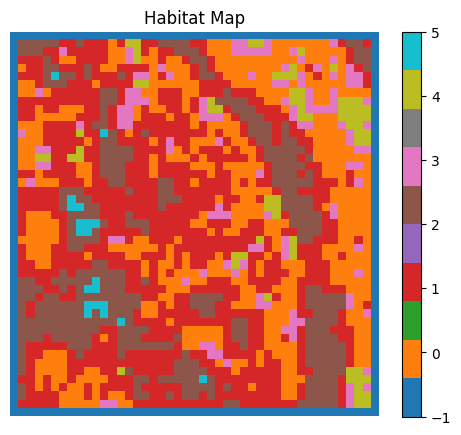

In [859]:
import matplotlib.pyplot as plt

slice_idx = 43

plt.figure(figsize=(6,5))
plt.imshow(habitat_map[slice_idx], cmap="tab10")
plt.colorbar()
plt.title("Habitat Map")
plt.axis("off")
plt.show()
# plt.imshow(
#     habitat_map[z],
#     cmap="tab10",
#     vmin=0,
#     vmax=3
# )

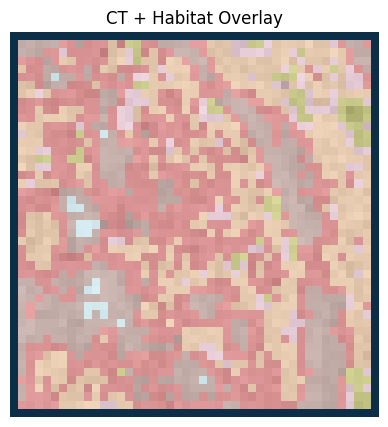

In [855]:
import SimpleITK as sitk

ct = sitk.GetArrayFromImage(ref_img)

slice_idx = 43

plt.figure(figsize=(6,5))

plt.imshow(ct[slice_idx], cmap="gray")

plt.imshow(
    habitat_map[slice_idx],
    cmap="tab20",
    alpha=0.4
)

plt.title("CT + Habitat Overlay")
plt.axis("off")
plt.show()

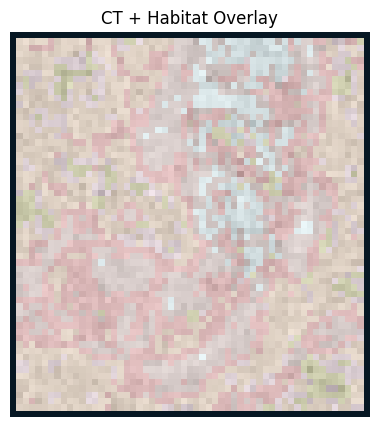

In [ ]:
# old

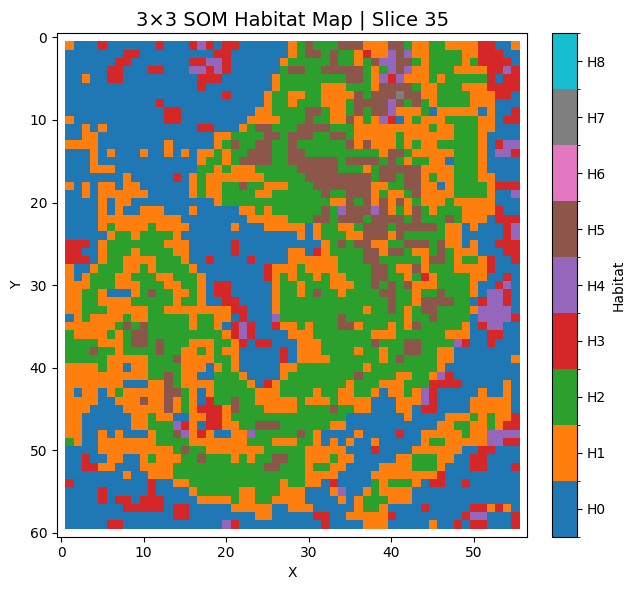

In [549]:
# correct habitat map

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

n_habitats = 9

# Background = -1
hab_display = np.ma.masked_where(
    habitat_map < 0,
    habitat_map
)

# Exactly 9 categorical colors
cmap = plt.cm.tab10

norm = mcolors.BoundaryNorm(
    np.arange(-0.5, n_habitats + 0.5, 1),
    cmap.N
)

slice_idx = 35

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    hab_display[slice_idx],
    cmap=cmap,
    norm=norm,
    interpolation="nearest"
)

ax.set_title(
    f"3×3 SOM Habitat Map | Slice {slice_idx}",
    fontsize=14
)

ax.set_xlabel("X")
ax.set_ylabel("Y")

cbar = fig.colorbar(
    im,
    ax=ax,
    ticks=np.arange(n_habitats),
    fraction=0.046,
    pad=0.04
)

cbar.set_label("Habitat")
cbar.ax.set_yticklabels(
    [f"H{i}" for i in range(n_habitats)]
)

plt.tight_layout()
plt.show()

In [ ]:
# ct images are in 
/home/user/Desktop/gb_voxel_radiomics_input_files/gb_phd_dicoms/732711211/


In [ ]:
CT                : /workspace/gb_vox_rad/gb_dicoms_nii/tmh/gb_niis/732711211/CT.nii.gz
   Original Mask     : /workspace/gb_vox_rad/gb_dicoms_nii/tmh/gb_niis/732711211/mask_original.nii.gz
   20 mm Mask        : /workspace/gb_vox_rad/gb_dicoms_nii/tmh/gb_niis/732711211/mask_20mm.nii.gz

In [349]:
745213077

<SimpleITK.SimpleITK.Image; proxy of <Swig Object of type 'itk::simple::Image *' at 0x7f1656829f80> >

#### save habitat

In [537]:
import SimpleITK as sitk
import numpy as np

habitat_img = sitk.GetImageFromArray(
    habitat_map.astype(np.uint8)
)

habitat_img.CopyInformation(ref_img)

sitk.WriteImage(
    habitat_img,
    "habitat_map_3x3_105131012.nii.gz"
)

print("Saved: habitat_map.nii.gz")

Saved: habitat_map.nii.gz


In [538]:
check = sitk.ReadImage("habitat_map_3x3_105131012.nii.gz")

print("Size:", check.GetSize())
print("Spacing:", check.GetSpacing())
print("Origin:", check.GetOrigin())
print("Direction:", check.GetDirection())

Size: (57, 61, 69)
Spacing: (2.0, 2.0, 2.0)
Origin: (2.4140625, 84.4140625, -704.5)
Direction: (1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0)


In [ ]:
851197932

In [539]:
# Resample habitat map to CT space
import SimpleITK as sitk
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Load CT and original tumor mask
# -----------------------------

ct_img = sitk.ReadImage(
    "/workspace/gb_vox_rad/gb_dicoms_nii/tmh/gb_niis/105131012/CT.nii.gz"
)

mask_img = sitk.ReadImage(
    "/workspace/gb_vox_rad/gb_dicoms_nii/tmh/gb_niis/105131012/mask_original.nii.gz"
)

habitat_img = sitk.ReadImage(
    "habitat_map_3x3_105131012.nii.gz"
)

# -----------------------------
# Resample habitat to CT space
# IMPORTANT: nearest neighbour
# because habitat IDs are labels
# -----------------------------

resampler = sitk.ResampleImageFilter()

resampler.SetReferenceImage(ct_img)
resampler.SetInterpolator(
    sitk.sitkNearestNeighbor
)
resampler.SetDefaultPixelValue(0)

habitat_ct_img = resampler.Execute(
    habitat_img
)

# Convert to numpy
ct = sitk.GetArrayFromImage(ct_img)
mask = sitk.GetArrayFromImage(mask_img)
habitat_ct = sitk.GetArrayFromImage(habitat_ct_img)

print("CT:", ct.shape)
print("Mask:", mask.shape)
print("Habitat:", habitat_ct.shape)

CT: (383, 512, 512)
Mask: (383, 512, 512)
Habitat: (383, 512, 512)


In [ ]:
# Select the tumor-centered CT slice

In [540]:
tumor_coords = np.where(mask > 0)

z = int(np.mean(tumor_coords[0]))

print("Tumor-centered slice:", z)

Tumor-centered slice: 233


In [ ]:
############ final ct + hab+ tumor overlay

In [555]:
import SimpleITK as sitk

# CT
ct_img = sitk.ReadImage(
    "/workspace/gb_vox_rad/gb_dicoms_nii/tmh/gb_niis/105131012/CT.nii.gz"
)

# Original tumor
mask_img = sitk.ReadImage(
    "/workspace/gb_vox_rad/gb_dicoms_nii/tmh/gb_niis/105131012/mask_original.nii.gz"
)

# Habitat map in radiomics/reference space
habitat_img = sitk.GetImageFromArray(
    habitat_map.astype(np.int16)
)

habitat_img.CopyInformation(ref_img)

# Valid radiomics mask
valid_img = sitk.GetImageFromArray(
    valid_mask.astype(np.uint8)
)

valid_img.CopyInformation(ref_img)

# Resample habitat to CT
habitat_ct_img = sitk.Resample(
    habitat_img,
    ct_img,
    sitk.Transform(),
    sitk.sitkNearestNeighbor,
    -1,
    sitk.sitkInt16
)

# Resample valid mask to CT
valid_ct_img = sitk.Resample(
    valid_img,
    ct_img,
    sitk.Transform(),
    sitk.sitkNearestNeighbor,
    0,
    sitk.sitkUInt8
)

ct = sitk.GetArrayFromImage(ct_img)
tumor = sitk.GetArrayFromImage(mask_img)
habitat_ct = sitk.GetArrayFromImage(habitat_ct_img)
valid_ct = sitk.GetArrayFromImage(valid_ct_img).astype(bool)

RuntimeError: Exception thrown in SimpleITK new_Image: /work/src/Code/Common/src/sitkImageExplicit.cxx:106:
sitk::ERROR: Unsupported number of dimensions specified by size: [ 239913 ]!
The maximum supported Image dimension is 5.

In [ ]:
"/workspace/gb_vox_rad/20_mm_final/TMH/gldm/test/745213077/

Loaded 10 selected features
Features: ['DependenceEntropy', 'DependenceNonUniformity', 'DependenceVariance', 'HighGrayLevelEmphasis', 'LargeDependenceHighGrayLevelEmphasis', 'LargeDependenceLowGrayLevelEmphasis', 'LowGrayLevelEmphasis', 'SmallDependenceEmphasis', 'SmallDependenceHighGrayLevelEmphasis', 'SmallDependenceLowGrayLevelEmphasis']
Shape: (10, 52, 47, 45)

Loaded maps: (10, 52, 47, 45)
Features: ['DependenceEntropy', 'DependenceNonUniformity', 'DependenceVariance', 'HighGrayLevelEmphasis', 'LargeDependenceHighGrayLevelEmphasis', 'LargeDependenceLowGrayLevelEmphasis', 'LowGrayLevelEmphasis', 'SmallDependenceEmphasis', 'SmallDependenceHighGrayLevelEmphasis', 'SmallDependenceLowGrayLevelEmphasis']
Voxel matrix created
Feature maps : 10
Volume shape : (52, 47, 45)
Total voxels : 109,980
Matrix shape : (109980, 10)

Voxel matrix: (109980, 10)
Volume shape: (52, 47, 45)

Valid voxels     : 96750
Background voxels: 13230
Valid voxel matrix: (96750, 10)

Scaler expects: 10
Scaled matr

  0%|          | 0/1 [00:00<?, ?it/s]


Latent shape: (96750, 8)
Labels shape: (96750,)
Habitats: [0 1 2 3 4 5 7 8]

Habitat map: (52, 47, 45)
Habitat IDs: [-1  0  1  2  3  4  5  7  8]

Saved: habitat_745213077_3x3.nii.gz
Saved: valid_radiomics_745213077.nii.gz

CT shape   : (84, 512, 512)
Tumor shape: (84, 512, 512)
Habitat CT shape: (84, 512, 512)
Tumor-centered CT slice: 57


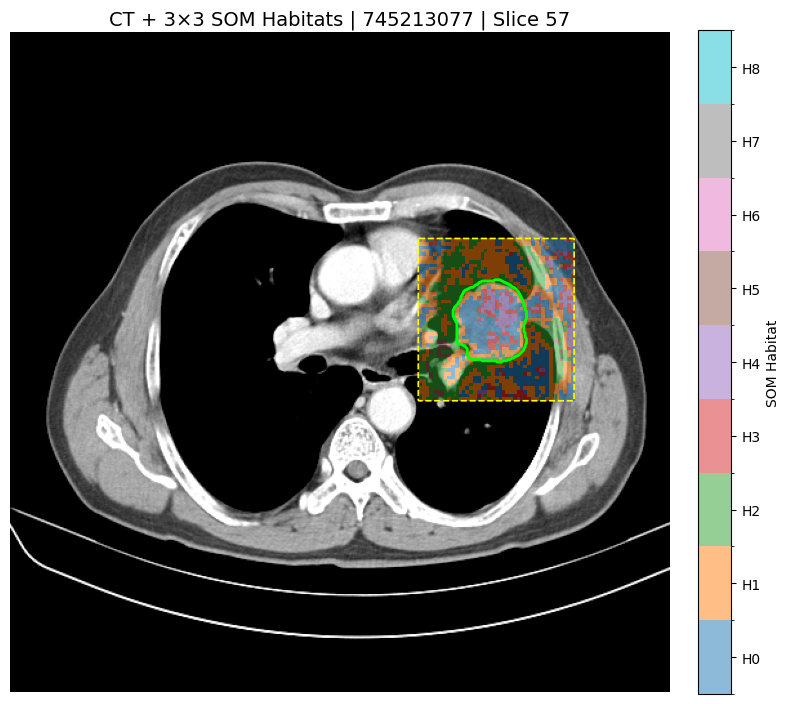

In [910]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import SimpleITK as sitk
import joblib


# ============================================================
# 1. SETTINGS
# ============================================================

patient_id = "745213077"

patient_folder = (
    f"/workspace/gb_vox_rad/20_mm_final/TMH/gldm/test/{patient_id}/"
)

ct_path = (
    f"/workspace/gb_vox_rad/gb_dicoms_nii/tmh/"
    f"gb_niis/{patient_id}/CT.nii.gz"
)

mask_path = (
    f"/workspace/gb_vox_rad/gb_dicoms_nii/tmh/"
    f"gb_niis/{patient_id}/mask_original.nii.gz"
)

scaler_path = "tmh_standard_scaler_10features.pkl"

# Current model = 3x3 SOM
n_habitats = 9


# ============================================================
# 2. FINAL 10 FEATURES
# ============================================================

FEATURES = [
    "DependenceEntropy",
    "DependenceNonUniformity",
    "DependenceVariance",
    "HighGrayLevelEmphasis",
    "LargeDependenceHighGrayLevelEmphasis",
    "LargeDependenceLowGrayLevelEmphasis",
    "LowGrayLevelEmphasis",
    "SmallDependenceEmphasis",
    "SmallDependenceHighGrayLevelEmphasis",
    "SmallDependenceLowGrayLevelEmphasis"
]


# ============================================================
# 3. LOAD GLDM FEATURE MAPS
# ============================================================

maps, ref_img, feature_names = load_feature_maps(
    patient_folder,
    FEATURES
)

print("\nLoaded maps:", maps.shape)
print("Features:", feature_names)


# ============================================================
# 4. CONVERT MAPS -> VOXEL MATRIX
# ============================================================

voxels, volume_shape, n_voxels = maps_to_voxels(
    maps
)

print("\nVoxel matrix:", voxels.shape)
print("Volume shape:", volume_shape)


# ============================================================
# 5. CREATE VALID RADIOMICS MASK
#    Background = all 10 features are zero
# ============================================================

valid_mask = ~np.all(
    voxels == 0,
    axis=1
)

print("\nValid voxels     :", valid_mask.sum())
print("Background voxels:", (~valid_mask).sum())


# ============================================================
# 6. KEEP ONLY VALID VOXELS
# ============================================================

valid_voxels = voxels[
    valid_mask
]

print(
    "Valid voxel matrix:",
    valid_voxels.shape
)


# ============================================================
# 7. LOAD TMH Z-SCORE SCALER
# ============================================================

z_scaler_tmh = joblib.load(
    scaler_path
)

print(
    "\nScaler expects:",
    z_scaler_tmh.n_features_in_
)


# ============================================================
# 8. Z-SCORE SCALING
# ============================================================

patient_scaled = z_scaler_tmh.transform(
    valid_voxels
).astype(np.float32)

print(
    "Scaled matrix:",
    patient_scaled.shape
)

print(
    "NaN:",
    np.isnan(patient_scaled).sum()
)

print(
    "Inf:",
    np.isinf(patient_scaled).sum()
)


# ============================================================
# 9. AE LATENT EXTRACTION
# ============================================================

latent = get_latent(
    model,
    patient_scaled,
    batch_size=131072
)

print(
    "\nLatent shape:",
    latent.shape
)


# ============================================================
# 10. SOM HABITAT ASSIGNMENT
# ============================================================

labels_valid = som_predict(
    som_3x3,
    latent
)

print(
    "Labels shape:",
    labels_valid.shape
)

print(
    "Habitats:",
    np.unique(labels_valid)
)


# ============================================================
# 11. RECONSTRUCT 3D HABITAT MAP
#     -1 = background
# ============================================================

habitat_map = np.full(
    volume_shape,
    -1,
    dtype=np.int16
)

valid_mask_3d = valid_mask.reshape(
    volume_shape
)

habitat_map[
    valid_mask_3d
] = labels_valid

print(
    "\nHabitat map:",
    habitat_map.shape
)

print(
    "Habitat IDs:",
    np.unique(habitat_map)
)


# ============================================================
# 12. SAVE HABITAT MAP IN REFERENCE SPACE
# ============================================================

habitat_img = sitk.GetImageFromArray(
    habitat_map
)

habitat_img.CopyInformation(
    ref_img
)

habitat_output = (
    f"habitat_{patient_id}_3x3.nii.gz"
)

sitk.WriteImage(
    habitat_img,
    habitat_output
)

print(
    "\nSaved:",
    habitat_output
)


# ============================================================
# 13. SAVE VALID MASK IN REFERENCE SPACE
# ============================================================

valid_img = sitk.GetImageFromArray(
    valid_mask_3d.astype(np.uint8)
)

valid_img.CopyInformation(
    ref_img
)

valid_output = (
    f"valid_radiomics_{patient_id}.nii.gz"
)

sitk.WriteImage(
    valid_img,
    valid_output
)

print(
    "Saved:",
    valid_output
)


# ============================================================
# 14. LOAD CT + ORIGINAL TUMOR MASK
# ============================================================

ct_img = sitk.ReadImage(
    ct_path
)

mask_img = sitk.ReadImage(
    mask_path
)

ct = sitk.GetArrayFromImage(
    ct_img
)

tumor = sitk.GetArrayFromImage(
    mask_img
)

print("\nCT shape   :", ct.shape)
print("Tumor shape:", tumor.shape)


# ============================================================
# 15. RESAMPLE HABITAT MAP TO CT SPACE
#     IMPORTANT: nearest-neighbour for labels
# ============================================================

habitat_ct_img = sitk.Resample(
    habitat_img,
    ct_img,
    sitk.Transform(),
    sitk.sitkNearestNeighbor,
    -1,
    sitk.sitkInt16
)

valid_ct_img = sitk.Resample(
    valid_img,
    ct_img,
    sitk.Transform(),
    sitk.sitkNearestNeighbor,
    0,
    sitk.sitkUInt8
)

habitat_ct = sitk.GetArrayFromImage(
    habitat_ct_img
)

valid_ct = sitk.GetArrayFromImage(
    valid_ct_img
).astype(bool)

print(
    "Habitat CT shape:",
    habitat_ct.shape
)


# ============================================================
# 16. CHOOSE TUMOR-CENTERED CT SLICE
# ============================================================

tumor_z = np.where(
    tumor > 0
)[0]

if len(tumor_z) == 0:
    raise ValueError(
        "Tumor mask contains no foreground voxels."
    )

z = int(
    np.median(tumor_z)
)

print(
    "Tumor-centered CT slice:",
    z
)


# ============================================================
# 17. PREPARE CT
# ============================================================

ct_slice = ct[z]

ct_display = np.clip(
    ct_slice,
    -200,
    200
)

ct_display = (
    ct_display - ct_display.min()
) / (
    ct_display.max()
    - ct_display.min()
    + 1e-8
)


# ============================================================
# 18. PREPARE HABITAT OVERLAY
#     Background and invalid voxels are transparent
# ============================================================

hab_slice = habitat_ct[z]

hab_slice = np.ma.masked_where(
    (~valid_ct[z]) |
    (hab_slice < 0),
    hab_slice
)


# ============================================================
# 19. DISCRETE 9-HABITAT COLORMAP
# ============================================================

cmap = plt.cm.tab10

norm = mcolors.BoundaryNorm(
    np.arange(
        -0.5,
        n_habitats + 0.5,
        1
    ),
    cmap.N
)


# ============================================================
# 20. FINAL CT + TUMOR + HABITAT FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 8)
)

# CT
ax.imshow(
    ct_display,
    cmap="gray"
)

# Habitats
im = ax.imshow(
    hab_slice,
    cmap=cmap,
    norm=norm,
    alpha=0.50,
    interpolation="nearest"
)

# Original tumor boundary
ax.contour(
    tumor[z] > 0,
    colors="lime",
    linewidths=2.0
)

# Radiomics-region boundary
ax.contour(
    valid_ct[z],
    colors="yellow",
    linewidths=1.2,
    linestyles="--"
)

ax.set_title(
    f"CT + 3×3 SOM Habitats | {patient_id} | Slice {z}",
    fontsize=14
)

ax.axis("off")


# ============================================================
# 21. CLEAN CATEGORICAL COLORBAR
# ============================================================

cbar = fig.colorbar(
    im,
    ax=ax,
    ticks=np.arange(
        n_habitats
    ),
    fraction=0.046,
    pad=0.04
)

cbar.set_label(
    "SOM Habitat"
)

cbar.ax.set_yticklabels(
    [
        f"H{i}"
        for i in range(n_habitats)
    ]
)

plt.tight_layout()
plt.show()

In [561]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import ipywidgets as widgets
from IPython.display import display

# ============================================================
# SETTINGS
# ============================================================

n_habitats = 9

cmap = plt.cm.tab10

norm = mcolors.BoundaryNorm(
    np.arange(-0.5, n_habitats + 0.5, 1),
    cmap.N
)

# ============================================================
# CT WINDOW
# ============================================================

def window_ct(slice_img, low=-200, high=200):

    x = np.clip(
        slice_img,
        low,
        high
    )

    x = (
        x - x.min()
    ) / (
        x.max() - x.min() + 1e-8
    )

    return x


# ============================================================
# DISPLAY FUNCTION
# ============================================================

def show_slice(z):

    z = int(z)

    ct_slice = ct[z]
    tumor_slice = tumor[z]
    habitat_slice = habitat_ct[z]
    valid_slice = valid_ct[z]

    # --------------------------------------------------------
    # CT
    # --------------------------------------------------------

    ct_display = window_ct(
        ct_slice
    )

    # --------------------------------------------------------
    # Habitat mask
    #
    # -1 = background / invalid
    # 0-8 = actual habitats
    # --------------------------------------------------------

    hab_masked = np.ma.masked_where(
        (~valid_slice) |
        (habitat_slice < 0),
        habitat_slice
    )

    # --------------------------------------------------------
    # Figure
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(8, 8)
    )

    # --------------------------------------------------------
    # CT background
    # --------------------------------------------------------

    ax.imshow(
        ct_display,
        cmap="gray"
    )

    # --------------------------------------------------------
    # Habitat overlay
    # --------------------------------------------------------

    im = ax.imshow(
        hab_masked,
        cmap=cmap,
        norm=norm,
        alpha=0.50,
        interpolation="nearest"
    )

    # --------------------------------------------------------
    # Original tumor boundary
    # --------------------------------------------------------

    ax.contour(
        tumor_slice > 0,
        colors="lime",
        linewidths=2.0
    )

    # --------------------------------------------------------
    # Valid radiomics region boundary
    # --------------------------------------------------------

    ax.contour(
        valid_slice,
        colors="yellow",
        linewidths=1.2,
        linestyles="--"
    )

    # --------------------------------------------------------
    # Title
    # --------------------------------------------------------

    ax.set_title(
        f"CT + 3×3 SOM Habitats | Slice {z}",
        fontsize=14
    )

    ax.axis("off")

    # --------------------------------------------------------
    # Colorbar
    # --------------------------------------------------------

    cbar = fig.colorbar(
        im,
        ax=ax,
        ticks=np.arange(n_habitats),
        fraction=0.046,
        pad=0.04
    )

    cbar.set_label(
        "SOM Habitat"
    )

    cbar.ax.set_yticklabels(
        [f"H{i}" for i in range(n_habitats)]
    )

    plt.tight_layout()
    plt.show()


# ============================================================
# INTERACTIVE SLICE SLIDER
# ============================================================

z0 = int(
    np.median(
        np.where(tumor > 0)[0]
    )
)

slice_slider = widgets.IntSlider(
    value=z0,
    min=0,
    max=ct.shape[0] - 1,
    step=1,
    description="Slice:",
    continuous_update=True,
    readout=True,
    layout=widgets.Layout(
        width="600px"
    )
)

widgets.interact(
    show_slice,
    z=slice_slider
);

interactive(children=(IntSlider(value=57, description='Slice:', layout=Layout(width='600px'), max=83), Output(…

In [562]:
# viwer with zooming options
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import ipywidgets as widgets
from IPython.display import display

# ============================================================
# SETTINGS
# ============================================================

n_habitats = 9

cmap = plt.cm.tab10

norm = mcolors.BoundaryNorm(
    np.arange(-0.5, n_habitats + 0.5, 1),
    cmap.N
)

ZOOM_PADDING = 30   # pixels around tumor


# ============================================================
# CT WINDOW
# ============================================================

def window_ct(slice_img, low=-200, high=200):

    x = np.clip(slice_img, low, high)

    x = (
        x - x.min()
    ) / (
        x.max() - x.min() + 1e-8
    )

    return x


# ============================================================
# GET ZOOM BOX FOR CURRENT SLICE
# ============================================================

def get_zoom_box(mask_slice, padding=30):

    coords = np.where(mask_slice > 0)

    # No tumor on this slice
    if len(coords[0]) == 0:

        return (
            0,
            mask_slice.shape[1],
            0,
            mask_slice.shape[0]
        )

    y_min = max(
        0,
        coords[0].min() - padding
    )

    y_max = min(
        mask_slice.shape[0],
        coords[0].max() + padding + 1
    )

    x_min = max(
        0,
        coords[1].min() - padding
    )

    x_max = min(
        mask_slice.shape[1],
        coords[1].max() + padding + 1
    )

    return (
        x_min,
        x_max,
        y_min,
        y_max
    )


# ============================================================
# DISPLAY SLICE
# ============================================================

def show_slice(z):

    z = int(z)

    ct_slice = ct[z]
    tumor_slice = tumor[z]
    habitat_slice = habitat_ct[z]
    valid_slice = valid_ct[z]

    # --------------------------------------------------------
    # CT
    # --------------------------------------------------------

    ct_display = window_ct(
        ct_slice
    )

    # --------------------------------------------------------
    # Habitat mask
    # --------------------------------------------------------

    hab_masked = np.ma.masked_where(
        (~valid_slice) |
        (habitat_slice < 0),
        habitat_slice
    )

    # --------------------------------------------------------
    # Zoom around tumor
    # --------------------------------------------------------

    x_min, x_max, y_min, y_max = get_zoom_box(
        tumor_slice,
        padding=ZOOM_PADDING
    )

    # --------------------------------------------------------
    # Figure
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(8, 8)
    )

    # CT
    ax.imshow(
        ct_display,
        cmap="gray"
    )

    # Habitat overlay
    im = ax.imshow(
        hab_masked,
        cmap=cmap,
        norm=norm,
        alpha=0.50,
        interpolation="nearest"
    )

    # Tumor boundary
    ax.contour(
        tumor_slice > 0,
        colors="lime",
        linewidths=2.0
    )

    # Radiomics region
    ax.contour(
        valid_slice,
        colors="yellow",
        linewidths=1.2,
        linestyles="--"
    )

    # --------------------------------------------------------
    # Apply zoom
    # --------------------------------------------------------

    ax.set_xlim(
        x_min,
        x_max
    )

    ax.set_ylim(
        y_max,
        y_min
    )

    ax.set_title(
        f"CT + 3×3 SOM Habitats | Slice {z}",
        fontsize=14
    )

    ax.axis("off")

    # --------------------------------------------------------
    # Colorbar
    # --------------------------------------------------------

    cbar = fig.colorbar(
        im,
        ax=ax,
        ticks=np.arange(n_habitats),
        fraction=0.046,
        pad=0.04
    )

    cbar.set_label(
        "SOM Habitat"
    )

    cbar.ax.set_yticklabels(
        [f"H{i}" for i in range(n_habitats)]
    )

    plt.tight_layout()
    plt.show()


# ============================================================
# SLICE SLIDER
# ============================================================

z0 = int(
    np.median(
        np.where(tumor > 0)[0]
    )
)

slice_slider = widgets.IntSlider(
    value=z0,
    min=0,
    max=ct.shape[0] - 1,
    step=1,
    description="Slice:",
    continuous_update=True,
    readout=True,
    layout=widgets.Layout(
        width="600px"
    )
)

widgets.interact(
    show_slice,
    z=slice_slider
);

interactive(children=(IntSlider(value=57, description='Slice:', layout=Layout(width='600px'), max=83), Output(…

In [174]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

# ------------------------------------------------
# CT + MASK SCROLLABLE VIEWER
# ------------------------------------------------

# Number of slices
num_slices = ct.shape[0]

# ------------------------------------------------
# Display function
# ------------------------------------------------

def show_slice(z):

    ct_slice = ct[z]
    mask_slice = mask[z]

    # -----------------------------
    # CT window
    # -----------------------------
    ct_display = np.clip(ct_slice, -200, 200)

    ct_display = (
        ct_display - ct_display.min()
    ) / (
        ct_display.max() - ct_display.min() + 1e-8
    )

    # -----------------------------
    # Plot
    # -----------------------------
    fig, ax = plt.subplots(figsize=(7, 7))

    # CT
    ax.imshow(
        ct_display,
        cmap="gray"
    )

    # Tumor mask
    mask_overlay = np.ma.masked_where(
        mask_slice == 0,
        mask_slice
    )

    ax.imshow(
        mask_overlay,
        cmap="Reds",
        alpha=0.45
    )

    # Tumor boundary
    ax.contour(
        mask_slice > 0,
        colors="yellow",
        linewidths=1.5
    )

    ax.set_title(
        f"CT + Tumor Mask | Slice {z + 1}/{num_slices}"
    )

    ax.axis("off")

    plt.tight_layout()
    plt.show()


# ------------------------------------------------
# Scrollable slice slider
# ------------------------------------------------

slice_slider = widgets.IntSlider(
    value=num_slices // 2,
    min=0,
    max=num_slices - 1,
    step=1,
    description="Slice:",
    continuous_update=True,
    readout=True,
    style={"description_width": "initial"},
    layout=widgets.Layout(width="600px")
)

widgets.interact(
    show_slice,
    z=slice_slider
);

interactive(children=(IntSlider(value=172, description='Slice:', layout=Layout(width='600px'), max=344, style=…

In [542]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import ipywidgets as widgets
from IPython.display import display

# ============================================================
# CT + MASK + SOM HABITAT SCROLLABLE VIEWER
# ============================================================

num_slices = ct.shape[0]

# ------------------------------------------------------------
# 16-habitat discrete colormap
# ------------------------------------------------------------

cmap = plt.cm.tab20

norm = mcolors.BoundaryNorm(
    np.arange(-0.5, 16.5, 1),
    cmap.N
)

# ------------------------------------------------------------
# Display function
# ------------------------------------------------------------

def show_slice(z):

    ct_slice = ct[z]
    mask_slice = mask[z]
    hab_slice = habitat_ct[z]

    # --------------------------------------------------------
    # CT window
    # --------------------------------------------------------

    ct_display = np.clip(
        ct_slice,
        -200,
        200
    )

    ct_display = (
        ct_display - ct_display.min()
    ) / (
        ct_display.max() - ct_display.min() + 1e-8
    )

    # --------------------------------------------------------
    # Mask habitat outside tumor
    # --------------------------------------------------------

    hab_masked = np.ma.masked_where(
        (hab_slice == 0) | (mask_slice == 0),
        hab_slice
    )

    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(8, 8)
    )

    # CT
    ax.imshow(
        ct_display,
        cmap="gray"
    )

    # SOM habitats
    im = ax.imshow(
        hab_masked,
        cmap=cmap,
        norm=norm,
        alpha=0.70
    )

    # Original tumor boundary
    ax.contour(
        mask_slice > 0,
        colors="lime",
        linewidths=2
    )

    # --------------------------------------------------------
    # Title
    # --------------------------------------------------------

    ax.set_title(
        f"CT + SOM Habitat + Tumor Mask | "
        f"Slice {z + 1}/{num_slices}"
    )

    ax.axis("off")

    # --------------------------------------------------------
    # Habitat colorbar
    # --------------------------------------------------------

    cbar = fig.colorbar(
        im,
        ax=ax,
        ticks=np.arange(16),
        fraction=0.046,
        pad=0.04
    )

    cbar.set_label("Habitat")

    plt.tight_layout()
    plt.show()


# ============================================================
# SLICE SLIDER
# ============================================================

slice_slider = widgets.IntSlider(
    value=num_slices // 2,
    min=0,
    max=num_slices - 1,
    step=1,
    description="Slice:",
    continuous_update=True,
    readout=True,
    style={
        "description_width": "initial"
    },
    layout=widgets.Layout(
        width="650px"
    )
)

widgets.interact(
    show_slice,
    z=slice_slider
);

interactive(children=(IntSlider(value=191, description='Slice:', layout=Layout(width='650px'), max=382, style=…

### gb Survival analysis

In [566]:
# # Step 1 — Quantify each patient's habitats

# # For every patient, calculate:

# # volume / voxel count of each habitat
# # percentage of total valid habitat volume for H0–H3 if using 2×2, or H0–H8 for 3×3 / H0–H15 for 4×4
# # habitat entropy
# # dominant habitat
# # number of occupied habitats

# # For example:

# import numpy as np
# import pandas as pd

# def habitat_features(labels, n_habitats):
#     counts = np.bincount(
#         labels,
#         minlength=n_habitats
#     )

#     proportions = counts / counts.sum()

#     entropy = -np.sum(
#         proportions[proportions > 0] *
#         np.log2(proportions[proportions > 0])
#     )

#     dominant = int(np.argmax(proportions))

#     result = {
#         "dominant_habitat": dominant,
#         "habitat_entropy": entropy,
#         "occupied_habitats": np.sum(counts > 0)
#     }

#     for h in range(n_habitats):
#         result[f"H{h}_voxels"] = counts[h]
#         result[f"H{h}_proportion"] = proportions[h]

#     return result

# #For a 2×2 model:

# features = habitat_features(
#     labels_2x2,
#     n_habitats=4
# )
# s = pd.Series(features)

# print(s.to_string(float_format="{:.6f}".format))

In [563]:
features

{'H0_proportion': 0.5975710594315246,
 'H0_volume_mm3': 462520.0,
 'H1_proportion': 0.112,
 'H1_volume_mm3': 86688.0,
 'H2_proportion': 0.1071421188630491,
 'H2_volume_mm3': 82928.0,
 'H3_proportion': 0.18328682170542634,
 'H3_volume_mm3': 141864.0,
 'habitat_entropy': 1.5915396051163502,
 'occupied_habitats': 4,
 'H0_components': 57,
 'H0_largest_component_fraction': 0.9951050765372308,
 'H1_components': 302,
 'H1_largest_component_fraction': 0.8576965669988926,
 'H2_components': 416,
 'H2_largest_component_fraction': 0.8657148369670076,
 'H3_components': 62,
 'H3_largest_component_fraction': 0.7019116900693622,
 'transition_entropy': 1.8967948733043793,
 'boundary_faces': 41814,
 'boundary_density': 0.05402325581395349,
 'valid_volume_mm3': 774000.0}

In [565]:
habitat_features()

TypeError: habitat_features() missing 2 required positional arguments: 'labels' and 'n_habitats'

In [270]:
#! pip install lifelines

In [881]:
def gb_kmplot(df,title):
    import pandas as pd
    import matplotlib.pyplot as plt
    from lifelines import KaplanMeierFitter
    from lifelines.plotting import add_at_risk_counts
    
    
    kmf = KaplanMeierFitter()
    
    kmf.fit(
        durations=df["time"],
        event_observed=df["event"],
        label="Overall Survival"
    )
    
    fig, ax = plt.subplots(figsize=(8,6))
    
    kmf.plot_survival_function(
        ax=ax,
        ci_show=True,
        censor_styles={"marker":"|","ms":8}
    )
    
    add_at_risk_counts(kmf, ax=ax)
    
    ax.set_xlabel("Time in months")
    ax.set_ylabel("Survival Probability")
    ax.set_title(title+" Kaplan-Meier Survival Curve")
    
    plt.tight_layout()
    plt.show()

In [882]:
features

{'H0_proportion': 0.3012299741602067,
 'H0_volume_mm3': 233152.0,
 'H1_proportion': 0.3276485788113695,
 'H1_volume_mm3': 253600.0,
 'H2_proportion': 0.22352454780361758,
 'H2_volume_mm3': 173008.0,
 'H3_proportion': 0.08632558139534884,
 'H3_volume_mm3': 66816.0,
 'H4_proportion': 0.042160206718346256,
 'H4_volume_mm3': 32632.0,
 'H5_proportion': 0.0182015503875969,
 'H5_volume_mm3': 14088.0,
 'H6_proportion': 0.0,
 'H6_volume_mm3': 0.0,
 'H7_proportion': 6.201550387596899e-05,
 'H7_volume_mm3': 48.0,
 'H8_proportion': 0.0008475452196382429,
 'H8_volume_mm3': 656.0,
 'habitat_entropy': 2.1444208298373364,
 'occupied_habitats': 8,
 'H0_components': 479,
 'H0_largest_component_fraction': 0.9080771342300302,
 'H1_components': 493,
 'H1_largest_component_fraction': 0.9660567823343849,
 'H2_components': 263,
 'H2_largest_component_fraction': 0.9720244150559512,
 'H3_components': 1347,
 'H3_largest_component_fraction': 0.21851053639846743,
 'H4_components': 530,
 'H4_largest_component_fract

In [870]:
len(features)

42

In [569]:
valid_mask

array([False, False, False, ..., False, False, False])

In [134]:
features_surv = extract_survival_habitat_features(
    habitat_map=habitat_map,
    valid_mask=valid_mask,
    spacing=(2.0, 2.0, 2.0),
    n_habitats=4
)

print(pd.Series(features_surv))

NameError: name 'extract_survival_habitat_features' is not defined

In [1092]:
features

{'H0_proportion': 0.3012299741602067,
 'H0_volume_mm3': 233152.0,
 'H1_proportion': 0.3276485788113695,
 'H1_volume_mm3': 253600.0,
 'H2_proportion': 0.22352454780361758,
 'H2_volume_mm3': 173008.0,
 'H3_proportion': 0.08632558139534884,
 'H3_volume_mm3': 66816.0,
 'H4_proportion': 0.042160206718346256,
 'H4_volume_mm3': 32632.0,
 'H5_proportion': 0.0182015503875969,
 'H5_volume_mm3': 14088.0,
 'H6_proportion': 0.0,
 'H6_volume_mm3': 0.0,
 'H7_proportion': 6.201550387596899e-05,
 'H7_volume_mm3': 48.0,
 'H8_proportion': 0.0008475452196382429,
 'H8_volume_mm3': 656.0,
 'habitat_entropy': 2.1444208298373364,
 'occupied_habitats': 8,
 'H0_components': 479,
 'H0_largest_component_fraction': 0.9080771342300302,
 'H1_components': 493,
 'H1_largest_component_fraction': 0.9660567823343849,
 'H2_components': 263,
 'H2_largest_component_fraction': 0.9720244150559512,
 'H3_components': 1347,
 'H3_largest_component_fraction': 0.21851053639846743,
 'H4_components': 530,
 'H4_largest_component_fract

In [574]:
print(habitat_map.shape)
print(valid_mask_3d.shape)
print(np.unique(habitat_map))

(52, 47, 45)
(52, 47, 45)
[-1  0  1  2  3  4  5  7  8]


In [866]:
gb_tmh_train_surv=pd.read_csv('gb_tmh_train_surv_months.csv')

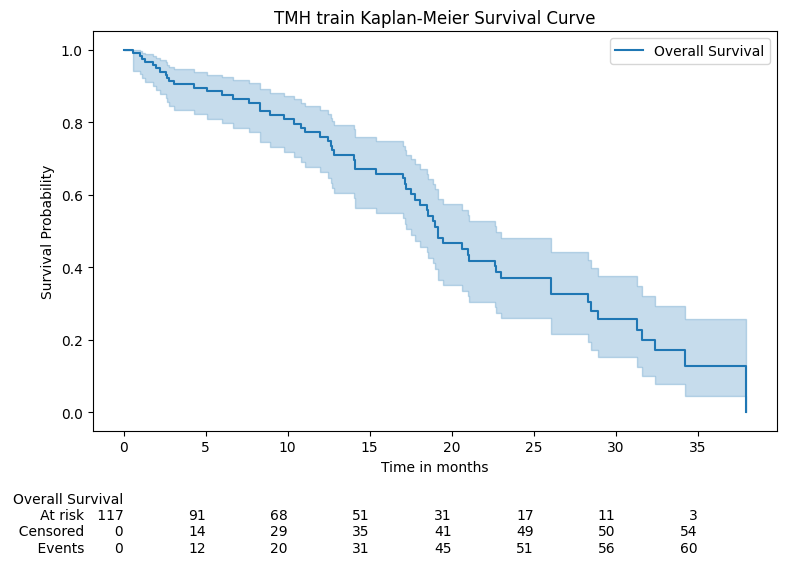

In [883]:
gb_kmplot(gb_tmh_train_surv,'TMH train')

In [879]:
gb_tmh_test_surv=pd.read_csv('gb_tmh_test_surv_months.csv')

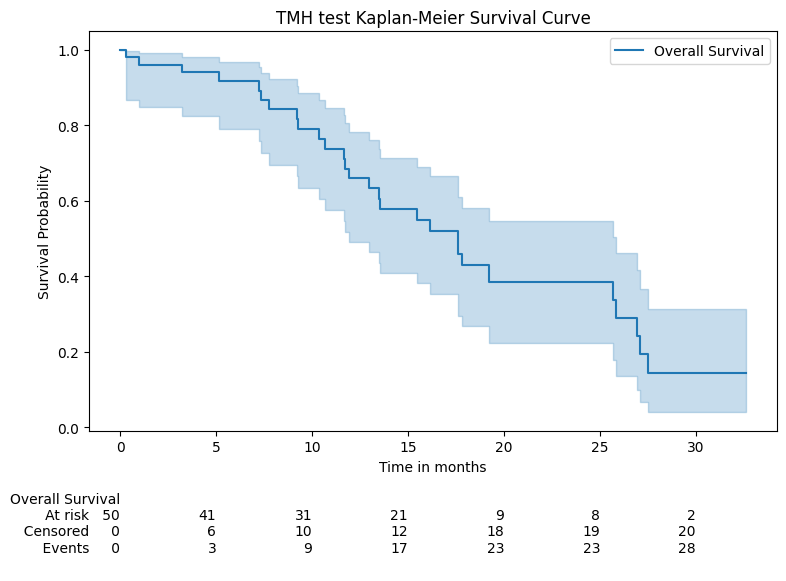

In [884]:
gb_kmplot(gb_tmh_test_surv,'TMH test')

In [871]:
gb_lung_train_surv=pd.read_csv('gb_lung_train_surv_months.csv')

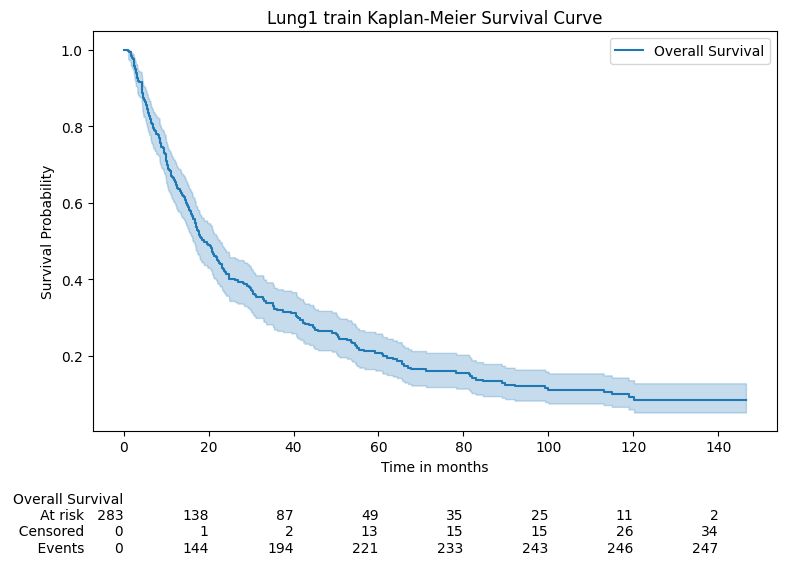

In [885]:
gb_kmplot(gb_lung_train_surv,'Lung1 train')

In [886]:
gb_lung_test_surv=pd.read_csv('gb_lung_test_surv_months.csv')

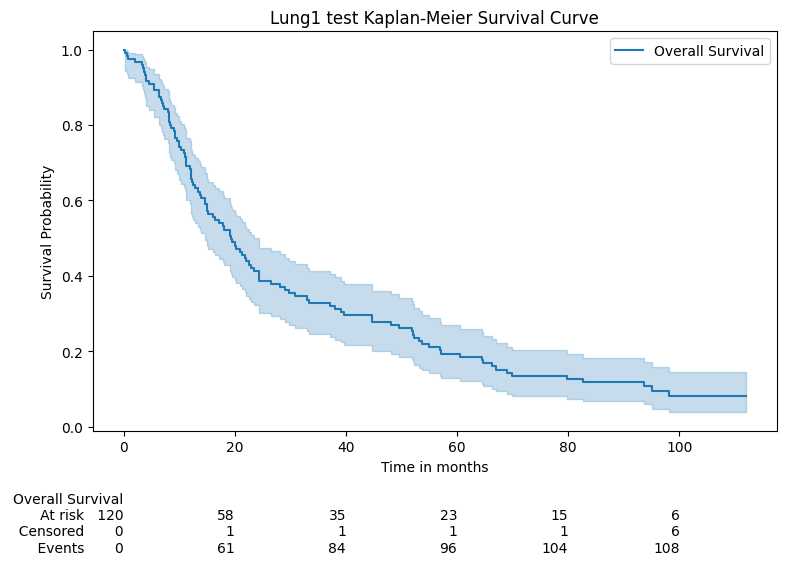

In [887]:
gb_kmplot(gb_lung_test_surv,'Lung1 test')

In [160]:
gb_lung_train_surv.head()

,Patient,time,event
0,LUNG1-001,71.217105,1
1,LUNG1-002,5.098684,1
2,LUNG1-003,8.421053,1
3,LUNG1-004,4.638158,1
4,LUNG1-005,11.611842,1


In [161]:
gb_lung_test_surv.head()

,Patient,time,event
0,LUNG1-297,111.136662,0
1,LUNG1-298,22.963206,1
2,LUNG1-299,33.015769,1
3,LUNG1-300,24.342970,1
4,LUNG1-301,7.128778,1


In [162]:
gb_tmh_train_surv.head()

,Patient,time,event
0,105131012,7.982917,0
1,108689672,33.278581,0
2,110348284,3.022339,0
3,118623647,20.959264,0
4,120433028,1.018397,1


In [163]:
gb_tmh_test_surv.head()

,Patient,time,event
0,732711211,4.237845,0
1,733252502,5.059133,0
2,736734885,5.157687,0
3,737830347,32.588699,0
4,738450152,32.194481,0


In [ ]:
# habitat features for survival

In [272]:
import os
import numpy as np
import pandas as pd

from scipy import ndimage
from collections import Counter


def extract_survival_habitat_features(
    habitat_map,
    valid_mask,
    spacing=(2.0, 2.0, 2.0),
    n_habitats=4
):
    """
    Extract compact habitat composition + spatial features
    for survival analysis.

    Parameters
    ----------
    habitat_map : ndarray
        3D integer habitat map, shape (Z,Y,X).

    valid_mask : ndarray
        Boolean 3D mask indicating valid radiomics voxels.

    spacing : tuple
        Voxel spacing in (Z,Y,X) mm.

    n_habitats : int
        Number of SOM habitats.
        2x2 -> 4
        3x3 -> 9
        4x4 -> 16

    Returns
    -------
    result : dict
        One patient-level feature dictionary.
    """

    habitat_map = np.asarray(habitat_map)
    valid_mask = np.asarray(valid_mask).astype(bool)

    if habitat_map.shape != valid_mask.shape:
        raise ValueError(
            f"Shape mismatch: habitat_map={habitat_map.shape}, "
            f"valid_mask={valid_mask.shape}"
        )

    # --------------------------------------------------
    # Keep only valid habitat voxels
    # --------------------------------------------------

    labels = habitat_map[valid_mask].astype(np.int16)

    labels = labels[
        (labels >= 0) &
        (labels < n_habitats)
    ]

    if len(labels) == 0:
        raise ValueError("No valid habitat voxels found.")

    total_valid = len(labels)

    voxel_volume_mm3 = np.prod(spacing)

    result = {}

    # --------------------------------------------------
    # HABITAT PROPORTION + VOLUME
    # --------------------------------------------------

    counts = np.bincount(
        labels,
        minlength=n_habitats
    )

    proportions = counts / total_valid

    for h in range(n_habitats):

        result[f"H{h}_proportion"] = proportions[h]

        result[f"H{h}_volume_mm3"] = (
            counts[h] * voxel_volume_mm3
        )

    # --------------------------------------------------
    # HABITAT ENTROPY
    # --------------------------------------------------

    p = proportions[proportions > 0]

    entropy = -np.sum(
        p * np.log2(p)
    )

    result["habitat_entropy"] = entropy

    # --------------------------------------------------
    # OCCUPIED HABITATS
    # --------------------------------------------------

    result["occupied_habitats"] = int(
        np.sum(counts > 0)
    )

    # --------------------------------------------------
    # CONNECTED COMPONENT FEATURES
    # --------------------------------------------------

    connectivity = ndimage.generate_binary_structure(
        rank=3,
        connectivity=1
    )

    for h in range(n_habitats):

        binary = (
            (habitat_map == h) &
            valid_mask
        )

        if not np.any(binary):

            result[f"H{h}_components"] = 0

            result[f"H{h}_largest_component_fraction"] = 0.0

            continue

        labeled, n_components = ndimage.label(
            binary,
            structure=connectivity
        )

        component_sizes = np.bincount(
            labeled.ravel()
        )[1:]

        largest = component_sizes.max()

        result[f"H{h}_components"] = int(
            n_components
        )

        result[f"H{h}_largest_component_fraction"] = (
            largest / component_sizes.sum()
        )

    # --------------------------------------------------
    # HABITAT TRANSITIONS
    # --------------------------------------------------
    # Count neighboring voxel pairs with different
    # habitat labels.
    # --------------------------------------------------

    transition_counts = Counter()

    # X direction
    a = habitat_map[:, :, :-1]
    b = habitat_map[:, :, 1:]

    valid_a = valid_mask[:, :, :-1]
    valid_b = valid_mask[:, :, 1:]

    valid = valid_a & valid_b & (a != b)

    pairs = zip(
        a[valid].ravel(),
        b[valid].ravel()
    )

    for x, y in pairs:

        if (
            0 <= x < n_habitats and
            0 <= y < n_habitats
        ):

            pair = tuple(
                sorted((int(x), int(y)))
            )

            transition_counts[pair] += 1

    # Y direction
    a = habitat_map[:, :-1, :]
    b = habitat_map[:, 1:, :]

    valid_a = valid_mask[:, :-1, :]
    valid_b = valid_mask[:, 1:, :]

    valid = valid_a & valid_b & (a != b)

    pairs = zip(
        a[valid].ravel(),
        b[valid].ravel()
    )

    for x, y in pairs:

        if (
            0 <= x < n_habitats and
            0 <= y < n_habitats
        ):

            pair = tuple(
                sorted((int(x), int(y)))
            )

            transition_counts[pair] += 1

    # Z direction
    a = habitat_map[:-1, :, :]
    b = habitat_map[1:, :, :]

    valid_a = valid_mask[:-1, :, :]
    valid_b = valid_mask[1:, :, :]

    valid = valid_a & valid_b & (a != b)

    pairs = zip(
        a[valid].ravel(),
        b[valid].ravel()
    )

    for x, y in pairs:

        if (
            0 <= x < n_habitats and
            0 <= y < n_habitats
        ):

            pair = tuple(
                sorted((int(x), int(y)))
            )

            transition_counts[pair] += 1

    # --------------------------------------------------
    # TRANSITION ENTROPY
    # --------------------------------------------------

    total_transitions = sum(
        transition_counts.values()
    )

    if total_transitions > 0:

        transition_p = np.array(
            list(transition_counts.values()),
            dtype=float
        )

        transition_p /= transition_p.sum()

        transition_entropy = -np.sum(
            transition_p *
            np.log2(transition_p)
        )

    else:

        transition_entropy = 0.0

    result["transition_entropy"] = (
        transition_entropy
    )

    # --------------------------------------------------
    # BOUNDARY DENSITY
    # --------------------------------------------------
    # Different-habitat voxel faces / valid voxel volume
    # --------------------------------------------------

    boundary_faces = total_transitions

    total_volume_mm3 = (
        total_valid * voxel_volume_mm3
    )

    if total_volume_mm3 > 0:

        boundary_density = (
            boundary_faces /
            total_volume_mm3
        )

    else:

        boundary_density = 0.0

    result["boundary_faces"] = int(
        boundary_faces
    )

    result["boundary_density"] = (
        boundary_density
    )

    # --------------------------------------------------
    # TOTAL VALID VOLUME
    # --------------------------------------------------

    result["valid_volume_mm3"] = (
        total_volume_mm3
    )

    return result

In [583]:
valid_mask = np.any(
    np.abs(maps) > 0,
    axis=0
)

print("Valid mask shape:", valid_mask.shape)
print("Valid voxels:", valid_mask.sum())
print("Background voxels:", (~valid_mask).sum())

Valid mask shape: (52, 47, 45)
Valid voxels: 96750
Background voxels: 13230


In [587]:
features = extract_survival_habitat_features(
    habitat_map=habitat_map,
    valid_mask=valid_mask_3d,
    spacing=ref_img.GetSpacing()[::-1],
    n_habitats=9
)

In [588]:
features

{'H0_proportion': 0.3012299741602067,
 'H0_volume_mm3': 233152.0,
 'H1_proportion': 0.3276485788113695,
 'H1_volume_mm3': 253600.0,
 'H2_proportion': 0.22352454780361758,
 'H2_volume_mm3': 173008.0,
 'H3_proportion': 0.08632558139534884,
 'H3_volume_mm3': 66816.0,
 'H4_proportion': 0.042160206718346256,
 'H4_volume_mm3': 32632.0,
 'H5_proportion': 0.0182015503875969,
 'H5_volume_mm3': 14088.0,
 'H6_proportion': 0.0,
 'H6_volume_mm3': 0.0,
 'H7_proportion': 6.201550387596899e-05,
 'H7_volume_mm3': 48.0,
 'H8_proportion': 0.0008475452196382429,
 'H8_volume_mm3': 656.0,
 'habitat_entropy': 2.1444208298373364,
 'occupied_habitats': 8,
 'H0_components': 479,
 'H0_largest_component_fraction': 0.9080771342300302,
 'H1_components': 493,
 'H1_largest_component_fraction': 0.9660567823343849,
 'H2_components': 263,
 'H2_largest_component_fraction': 0.9720244150559512,
 'H3_components': 1347,
 'H3_largest_component_fraction': 0.21851053639846743,
 'H4_components': 530,
 'H4_largest_component_fract

In [589]:
def collect_cohort_survival_features(
    patient_results,
    spacing=(2.0, 2.0, 2.0),
    n_habitats=9
):
    """
    Collect habitat-based survival features for all patients.

    Parameters
    ----------
    patient_results : list of dict
        Each item must contain:
            patient_id
            habitat_map   : 3D habitat map
            valid_mask    : 3D boolean radiomics mask

    spacing : tuple
        Voxel spacing in (Z, Y, X) order.

    n_habitats : int
        Number of SOM habitats.
        For 3x3 SOM = 9.

    Returns
    -------
    df : pandas.DataFrame
        One row per patient.
    """

    rows = []

    for item in patient_results:

        patient_id = item["patient_id"]

        habitat_map = item["habitat_map"]
        valid_mask = item["valid_mask"]

        # --------------------------------------------------
        # Safety checks
        # --------------------------------------------------

        if habitat_map.shape != valid_mask.shape:
            raise ValueError(
                f"{patient_id}: shape mismatch "
                f"habitat_map={habitat_map.shape}, "
                f"valid_mask={valid_mask.shape}"
            )

        # --------------------------------------------------
        # Extract habitat + spatial survival features
        # --------------------------------------------------

        features = extract_survival_habitat_features(
            habitat_map=habitat_map,
            valid_mask=valid_mask,
            spacing=spacing,
            n_habitats=n_habitats
        )

        # Patient ID
        features["patient_id"] = patient_id

        rows.append(features)

    # ------------------------------------------------------
    # Convert to DataFrame
    # ------------------------------------------------------

    df = pd.DataFrame(rows)

    # Patient ID first
    cols = (
        ["patient_id"] +
        [c for c in df.columns if c != "patient_id"]
    )

    df = df[cols]

    print("\n===================================")
    print("SURVIVAL HABITAT FEATURES")
    print("===================================")
    print("Patients :", len(df))
    print("Features :", len(df.columns) - 1)
    print("Shape    :", df.shape)
    print("===================================")

    return df

In [593]:
tmh_train_features = collect_cohort_survival_features(
    patient_results=tmh_train_results,
    spacing=(2.0, 2.0, 2.0),
    n_habitats=9
)

NameError: name 'tmh_train_results' is not defined

In [592]:
del(tmh_train_features)

In [598]:
### Patient-level feature extraction
import os
import numpy as np
import pandas as pd
import joblib
from tqdm.auto import tqdm

def extract_patient_survival_features(
    patient_id,
    patient_dir,
    model,
    scaler,
    som_model,
    n_habitats=9,
    spacing=(2.0, 2.0, 2.0)
):

    # --------------------------------------------------
    # Load selected GLDM maps
    # --------------------------------------------------

    maps, ref_img, feature_names = load_feature_maps(
        patient_dir,
        FEATURES
    )

    # (10,Z,Y,X) -> (N,10)
    voxels, volume_shape, _ = maps_to_voxels(maps)

    # --------------------------------------------------
    # Valid radiomics voxels
    # --------------------------------------------------

    valid_mask_3d = np.any(
        np.abs(maps) > 0,
        axis=0
    )

    valid_mask_flat = valid_mask_3d.ravel()

    valid_voxels = voxels[
        valid_mask_flat
    ]

    # --------------------------------------------------
    # Z-score scaling
    # --------------------------------------------------

    valid_voxels_scaled = scaler.transform(
        valid_voxels
    ).astype(np.float32)

    # --------------------------------------------------
    # AE latent
    # --------------------------------------------------

    latent_valid = get_latent(
        model,
        valid_voxels_scaled,
        batch_size=131072
    )

    # --------------------------------------------------
    # SOM habitat assignment
    # --------------------------------------------------

    labels_valid = som_predict(
        som_model,
        latent_valid
    )

    # --------------------------------------------------
    # Reconstruct full 3D habitat map
    #
    # -1 = background / invalid voxel
    #  0...(n_habitats-1) = actual habitats
    # --------------------------------------------------

    habitat_map = np.full(
        volume_shape,
        -1,
        dtype=np.int16
    )

    habitat_map[
        valid_mask_3d
    ] = labels_valid

    # --------------------------------------------------
    # Survival features
    # --------------------------------------------------

    features = extract_survival_habitat_features(
        habitat_map=habitat_map,
        valid_mask=valid_mask_3d,
        spacing=spacing,
        n_habitats=n_habitats
    )

    features["patient_id"] = patient_id

    return features

In [ ]:
gb

In [599]:
def collect_all_patients(
    patient_list,
    cohort_name,
    model,
    scaler,
    som_model,
    n_habitats=9,
    spacing=(2.0, 2.0, 2.0)
):

    rows = []

    for patient_dir in tqdm(
        patient_list,
        desc=f"Processing {cohort_name}"
    ):

        patient_id = os.path.basename(
            os.path.normpath(patient_dir)
        )

        try:

            features = extract_patient_survival_features(
                patient_id=patient_id,
                patient_dir=patient_dir,
                model=model,
                scaler=scaler,
                som_model=som_model,
                n_habitats=n_habitats,
                spacing=spacing
            )

            rows.append(features)

        except Exception as e:

            print(
                f"\nERROR: {patient_id}: {e}"
            )

    df = pd.DataFrame(rows)

    if len(df) == 0:
        raise RuntimeError(
            f"No patients processed successfully for {cohort_name}"
        )

    cols = (
        ["patient_id"] +
        [c for c in df.columns if c != "patient_id"]
    )

    df = df[cols]

    print("\n===================================")
    print(f"{cohort_name} COMPLETE")
    print("Patients successfully processed:", len(df))
    print("Feature columns:", len(df.columns) - 1)
    print("===================================")

    return df

#### collect survival habitats for all patients

In [601]:
tmh_train_features = collect_all_patients(
    tmh_train_patients,
    "TMH TRAIN",
    model,
    z_scaler,
    som_3x3,
    n_habitats=9
)

Processing TMH TRAIN:   0%|          | 0/117 [00:00<?, ?it/s]

Loaded 10 selected features
Features: ['DependenceEntropy', 'DependenceNonUniformity', 'DependenceVariance', 'HighGrayLevelEmphasis', 'LargeDependenceHighGrayLevelEmphasis', 'LargeDependenceLowGrayLevelEmphasis', 'LowGrayLevelEmphasis', 'SmallDependenceEmphasis', 'SmallDependenceHighGrayLevelEmphasis', 'SmallDependenceLowGrayLevelEmphasis']
Shape: (10, 69, 61, 57)
Voxel matrix created
Feature maps : 10
Volume shape : (69, 61, 57)
Total voxels : 239,913
Matrix shape : (239913, 10)


  0%|          | 0/2 [00:00<?, ?it/s]

Loaded 10 selected features
Features: ['DependenceEntropy', 'DependenceNonUniformity', 'DependenceVariance', 'HighGrayLevelEmphasis', 'LargeDependenceHighGrayLevelEmphasis', 'LargeDependenceLowGrayLevelEmphasis', 'LowGrayLevelEmphasis', 'SmallDependenceEmphasis', 'SmallDependenceHighGrayLevelEmphasis', 'SmallDependenceLowGrayLevelEmphasis']
Shape: (10, 47, 50, 44)
Voxel matrix created
Feature maps : 10
Volume shape : (47, 50, 44)
Total voxels : 103,400
Matrix shape : (103400, 10)


  0%|          | 0/1 [00:00<?, ?it/s]

Loaded 10 selected features
Features: ['DependenceEntropy', 'DependenceNonUniformity', 'DependenceVariance', 'HighGrayLevelEmphasis', 'LargeDependenceHighGrayLevelEmphasis', 'LargeDependenceLowGrayLevelEmphasis', 'LowGrayLevelEmphasis', 'SmallDependenceEmphasis', 'SmallDependenceHighGrayLevelEmphasis', 'SmallDependenceLowGrayLevelEmphasis']
Shape: (10, 73, 63, 73)
Voxel matrix created
Feature maps : 10
Volume shape : (73, 63, 73)
Total voxels : 335,727
Matrix shape : (335727, 10)


... (226 outputs left out)

  0%|          | 0/2 [00:00<?, ?it/s]

Loaded 10 selected features
Features: ['DependenceEntropy', 'DependenceNonUniformity', 'DependenceVariance', 'HighGrayLevelEmphasis', 'LargeDependenceHighGrayLevelEmphasis', 'LargeDependenceLowGrayLevelEmphasis', 'LowGrayLevelEmphasis', 'SmallDependenceEmphasis', 'SmallDependenceHighGrayLevelEmphasis', 'SmallDependenceLowGrayLevelEmphasis']
Shape: (10, 40, 59, 44)
Voxel matrix created
Feature maps : 10
Volume shape : (40, 59, 44)
Total voxels : 103,840
Matrix shape : (103840, 10)


  0%|          | 0/1 [00:00<?, ?it/s]


TMH TRAIN COMPLETE
Patients successfully processed: 117
Feature columns: 42


In [607]:
tmh_train_features.iloc[0:1]

,patient_id,H0_proportion,H0_volume_mm3,H1_proportion,H1_volume_mm3,H2_proportion,H2_volume_mm3,H3_proportion,H3_volume_mm3,H4_proportion,...,H6_components,H6_largest_component_fraction,H7_components,H7_largest_component_fraction,H8_components,H8_largest_component_fraction,transition_entropy,boundary_faces,boundary_density,valid_volume_mm3
0,105131012,0.320245,556896.0,0.251634,437584.0,0.219684,382024.0,0.090817,157928.0,0.046041,...,1,1.0,19,0.090909,8,0.785467,2.874351,249791,0.143643,1738968.0


In [610]:
tmh_test_features.iloc[0:1]

,patient_id,H0_proportion,H0_volume_mm3,H1_proportion,H1_volume_mm3,H2_proportion,H2_volume_mm3,H3_proportion,H3_volume_mm3,H4_proportion,...,H6_components,H6_largest_component_fraction,H7_components,H7_largest_component_fraction,H8_components,H8_largest_component_fraction,transition_entropy,boundary_faces,boundary_density,valid_volume_mm3
0,732711211,0.159812,120712.0,0.339409,256368.0,0.349662,264112.0,0.04513,34088.0,0.024445,...,0,0.0,0,0.0,16,0.663333,2.486706,109612,0.145117,755336.0


In [609]:
tmh_test_features = collect_all_patients(
    tmh_test_patients,
    "TMH TEST",
    model,
    z_scaler,
    som_3x3,
    n_habitats=9
)


Processing TMH TEST:   0%|          | 0/50 [00:00<?, ?it/s]

Loaded 10 selected features
Features: ['DependenceEntropy', 'DependenceNonUniformity', 'DependenceVariance', 'HighGrayLevelEmphasis', 'LargeDependenceHighGrayLevelEmphasis', 'LargeDependenceLowGrayLevelEmphasis', 'LowGrayLevelEmphasis', 'SmallDependenceEmphasis', 'SmallDependenceHighGrayLevelEmphasis', 'SmallDependenceLowGrayLevelEmphasis']
Shape: (10, 39, 60, 46)
Voxel matrix created
Feature maps : 10
Volume shape : (39, 60, 46)
Total voxels : 107,640
Matrix shape : (107640, 10)


  0%|          | 0/1 [00:00<?, ?it/s]

Loaded 10 selected features
Features: ['DependenceEntropy', 'DependenceNonUniformity', 'DependenceVariance', 'HighGrayLevelEmphasis', 'LargeDependenceHighGrayLevelEmphasis', 'LargeDependenceLowGrayLevelEmphasis', 'LowGrayLevelEmphasis', 'SmallDependenceEmphasis', 'SmallDependenceHighGrayLevelEmphasis', 'SmallDependenceLowGrayLevelEmphasis']
Shape: (10, 84, 66, 63)
Voxel matrix created
Feature maps : 10
Volume shape : (84, 66, 63)
Total voxels : 349,272
Matrix shape : (349272, 10)


  0%|          | 0/3 [00:00<?, ?it/s]

Loaded 10 selected features
Features: ['DependenceEntropy', 'DependenceNonUniformity', 'DependenceVariance', 'HighGrayLevelEmphasis', 'LargeDependenceHighGrayLevelEmphasis', 'LargeDependenceLowGrayLevelEmphasis', 'LowGrayLevelEmphasis', 'SmallDependenceEmphasis', 'SmallDependenceHighGrayLevelEmphasis', 'SmallDependenceLowGrayLevelEmphasis']
Shape: (10, 42, 46, 44)
Voxel matrix created
Feature maps : 10
Volume shape : (42, 46, 44)
Total voxels : 85,008
Matrix shape : (85008, 10)


... (92 outputs left out)

  0%|          | 0/3 [00:00<?, ?it/s]

Loaded 10 selected features
Features: ['DependenceEntropy', 'DependenceNonUniformity', 'DependenceVariance', 'HighGrayLevelEmphasis', 'LargeDependenceHighGrayLevelEmphasis', 'LargeDependenceLowGrayLevelEmphasis', 'LowGrayLevelEmphasis', 'SmallDependenceEmphasis', 'SmallDependenceHighGrayLevelEmphasis', 'SmallDependenceLowGrayLevelEmphasis']
Shape: (10, 62, 62, 59)
Voxel matrix created
Feature maps : 10
Volume shape : (62, 62, 59)
Total voxels : 226,796
Matrix shape : (226796, 10)


  0%|          | 0/2 [00:00<?, ?it/s]


TMH TEST COMPLETE
Patients successfully processed: 50
Feature columns: 42


In [611]:
gb_tmh_train_surv

,Patient,time,event
0,105131012,7.982917,0
1,108689672,33.278581,0
2,110348284,3.022339,0
3,118623647,20.959264,0
4,120433028,1.018397,1
...,...,...,...
112,712218237,1.149803,1
113,726104322,3.679369,0
114,728207938,11.070959,1
115,728966239,28.515112,1


In [281]:
gb_tmh_train_surv_2=gb_tmh_train_surv.copy()

In [282]:
gb_tmh_test_surv_2=gb_tmh_test_surv.copy()

In [283]:
gb_tmh_train_surv_2.rename(columns={'Patient':'patient_id'},inplace=True)

In [284]:
gb_tmh_test_surv_2.rename(columns={'Patient':'patient_id'},inplace=True)

In [612]:
gb_tmh_train_surv_2

,patient_id,time,event
0,105131012,7.982917,0
1,108689672,33.278581,0
2,110348284,3.022339,0
3,118623647,20.959264,0
4,120433028,1.018397,1
...,...,...,...
112,712218237,1.149803,1
113,726104322,3.679369,0
114,728207938,11.070959,1
115,728966239,28.515112,1


In [613]:
gb_tmh_test_surv_2

,patient_id,time,event
0,732711211,4.237845,0
1,733252502,5.059133,0
2,736734885,5.157687,0
3,737830347,32.588699,0
4,738450152,32.194481,0
5,738603912,17.575558,1
6,745213077,9.198423,0
7,747076016,11.727989,1
8,751861632,16.130092,1
9,761517263,3.515112,0


In [614]:
gb_tmh_train_surv['Patient'][50]

404861880

In [617]:
tmh_train_features

,patient_id,H0_proportion,H0_volume_mm3,H1_proportion,H1_volume_mm3,H2_proportion,H2_volume_mm3,H3_proportion,H3_volume_mm3,H4_proportion,...,H6_components,H6_largest_component_fraction,H7_components,H7_largest_component_fraction,H8_components,H8_largest_component_fraction,transition_entropy,boundary_faces,boundary_density,valid_volume_mm3
0,105131012,0.320245,556896.0,0.251634,437584.0,0.219684,382024.0,0.090817,157928.0,0.046041,...,1,1.000000,19,0.090909,8,0.785467,2.874351,249791,0.143643,1738968.0
1,108689672,0.398127,288384.0,0.261232,189224.0,0.138684,100456.0,0.101023,73176.0,0.083683,...,0,0.000000,1,1.000000,6,0.837209,2.582230,95959,0.132476,724352.0
2,110348284,0.451138,1109384.0,0.223625,549912.0,0.149513,367664.0,0.117006,287728.0,0.037419,...,5,0.500000,63,0.118110,59,0.216807,2.562591,311917,0.126843,2459080.0
3,118623647,0.385205,977176.0,0.186726,473680.0,0.126435,320736.0,0.121566,308384.0,0.162802,...,0,0.000000,0,0.000000,92,0.591727,2.717679,334498,0.131860,2536768.0
4,120433028,0.402447,838272.0,0.241985,504040.0,0.149255,310888.0,0.117331,244392.0,0.055022,...,33,0.142857,153,0.043605,53,0.874931,2.694936,273883,0.131489,2082936.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112,712218237,0.458022,980976.0,0.224118,480008.0,0.141887,303888.0,0.103287,221216.0,0.034812,...,0,0.000000,20,0.166667,47,0.720195,2.674369,279852,0.130664,2141768.0
113,726104322,0.298294,159912.0,0.378415,202864.0,0.249302,133648.0,0.035248,18896.0,0.011207,...,0,0.000000,0,0.000000,2,0.509434,2.113348,69369,0.129399,536088.0
114,728207938,0.324627,557928.0,0.266750,458456.0,0.184352,316840.0,0.089711,154184.0,0.071097,...,152,0.107425,120,0.164835,136,0.232719,2.957966,237431,0.138148,1718672.0
115,728966239,0.340685,600448.0,0.286684,505272.0,0.162122,285736.0,0.107703,189824.0,0.076797,...,5,0.444444,52,0.132075,40,0.242300,2.673233,240878,0.136671,1762472.0


In [616]:
tmh_train_features['patient_id'] = (
    tmh_train_features['patient_id']
    .astype(str)
    .str.strip()
)

gb_tmh_train_surv_2['patient_id'] = (
    gb_tmh_train_surv_2['patient_id']
    .astype(str)
    .str.strip()
)

gb_tmh_train_hab_surv = pd.merge(
    tmh_train_features,
    gb_tmh_train_surv_2,
    on='patient_id',
    how='left'
)

print(gb_tmh_train_hab_surv.shape)

(117, 25)
  patient_id  H0_proportion  H0_volume_mm3  H1_proportion  H1_volume_mm3  \
0  105131012            1.0      1738968.0            0.0            0.0   
1  108689672            1.0       724352.0            0.0            0.0   
2  110348284            1.0      2459080.0            0.0            0.0   
3  118623647            1.0      2536768.0            0.0            0.0   
4  120433028            1.0      2082936.0            0.0            0.0   

   H2_proportion  H2_volume_mm3  H3_proportion  H3_volume_mm3  \
0            0.0            0.0            0.0            0.0   
1            0.0            0.0            0.0            0.0   
2            0.0            0.0            0.0            0.0   
3            0.0            0.0            0.0            0.0   
4            0.0            0.0            0.0            0.0   

   habitat_entropy  ...  H2_components  H2_largest_component_fraction  \
0             -0.0  ...              0                            0.0

In [621]:
# add survival time and event for the habitats


tmh_test_features['patient_id'] = (
    tmh_test_features['patient_id']
    .astype(str)
    .str.strip()
)

gb_tmh_test_surv_2['patient_id'] = (
    gb_tmh_test_surv_2['patient_id']
    .astype(str)
    .str.strip()
)

gb_tmh_test_hab_surv = pd.merge(
    tmh_test_features,
    gb_tmh_test_surv_2,
    on='patient_id',
    how='left'
)

print(gb_tmh_test_hab_surv.shape)

(50, 45)


In [622]:
gb_tmh_train_hab_surv.head()

,patient_id,H0_proportion,H0_volume_mm3,H1_proportion,H1_volume_mm3,H2_proportion,H2_volume_mm3,H3_proportion,H3_volume_mm3,H4_proportion,...,H7_components,H7_largest_component_fraction,H8_components,H8_largest_component_fraction,transition_entropy,boundary_faces,boundary_density,valid_volume_mm3,time,event
0,105131012,0.320245,556896.0,0.251634,437584.0,0.219684,382024.0,0.090817,157928.0,0.046041,...,19,0.090909,8,0.785467,2.874351,249791,0.143643,1738968.0,7.982917,0
1,108689672,0.398127,288384.0,0.261232,189224.0,0.138684,100456.0,0.101023,73176.0,0.083683,...,1,1.000000,6,0.837209,2.582230,95959,0.132476,724352.0,33.278581,0
2,110348284,0.451138,1109384.0,0.223625,549912.0,0.149513,367664.0,0.117006,287728.0,0.037419,...,63,0.118110,59,0.216807,2.562591,311917,0.126843,2459080.0,3.022339,0
3,118623647,0.385205,977176.0,0.186726,473680.0,0.126435,320736.0,0.121566,308384.0,0.162802,...,0,0.000000,92,0.591727,2.717679,334498,0.131860,2536768.0,20.959264,0
4,120433028,0.402447,838272.0,0.241985,504040.0,0.149255,310888.0,0.117331,244392.0,0.055022,...,153,0.043605,53,0.874931,2.694936,273883,0.131489,2082936.0,1.018397,1


In [623]:
gb_tmh_test_hab_surv.head()

,patient_id,H0_proportion,H0_volume_mm3,H1_proportion,H1_volume_mm3,H2_proportion,H2_volume_mm3,H3_proportion,H3_volume_mm3,H4_proportion,...,H7_components,H7_largest_component_fraction,H8_components,H8_largest_component_fraction,transition_entropy,boundary_faces,boundary_density,valid_volume_mm3,time,event
0,732711211,0.159812,120712.0,0.339409,256368.0,0.349662,264112.0,0.045130,34088.0,0.024445,...,0,0.00000,16,0.663333,2.486706,109612,0.145117,755336.0,4.237845,0
1,733252502,0.407807,1043888.0,0.188946,483656.0,0.119052,304744.0,0.150580,385448.0,0.104422,...,76,0.17284,6,0.442623,2.779898,367480,0.143560,2559760.0,5.059133,0
2,736734885,0.206048,121784.0,0.205493,121456.0,0.445473,263296.0,0.063453,37504.0,0.055684,...,0,0.00000,6,0.395062,2.436346,67707,0.114554,591048.0,5.157687,0
3,737830347,0.403790,233016.0,0.386739,223176.0,0.128344,74064.0,0.051682,29824.0,0.025785,...,0,0.00000,2,0.958333,2.113495,69909,0.121144,577072.0,32.588699,0
4,738450152,0.323497,342304.0,0.064665,68424.0,0.040706,43072.0,0.175637,185848.0,0.393915,...,0,0.00000,12,0.288889,2.196011,128688,0.121618,1058136.0,32.194481,0


In [624]:
tmh_train_features['H1_volume_mm3'].value_counts()

H1_volume_mm3
437584.0    1
339296.0    1
138408.0    1
404136.0    1
243664.0    1
           ..
614072.0    1
295792.0    1
116088.0    1
409616.0    1
197376.0    1
Name: count, Length: 117, dtype: int64

In [ ]:
tmh_train_features = collect_all_patients(
    tmh_train_patients,
    "TMH TRAIN",
    model,
    z_scaler,
    som_model,
    n_habitats=4
)

tmh_test_features = collect_all_patients(
    tmh_test_patients,
    "TMH TEST",
    model,
    z_scaler,
    som_model,
    n_habitats=4
)

lung_train_features = collect_all_patients(
    lung_train_patients,
    "LUNG1 TRAIN",
    model,
    z_scaler,
    som_model,
    n_habitats=4
)

lung_test_features = collect_all_patients(
    lung_test_patients,
    "LUNG1 TEST",
    model,
    z_scaler,
    som_model,
    n_habitats=4
)

#### quick lasso cox fitting and risk score plotting on ct 

In [626]:
train_df= gb_tmh_train_hab_surv

In [628]:
test_df = gb_tmh_test_hab_surv

In [629]:
gb_tmh_test_hab_surv.columns

Index(['patient_id', 'H0_proportion', 'H0_volume_mm3', 'H1_proportion',
       'H1_volume_mm3', 'H2_proportion', 'H2_volume_mm3', 'H3_proportion',
       'H3_volume_mm3', 'H4_proportion', 'H4_volume_mm3', 'H5_proportion',
       'H5_volume_mm3', 'H6_proportion', 'H6_volume_mm3', 'H7_proportion',
       'H7_volume_mm3', 'H8_proportion', 'H8_volume_mm3', 'habitat_entropy',
       'occupied_habitats', 'H0_components', 'H0_largest_component_fraction',
       'H1_components', 'H1_largest_component_fraction', 'H2_components',
       'H2_largest_component_fraction', 'H3_components',
       'H3_largest_component_fraction', 'H4_components',
       'H4_largest_component_fraction', 'H5_components',
       'H5_largest_component_fraction', 'H6_components',
       'H6_largest_component_fraction', 'H7_components',
       'H7_largest_component_fraction', 'H8_components',
       'H8_largest_component_fraction', 'transition_entropy', 'boundary_faces',
       'boundary_density', 'valid_volume_mm3', 'time

In [845]:
gb_tmh_test_hab_surv.columns

Index(['patient_id', 'H0_proportion', 'H0_volume_mm3', 'H1_proportion',
       'H1_volume_mm3', 'H2_proportion', 'H2_volume_mm3', 'H3_proportion',
       'H3_volume_mm3', 'H4_proportion', 'H4_volume_mm3', 'H5_proportion',
       'H5_volume_mm3', 'H6_proportion', 'H6_volume_mm3', 'H7_proportion',
       'H7_volume_mm3', 'H8_proportion', 'H8_volume_mm3', 'habitat_entropy',
       'occupied_habitats', 'H0_components', 'H0_largest_component_fraction',
       'H1_components', 'H1_largest_component_fraction', 'H2_components',
       'H2_largest_component_fraction', 'H3_components',
       'H3_largest_component_fraction', 'H4_components',
       'H4_largest_component_fraction', 'H5_components',
       'H5_largest_component_fraction', 'H6_components',
       'H6_largest_component_fraction', 'H7_components',
       'H7_largest_component_fraction', 'H8_components',
       'H8_largest_component_fraction', 'transition_entropy', 'boundary_faces',
       'boundary_density', 'valid_volume_mm3', 'time

In [630]:
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

time_col = "time"
event_col = "event"

# Candidate habitat features
feature_cols = [
    c for c in train_df.columns
    if c not in [
        "patient_id",
        time_col,
        event_col
    ]
]

# Drop one habitat proportion because proportions sum to 1
feature_cols = [
    c for c in feature_cols
    if c != "H3_proportion"
]

print("Number of features:", len(feature_cols))

Number of features: 41


In [631]:
#Standardize the survival features
scaler_surv = StandardScaler()

X_train = scaler_surv.fit_transform(
    train_df[feature_cols]
)

X_test = scaler_surv.transform(
    test_df[feature_cols]
)

In [632]:
train_df

,patient_id,H0_proportion,H0_volume_mm3,H1_proportion,H1_volume_mm3,H2_proportion,H2_volume_mm3,H3_proportion,H3_volume_mm3,H4_proportion,...,H7_components,H7_largest_component_fraction,H8_components,H8_largest_component_fraction,transition_entropy,boundary_faces,boundary_density,valid_volume_mm3,time,event
0,105131012,0.320245,556896.0,0.251634,437584.0,0.219684,382024.0,0.090817,157928.0,0.046041,...,19,0.090909,8,0.785467,2.874351,249791,0.143643,1738968.0,7.982917,0
1,108689672,0.398127,288384.0,0.261232,189224.0,0.138684,100456.0,0.101023,73176.0,0.083683,...,1,1.000000,6,0.837209,2.582230,95959,0.132476,724352.0,33.278581,0
2,110348284,0.451138,1109384.0,0.223625,549912.0,0.149513,367664.0,0.117006,287728.0,0.037419,...,63,0.118110,59,0.216807,2.562591,311917,0.126843,2459080.0,3.022339,0
3,118623647,0.385205,977176.0,0.186726,473680.0,0.126435,320736.0,0.121566,308384.0,0.162802,...,0,0.000000,92,0.591727,2.717679,334498,0.131860,2536768.0,20.959264,0
4,120433028,0.402447,838272.0,0.241985,504040.0,0.149255,310888.0,0.117331,244392.0,0.055022,...,153,0.043605,53,0.874931,2.694936,273883,0.131489,2082936.0,1.018397,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112,712218237,0.458022,980976.0,0.224118,480008.0,0.141887,303888.0,0.103287,221216.0,0.034812,...,20,0.166667,47,0.720195,2.674369,279852,0.130664,2141768.0,1.149803,1
113,726104322,0.298294,159912.0,0.378415,202864.0,0.249302,133648.0,0.035248,18896.0,0.011207,...,0,0.000000,2,0.509434,2.113348,69369,0.129399,536088.0,3.679369,0
114,728207938,0.324627,557928.0,0.266750,458456.0,0.184352,316840.0,0.089711,154184.0,0.071097,...,120,0.164835,136,0.232719,2.957966,237431,0.138148,1718672.0,11.070959,1
115,728966239,0.340685,600448.0,0.286684,505272.0,0.162122,285736.0,0.107703,189824.0,0.076797,...,52,0.132075,40,0.242300,2.673233,240878,0.136671,1762472.0,28.515112,1


In [633]:
feature_cols

['H0_proportion',
 'H0_volume_mm3',
 'H1_proportion',
 'H1_volume_mm3',
 'H2_proportion',
 'H2_volume_mm3',
 'H3_volume_mm3',
 'H4_proportion',
 'H4_volume_mm3',
 'H5_proportion',
 'H5_volume_mm3',
 'H6_proportion',
 'H6_volume_mm3',
 'H7_proportion',
 'H7_volume_mm3',
 'H8_proportion',
 'H8_volume_mm3',
 'habitat_entropy',
 'occupied_habitats',
 'H0_components',
 'H0_largest_component_fraction',
 'H1_components',
 'H1_largest_component_fraction',
 'H2_components',
 'H2_largest_component_fraction',
 'H3_components',
 'H3_largest_component_fraction',
 'H4_components',
 'H4_largest_component_fraction',
 'H5_components',
 'H5_largest_component_fraction',
 'H6_components',
 'H6_largest_component_fraction',
 'H7_components',
 'H7_largest_component_fraction',
 'H8_components',
 'H8_largest_component_fraction',
 'transition_entropy',
 'boundary_faces',
 'boundary_density',
 'valid_volume_mm3']

In [634]:
train_model = pd.DataFrame(
    X_train,
    columns=feature_cols,
    index=train_df.index
)

train_model[time_col] = train_df['time'].values
train_model[event_col] = train_df['event'].values

In [635]:
test_model = pd.DataFrame(
    X_test,
    columns=feature_cols,
    index=test_df.index
)

test_model[time_col] = test_df['time'].values
test_model[event_col] = test_df['event'].values

In [636]:
train_model

,H0_proportion,H0_volume_mm3,H1_proportion,H1_volume_mm3,H2_proportion,H2_volume_mm3,H3_volume_mm3,H4_proportion,H4_volume_mm3,H5_proportion,...,H7_components,H7_largest_component_fraction,H8_components,H8_largest_component_fraction,transition_entropy,boundary_faces,boundary_density,valid_volume_mm3,time,event
0,0.256343,0.376779,-0.173939,0.778281,0.172330,1.270398,0.172875,-0.447635,-0.289407,0.229581,...,-0.293076,-0.365380,-0.611832,0.698077,0.727108,0.658147,0.749384,0.521734,7.982917,0
1,1.051765,-0.394609,-0.062002,-0.710846,-0.815345,-1.013425,-0.489039,0.110257,-0.400371,-0.561713,...,-0.435260,3.368372,-0.650683,0.868666,-0.159926,-0.723871,-0.471113,-0.684898,33.278581,0
2,1.593177,1.963980,-0.500605,1.451781,-0.683304,1.153923,1.186613,-0.575425,-0.221212,-0.522860,...,0.054483,-0.253662,0.378887,-1.176744,-0.219561,1.216284,-1.086704,1.378127,3.022339,0
3,0.919793,1.584170,-0.930955,0.994706,-0.964704,0.773285,1.347937,1.282886,1.610185,-0.572977,...,-0.443159,-0.738755,1.019941,0.059333,0.251369,1.419150,-0.538406,1.470518,20.959264,0
4,1.095891,1.185123,-0.286473,1.176740,-0.686451,0.693407,0.848159,-0.314524,-0.092308,-0.429322,...,0.765401,-0.559666,0.262332,0.993032,0.182310,0.874589,-0.578951,0.930798,1.018397,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112,1.663482,1.595087,-0.494861,1.032648,-0.776295,0.636630,0.667154,-0.614056,-0.320811,-0.358864,...,-0.285177,-0.054234,0.145777,0.482880,0.119859,0.928214,-0.669105,1.000764,1.149803,1
113,0.032155,-0.763686,1.304686,-0.629062,0.533477,-0.744202,-0.912966,-0.963910,-0.711949,-0.408011,...,-0.443159,-0.738755,-0.728387,-0.211979,-1.583701,-0.962754,-0.807408,-0.908791,3.679369,0
114,0.301100,0.379744,0.002354,0.903426,-0.258498,0.741685,0.143634,-0.076285,-0.049036,-0.061661,...,0.504731,-0.061756,1.874679,-1.124283,0.981008,0.547106,0.148808,0.497597,11.070959,1
115,0.465101,0.501896,0.234836,1.184127,-0.529551,0.489397,0.421983,0.008194,0.026051,-0.458922,...,-0.032406,-0.196305,0.009796,-1.092695,0.116407,0.578073,-0.012656,0.549686,28.515112,1


In [649]:
# lasso cox tuning on tmh train data

from lifelines import CoxPHFitter
from lifelines.utils import k_fold_cross_validation

penalties = [
    0.001,
    0.003,
    0.01,
    0.03,
    0.1,
    0.3,
    0.5,
    0.8,
    1.0
]

results = []

for penalty in penalties:

    cph = CoxPHFitter(
        penalizer=penalty,
        l1_ratio=1.0
    )

    scores = k_fold_cross_validation(
        cph,
        train_model,
        duration_col=time_col,
        event_col=event_col,
        k=10,
        scoring_method="concordance_index"
    )

    results.append({
        "penalty": penalty,
        "cindex_mean": np.mean(scores)
    })

results_df = pd.DataFrame(results)

print(results_df)

   penalty  cindex_mean
0    0.001     0.488366
1    0.003     0.551758
2    0.010     0.515258
3    0.030     0.502448
4    0.100     0.476667
5    0.300     0.462489
6    0.500     0.516477
7    0.800     0.477928
8    1.000     0.526619


In [650]:
print(train_model.columns.tolist())
print("\nDuration:", time_col)
print("Event:", event_col)

['H0_proportion', 'H0_volume_mm3', 'H1_proportion', 'H1_volume_mm3', 'H2_proportion', 'H2_volume_mm3', 'H3_volume_mm3', 'H4_proportion', 'H4_volume_mm3', 'H5_proportion', 'H5_volume_mm3', 'H6_proportion', 'H6_volume_mm3', 'H7_proportion', 'H7_volume_mm3', 'H8_proportion', 'H8_volume_mm3', 'habitat_entropy', 'occupied_habitats', 'H0_components', 'H0_largest_component_fraction', 'H1_components', 'H1_largest_component_fraction', 'H2_components', 'H2_largest_component_fraction', 'H3_components', 'H3_largest_component_fraction', 'H4_components', 'H4_largest_component_fraction', 'H5_components', 'H5_largest_component_fraction', 'H6_components', 'H6_largest_component_fraction', 'H7_components', 'H7_largest_component_fraction', 'H8_components', 'H8_largest_component_fraction', 'transition_entropy', 'boundary_faces', 'boundary_density', 'valid_volume_mm3', 'time', 'event']

Duration: time
Event: event


In [651]:
best_penalty = results_df.loc[
    results_df["cindex_mean"].idxmax(),
    "penalty"
]

print("Best LASSO penalty:", best_penalty)

Best LASSO penalty: 0.003


In [640]:
time_col = "time"
event_col = "event"
id_col = "patient_id"

feature_cols = [
    c for c in train_model.columns
    if c not in [time_col, event_col, id_col]
]

print("N patients:", len(train_model))
print("N features:", len(feature_cols))
print("time in features:", "time" in feature_cols)
print("event in features:", "event" in feature_cols)

N patients: 117
N features: 41
time in features: False
event in features: False


In [652]:
X = train_model[feature_cols].apply(pd.to_numeric, errors="coerce")

variance = X.var()

print(variance.sort_values().head(30))

H8_components                    1.008621
H6_largest_component_fraction    1.008621
H0_proportion                    1.008621
H8_largest_component_fraction    1.008621
H3_largest_component_fraction    1.008621
boundary_density                 1.008621
H6_volume_mm3                    1.008621
H0_largest_component_fraction    1.008621
H1_volume_mm3                    1.008621
valid_volume_mm3                 1.008621
H4_components                    1.008621
H2_proportion                    1.008621
H3_components                    1.008621
H4_proportion                    1.008621
H2_components                    1.008621
H1_largest_component_fraction    1.008621
H1_components                    1.008621
H7_components                    1.008621
H5_components                    1.008621
H0_components                    1.008621
H7_largest_component_fraction    1.008621
H8_volume_mm3                    1.008621
H0_volume_mm3                    1.008621
H3_volume_mm3                    1

In [642]:
print(train_model['occupied_habitats'].value_counts())

occupied_habitats
 1.130432    45
-1.189928    42
-0.029748    30
Name: count, dtype: int64


In [643]:
print(np.unique(habitat_ct, return_counts=True))

(array([-1,  0,  1,  2,  3,  4,  5,  7,  8], dtype=int16), array([21715176,    91229,    99535,    69143,    26039,    12879,
           5670,       18,      407]))


In [ ]:
# final cox model
best_penalty = 0.003

final_cox = CoxPHFitter(
    penalizer=best_penalty,
    l1_ratio=1.0
)

final_cox.fit(
    train_model,
    duration_col=time_col,
    event_col=event_col
)

In [655]:
final_cox.concordance_index_

0.7494047619047619

In [846]:
final_cox.concordance_index_

0.7494047619047619

In [670]:
# generate test risk score


test_model = pd.DataFrame(
    X_test,
    columns=feature_cols,
    index=test_df.index
)

test_model[time_col] = test_df[time_col].values
test_model[event_col] = test_df[event_col].values

test_model["risk_score"] = (
    final_cox.predict_partial_hazard(test_model)
    .values.ravel()
)

print(test_model[["risk_score", time_col, event_col]].head())

   risk_score       time  event
0    0.629940   4.237845      0
1    6.471770   5.059133      0
2    0.990845   5.157687      0
3    0.801050  32.588699      0
4    6.716800  32.194481      0


In [681]:
train_model[time_col] = train_df[time_col].values
train_model[event_col] = train_df[event_col].values

train_model["risk_score"] = (
    final_cox.predict_partial_hazard(train_model)
    .values.ravel()
)

print(
    train_model[
        ["risk_score", time_col, event_col]
    ].head()
)

   risk_score       time  event
0    0.381472   7.982917      0
1    0.191895  33.278581      0
2    1.324364   3.022339      0
3    0.666916  20.959264      0
4    4.075554   1.018397      1


In [696]:
train_df

,patient_id,H0_proportion,H0_volume_mm3,H1_proportion,H1_volume_mm3,H2_proportion,H2_volume_mm3,H3_proportion,H3_volume_mm3,H4_proportion,...,H7_components,H7_largest_component_fraction,H8_components,H8_largest_component_fraction,transition_entropy,boundary_faces,boundary_density,valid_volume_mm3,time,event
0,105131012,0.320245,556896.0,0.251634,437584.0,0.219684,382024.0,0.090817,157928.0,0.046041,...,19,0.090909,8,0.785467,2.874351,249791,0.143643,1738968.0,7.982917,0
1,108689672,0.398127,288384.0,0.261232,189224.0,0.138684,100456.0,0.101023,73176.0,0.083683,...,1,1.000000,6,0.837209,2.582230,95959,0.132476,724352.0,33.278581,0
2,110348284,0.451138,1109384.0,0.223625,549912.0,0.149513,367664.0,0.117006,287728.0,0.037419,...,63,0.118110,59,0.216807,2.562591,311917,0.126843,2459080.0,3.022339,0
3,118623647,0.385205,977176.0,0.186726,473680.0,0.126435,320736.0,0.121566,308384.0,0.162802,...,0,0.000000,92,0.591727,2.717679,334498,0.131860,2536768.0,20.959264,0
4,120433028,0.402447,838272.0,0.241985,504040.0,0.149255,310888.0,0.117331,244392.0,0.055022,...,153,0.043605,53,0.874931,2.694936,273883,0.131489,2082936.0,1.018397,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112,712218237,0.458022,980976.0,0.224118,480008.0,0.141887,303888.0,0.103287,221216.0,0.034812,...,20,0.166667,47,0.720195,2.674369,279852,0.130664,2141768.0,1.149803,1
113,726104322,0.298294,159912.0,0.378415,202864.0,0.249302,133648.0,0.035248,18896.0,0.011207,...,0,0.000000,2,0.509434,2.113348,69369,0.129399,536088.0,3.679369,0
114,728207938,0.324627,557928.0,0.266750,458456.0,0.184352,316840.0,0.089711,154184.0,0.071097,...,120,0.164835,136,0.232719,2.957966,237431,0.138148,1718672.0,11.070959,1
115,728966239,0.340685,600448.0,0.286684,505272.0,0.162122,285736.0,0.107703,189824.0,0.076797,...,52,0.132075,40,0.242300,2.673233,240878,0.136671,1762472.0,28.515112,1


In [698]:
#test_df

In [672]:
from lifelines.utils import concordance_index

test_cindex = concordance_index(
    test_model[time_col],
    -test_model["risk_score"],
    test_model[event_col]
)

print("TMH TEST C-index:", test_cindex)

TMH TEST C-index: 0.40508221225710017


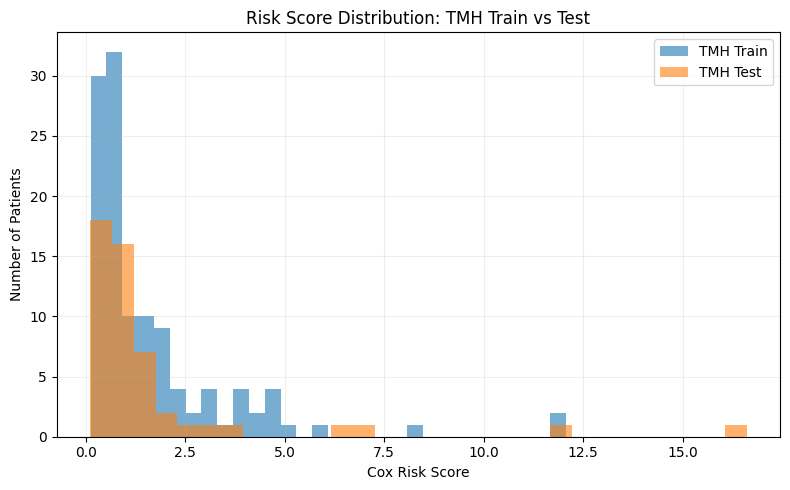

In [682]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8, 5))

plt.hist(
    train_model["risk_score"],
    bins=30,
    alpha=0.6,
    label="TMH Train"
)

plt.hist(
    test_model["risk_score"],
    bins=30,
    alpha=0.6,
    label="TMH Test"
)

plt.xlabel("Cox Risk Score")
plt.ylabel("Number of Patients")
plt.title("Risk Score Distribution: TMH Train vs Test")
plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [679]:
train_model

,H0_proportion,H0_volume_mm3,H1_proportion,H1_volume_mm3,H2_proportion,H2_volume_mm3,H3_volume_mm3,H4_proportion,H4_volume_mm3,H5_proportion,...,H7_components,H7_largest_component_fraction,H8_components,H8_largest_component_fraction,transition_entropy,boundary_faces,boundary_density,valid_volume_mm3,time,event
0,0.256343,0.376779,-0.173939,0.778281,0.172330,1.270398,0.172875,-0.447635,-0.289407,0.229581,...,-0.293076,-0.365380,-0.611832,0.698077,0.727108,0.658147,0.749384,0.521734,7.982917,0
1,1.051765,-0.394609,-0.062002,-0.710846,-0.815345,-1.013425,-0.489039,0.110257,-0.400371,-0.561713,...,-0.435260,3.368372,-0.650683,0.868666,-0.159926,-0.723871,-0.471113,-0.684898,33.278581,0
2,1.593177,1.963980,-0.500605,1.451781,-0.683304,1.153923,1.186613,-0.575425,-0.221212,-0.522860,...,0.054483,-0.253662,0.378887,-1.176744,-0.219561,1.216284,-1.086704,1.378127,3.022339,0
3,0.919793,1.584170,-0.930955,0.994706,-0.964704,0.773285,1.347937,1.282886,1.610185,-0.572977,...,-0.443159,-0.738755,1.019941,0.059333,0.251369,1.419150,-0.538406,1.470518,20.959264,0
4,1.095891,1.185123,-0.286473,1.176740,-0.686451,0.693407,0.848159,-0.314524,-0.092308,-0.429322,...,0.765401,-0.559666,0.262332,0.993032,0.182310,0.874589,-0.578951,0.930798,1.018397,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112,1.663482,1.595087,-0.494861,1.032648,-0.776295,0.636630,0.667154,-0.614056,-0.320811,-0.358864,...,-0.285177,-0.054234,0.145777,0.482880,0.119859,0.928214,-0.669105,1.000764,1.149803,1
113,0.032155,-0.763686,1.304686,-0.629062,0.533477,-0.744202,-0.912966,-0.963910,-0.711949,-0.408011,...,-0.443159,-0.738755,-0.728387,-0.211979,-1.583701,-0.962754,-0.807408,-0.908791,3.679369,0
114,0.301100,0.379744,0.002354,0.903426,-0.258498,0.741685,0.143634,-0.076285,-0.049036,-0.061661,...,0.504731,-0.061756,1.874679,-1.124283,0.981008,0.547106,0.148808,0.497597,11.070959,1
115,0.465101,0.501896,0.234836,1.184127,-0.529551,0.489397,0.421983,0.008194,0.026051,-0.458922,...,-0.032406,-0.196305,0.009796,-1.092695,0.116407,0.578073,-0.012656,0.549686,28.515112,1


In [ ]:
### risk habitat map plot 

In [847]:
coef_table = final_cox.summary[
    ["coef", "exp(coef)", "p"]
].sort_values(
    "coef",
    ascending=False
)

print(coef_table)

                                   coef  exp(coef)         p
covariate                                                   
H7_volume_mm3                  1.146320   3.146593  0.078862
H6_components                  0.967697   2.631876  0.052846
H8_volume_mm3                  0.851124   2.342279  0.175500
H1_components                  0.845613   2.329405  0.083164
H4_largest_component_fraction  0.709454   2.032882  0.015265
H2_largest_component_fraction  0.591952   1.807513  0.247887
H0_volume_mm3                  0.582558   1.790613  0.628527
transition_entropy             0.535460   1.708233  0.544034
occupied_habitats              0.527217   1.694212  0.219464
H4_proportion                  0.454288   1.575052  0.555835
H1_volume_mm3                  0.443859   1.558711  0.521700
H6_proportion                  0.367051   1.443472  0.329753
H5_components                  0.355439   1.426807  0.444428
H4_components                  0.338476   1.402807  0.569799
boundary_density        

In [683]:
coef_table = final_cox.summary[
    ["coef", "exp(coef)", "p"]
].sort_values(
    "coef",
    ascending=False
)

print(coef_table)

                                   coef  exp(coef)         p
covariate                                                   
H7_volume_mm3                  1.146320   3.146593  0.078862
H6_components                  0.967697   2.631876  0.052846
H8_volume_mm3                  0.851124   2.342279  0.175500
H1_components                  0.845613   2.329405  0.083164
H4_largest_component_fraction  0.709454   2.032882  0.015265
H2_largest_component_fraction  0.591952   1.807513  0.247887
H0_volume_mm3                  0.582558   1.790613  0.628527
transition_entropy             0.535460   1.708233  0.544034
occupied_habitats              0.527217   1.694212  0.219464
H4_proportion                  0.454288   1.575052  0.555835
H1_volume_mm3                  0.443859   1.558711  0.521700
H6_proportion                  0.367051   1.443472  0.329753
H5_components                  0.355439   1.426807  0.444428
H4_components                  0.338476   1.402807  0.569799
boundary_density        

#### univariate cox of the habitats

In [804]:
from lifelines import CoxPHFitter
import pandas as pd
import numpy as np

time_col = "time"
event_col = "event"

# All candidate habitat/spatial features
exclude = [
    "patient_id",
    time_col,
    event_col
]

feature_cols = [
    c for c in train_df.columns
    if c not in exclude
]

univ_results = []

for feature in feature_cols:

    df = train_df[
        [time_col, event_col, feature]
    ].dropna()

    # Skip constant features
    if df[feature].nunique() <= 1:
        continue

    try:
        cph = CoxPHFitter()

        cph.fit(
            df,
            duration_col=time_col,
            event_col=event_col
        )

        row = cph.summary.loc[feature]

        univ_results.append({
            "feature": feature,
            "HR": row["exp(coef)"],
            "coef": row["coef"],
            "p": row["p"],
            "CI_low": row["exp(coef) lower 95%"],
            "CI_high": row["exp(coef) upper 95%"]
        })

    except Exception as e:
        print(f"Failed: {feature} -> {e}")

# Results table
univ_results = pd.DataFrame(
    univ_results
).sort_values("p")

print("=== UNIVARIATE COX RESULTS ===")
print(
    univ_results.to_string(
        index=False
    )
)

# --------------------------------------------------
# Select p < 0.15
# --------------------------------------------------

selected_features = univ_results.loc[
    univ_results["p"] <= 0.5,
    "feature"
].tolist()

print("\n=== SELECTED FEATURES (p < 0.15) ===")
for f in selected_features:
    print(f)

print(
    f"\nNumber selected: {len(selected_features)}"
)

/usr/local/lib/python3.12/dist-packages/lifelines/utils/__init__.py:1100: ConvergenceWarning: Column(s) ['H6_proportion'] have very low variance. This may harm convergence. 1) Are you using formula's? Did you mean to add '-1' to the end. 2) Try dropping this redundant column before fitting if convergence fails.

  warnings.warn(dedent(warning_text), ConvergenceWarning)
/usr/local/lib/python3.12/dist-packages/lifelines/utils/__init__.py:1100: ConvergenceWarning: Column(s) ['H7_proportion'] have very low variance. This may harm convergence. 1) Are you using formula's? Did you mean to add '-1' to the end. 2) Try dropping this redundant column before fitting if convergence fails.

  warnings.warn(dedent(warning_text), ConvergenceWarning)


=== UNIVARIATE COX RESULTS ===
                      feature           HR          coef        p       CI_low       CI_high
                H6_components 1.003502e+00  3.495714e-03 0.063622 9.998019e-01  1.007216e+00
                H4_components 1.000395e+00  3.947275e-04 0.108555 9.999126e-01  1.000877e+00
                H7_volume_mm3 1.000026e+00  2.573433e-05 0.124495 9.999929e-01  1.000059e+00
                H7_components 1.001370e+00  1.368843e-03 0.132179 9.995869e-01  1.003156e+00
                H2_proportion 1.087740e-01 -2.218483e+00 0.174733 4.416702e-03  2.678871e+00
           transition_entropy 1.724246e+00  5.447898e-01 0.179570 7.781649e-01  3.820558e+00
H4_largest_component_fraction 2.383601e+00  8.686124e-01 0.209875 6.131781e-01  9.265749e+00
                H7_proportion 3.261054e+06  1.499756e+01 0.220064 1.269758e-04  8.375197e+16
                H6_proportion 3.424614e+40  9.333439e+01 0.229222 2.880921e-26 4.070913e+106
                H5_components 1.000476e

/usr/local/lib/python3.12/dist-packages/lifelines/utils/__init__.py:1100: ConvergenceWarning: Column(s) ['boundary_density'] have very low variance. This may harm convergence. 1) Are you using formula's? Did you mean to add '-1' to the end. 2) Try dropping this redundant column before fitting if convergence fails.

  warnings.warn(dedent(warning_text), ConvergenceWarning)


In [806]:
X_train_selected = train_df[
    selected_features
]

print("Selected feature matrix:",
      X_train_selected.shape)

Selected feature matrix: (117, 19)


In [807]:
X_train_selected.columns

Index(['H6_components', 'H4_components', 'H7_volume_mm3', 'H7_components',
       'H2_proportion', 'transition_entropy', 'H4_largest_component_fraction',
       'H7_proportion', 'H6_proportion', 'H5_components', 'H3_proportion',
       'H7_largest_component_fraction', 'H4_proportion', 'H6_volume_mm3',
       'H2_largest_component_fraction', 'H6_largest_component_fraction',
       'H5_proportion', 'habitat_entropy', 'H8_volume_mm3'],
      dtype='object')

In [808]:
train_model.columns

Index(['H0_proportion', 'H0_volume_mm3', 'H1_proportion', 'H1_volume_mm3',
       'H2_proportion', 'H2_volume_mm3', 'H3_volume_mm3', 'H4_proportion',
       'H4_volume_mm3', 'H5_proportion', 'H5_volume_mm3', 'H6_proportion',
       'H6_volume_mm3', 'H7_proportion', 'H7_volume_mm3', 'H8_proportion',
       'H8_volume_mm3', 'habitat_entropy', 'occupied_habitats',
       'H0_components', 'H0_largest_component_fraction', 'H1_components',
       'H1_largest_component_fraction', 'H2_components',
       'H2_largest_component_fraction', 'H3_components',
       'H3_largest_component_fraction', 'H4_components',
       'H4_largest_component_fraction', 'H5_components',
       'H5_largest_component_fraction', 'H6_components',
       'H6_largest_component_fraction', 'H7_components',
       'H7_largest_component_fraction', 'H8_components',
       'H8_largest_component_fraction', 'transition_entropy', 'boundary_faces',
       'boundary_density', 'valid_volume_mm3', 'time', 'event', 'risk_score'],
    

In [809]:
train_model.head()

,H0_proportion,H0_volume_mm3,H1_proportion,H1_volume_mm3,H2_proportion,H2_volume_mm3,H3_volume_mm3,H4_proportion,H4_volume_mm3,H5_proportion,...,H7_largest_component_fraction,H8_components,H8_largest_component_fraction,transition_entropy,boundary_faces,boundary_density,valid_volume_mm3,time,event,risk_score
0,0.256343,0.376779,-0.173939,0.778281,0.172330,1.270398,0.172875,-0.447635,-0.289407,0.229581,...,-0.365380,-0.611832,0.698077,0.727108,0.658147,0.749384,0.521734,7.982917,0,0.381472
1,1.051765,-0.394609,-0.062002,-0.710846,-0.815345,-1.013425,-0.489039,0.110257,-0.400371,-0.561713,...,3.368372,-0.650683,0.868666,-0.159926,-0.723871,-0.471113,-0.684898,33.278581,0,0.191895
2,1.593177,1.963980,-0.500605,1.451781,-0.683304,1.153923,1.186613,-0.575425,-0.221212,-0.522860,...,-0.253662,0.378887,-1.176744,-0.219561,1.216284,-1.086704,1.378127,3.022339,0,1.324364
3,0.919793,1.584170,-0.930955,0.994706,-0.964704,0.773285,1.347937,1.282886,1.610185,-0.572977,...,-0.738755,1.019941,0.059333,0.251369,1.419150,-0.538406,1.470518,20.959264,0,0.666916
4,1.095891,1.185123,-0.286473,1.176740,-0.686451,0.693407,0.848159,-0.314524,-0.092308,-0.429322,...,-0.559666,0.262332,0.993032,0.182310,0.874589,-0.578951,0.930798,1.018397,1,4.075554


In [816]:
train_model.columns

Index(['H0_proportion', 'H0_volume_mm3', 'H1_proportion', 'H1_volume_mm3',
       'H2_proportion', 'H2_volume_mm3', 'H3_volume_mm3', 'H4_proportion',
       'H4_volume_mm3', 'H5_proportion', 'H5_volume_mm3', 'H6_proportion',
       'H6_volume_mm3', 'H7_proportion', 'H7_volume_mm3', 'H8_proportion',
       'H8_volume_mm3', 'habitat_entropy', 'occupied_habitats',
       'H0_components', 'H0_largest_component_fraction', 'H1_components',
       'H1_largest_component_fraction', 'H2_components',
       'H2_largest_component_fraction', 'H3_components',
       'H3_largest_component_fraction', 'H4_components',
       'H4_largest_component_fraction', 'H5_components',
       'H5_largest_component_fraction', 'H6_components',
       'H6_largest_component_fraction', 'H7_components',
       'H7_largest_component_fraction', 'H8_components',
       'H8_largest_component_fraction', 'transition_entropy', 'boundary_faces',
       'boundary_density', 'valid_volume_mm3', 'time', 'event', 'risk_score'],
    

In [814]:
X_train_selected.columns.tolist()

['H6_components',
 'H4_components',
 'H7_volume_mm3',
 'H7_components',
 'H2_proportion',
 'transition_entropy',
 'H4_largest_component_fraction',
 'H7_proportion',
 'H6_proportion',
 'H5_components',
 'H3_proportion',
 'H7_largest_component_fraction',
 'H4_proportion',
 'H6_volume_mm3',
 'H2_largest_component_fraction',
 'H6_largest_component_fraction',
 'H5_proportion',
 'habitat_entropy',
 'H8_volume_mm3']

In [812]:
train_model[X_train_selected.columns.tolist()]

KeyError: "['H3_proportion'] not in index"

In [810]:
gb_uniselected_surv=train_model[X_train_selected.columns.tolist() + ['time', 'event']]


KeyError: "['H3_proportion'] not in index"

In [782]:
from lifelines import CoxPHFitter
from lifelines.utils import k_fold_cross_validation

penalties = [
    0.001,
    0.003,
    0.01,
    0.03,
    0.05,
    0.1,
    0.3,
    0.5,
    0.8,
    1.0
]

results_final = []

for penalty in penalties:

    cph = CoxPHFitter(
        penalizer=penalty,
        l1_ratio=1.0
    )

    scores = k_fold_cross_validation(
        cph,
        gb_uniselected_surv,
        duration_col=time_col,
        event_col=event_col,
        k=5,
        scoring_method="concordance_index"
    )

    results_final.append({
        "penalty": penalty,
        "cindex_mean": np.mean(scores)
    })

results_df_final = pd.DataFrame(results_final)

print(results_df_final)

   penalty  cindex_mean
0    0.001     0.466841
1    0.003     0.470565
2    0.010     0.543657
3    0.030     0.429304
4    0.050     0.544465
5    0.100     0.522261
6    0.300     0.554324
7    0.500     0.577075
8    0.800     0.567508
9    1.000     0.565787


In [888]:
# Assuming your DataFrame is named df
results_df_final_sorted = results_df_final.sort_values(by='cindex_mean', ascending=False)


df_sorted = results_df_final_sorted.sort_values(by='cindex_mean', ascending=False).reset_index(drop=True)


df_sorted.iloc[0:,0][0]

# final cox model
best_penalty_uni = df_sorted.iloc[0:,0][0]

final_cox_uni = CoxPHFitter(
    penalizer=best_penalty_uni,
    l1_ratio=1.0
)

final_cox_uni.fit(
    gb_uniselected_surv,
    duration_col=time_col,
    event_col=event_col
)

print('best penalty:', best_penalty_uni)
print('train c-index',final_cox_uni.concordance_index_)


best penalty: 0.5
train c-index 0.5782738095238096


In [752]:
train_model

,H0_proportion,H0_volume_mm3,H1_proportion,H1_volume_mm3,H2_proportion,H2_volume_mm3,H3_volume_mm3,H4_proportion,H4_volume_mm3,H5_proportion,...,H7_largest_component_fraction,H8_components,H8_largest_component_fraction,transition_entropy,boundary_faces,boundary_density,valid_volume_mm3,time,event,risk_score
0,0.256343,0.376779,-0.173939,0.778281,0.172330,1.270398,0.172875,-0.447635,-0.289407,0.229581,...,-0.365380,-0.611832,0.698077,0.727108,0.658147,0.749384,0.521734,7.982917,0,0.381472
1,1.051765,-0.394609,-0.062002,-0.710846,-0.815345,-1.013425,-0.489039,0.110257,-0.400371,-0.561713,...,3.368372,-0.650683,0.868666,-0.159926,-0.723871,-0.471113,-0.684898,33.278581,0,0.191895
2,1.593177,1.963980,-0.500605,1.451781,-0.683304,1.153923,1.186613,-0.575425,-0.221212,-0.522860,...,-0.253662,0.378887,-1.176744,-0.219561,1.216284,-1.086704,1.378127,3.022339,0,1.324364
3,0.919793,1.584170,-0.930955,0.994706,-0.964704,0.773285,1.347937,1.282886,1.610185,-0.572977,...,-0.738755,1.019941,0.059333,0.251369,1.419150,-0.538406,1.470518,20.959264,0,0.666916
4,1.095891,1.185123,-0.286473,1.176740,-0.686451,0.693407,0.848159,-0.314524,-0.092308,-0.429322,...,-0.559666,0.262332,0.993032,0.182310,0.874589,-0.578951,0.930798,1.018397,1,4.075554
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112,1.663482,1.595087,-0.494861,1.032648,-0.776295,0.636630,0.667154,-0.614056,-0.320811,-0.358864,...,-0.054234,0.145777,0.482880,0.119859,0.928214,-0.669105,1.000764,1.149803,1,11.958916
113,0.032155,-0.763686,1.304686,-0.629062,0.533477,-0.744202,-0.912966,-0.963910,-0.711949,-0.408011,...,-0.738755,-0.728387,-0.211979,-1.583701,-0.962754,-0.807408,-0.908791,3.679369,0,0.491360
114,0.301100,0.379744,0.002354,0.903426,-0.258498,0.741685,0.143634,-0.076285,-0.049036,-0.061661,...,-0.061756,1.874679,-1.124283,0.981008,0.547106,0.148808,0.497597,11.070959,1,1.842818
115,0.465101,0.501896,0.234836,1.184127,-0.529551,0.489397,0.421983,0.008194,0.026051,-0.458922,...,-0.196305,0.009796,-1.092695,0.116407,0.578073,-0.012656,0.549686,28.515112,1,1.787399


In [744]:
test_model.head(2)

,H0_proportion,H0_volume_mm3,H1_proportion,H1_volume_mm3,H2_proportion,H2_volume_mm3,H3_volume_mm3,H4_proportion,H4_volume_mm3,H5_proportion,...,H7_largest_component_fraction,H8_components,H8_largest_component_fraction,transition_entropy,boundary_faces,boundary_density,valid_volume_mm3,time,event,risk_score
0,-1.38219,-0.876301,0.849763,-0.308261,1.757204,0.314003,-0.794316,-0.767715,-0.640879,0.350374,...,-0.738755,-0.456425,0.295413,-0.449986,-0.601213,0.910436,-0.648051,4.237845,0,0.62994
1,1.15063,1.775822,-0.905063,1.054521,-1.054729,0.643573,1.949807,0.417633,0.778885,-0.386184,...,-0.028882,-0.650683,-0.432248,0.440300,1.715459,0.740323,1.497861,5.059133,0,6.47177


In [889]:
gb_uniselected_surv_test=test_model[X_train_selected.columns.tolist() + ['time', 'event']]

from lifelines.utils import concordance_index

test_cindex_uni_surv = concordance_index(
    gb_uniselected_surv_test[time_col],
    gb_uniselected_surv_test[event_col]
)

print("TMH TEST C-index:", test_cindex_uni_surv)

KeyError: "['H3_proportion'] not in index"

In [899]:
# Use the score method directly on your trained model
test_cindex_uni_surv = final_cox_uni.score(
    gb_uniselected_surv_test, 
    scoring_method="concordance_index"
)

print("TMH TEST C-index:", test_cindex_uni_surv)


TMH TEST C-index: 0.5067264573991032


In [900]:
coef = final_cox.params_

selected = coef[
    np.abs(coef) > 1e-8
].sort_values(ascending=False)

print(selected)

covariate
H7_volume_mm3                    1.146320
H6_components                    0.967697
H8_volume_mm3                    0.851124
H1_components                    0.845613
H4_largest_component_fraction    0.709454
H2_largest_component_fraction    0.591952
H0_volume_mm3                    0.582558
transition_entropy               0.535460
occupied_habitats                0.527217
H4_proportion                    0.454288
H1_volume_mm3                    0.443859
H6_proportion                    0.367051
H5_components                    0.355439
H4_components                    0.338476
boundary_density                 0.186274
H5_largest_component_fraction    0.066363
H8_largest_component_fraction    0.065754
H0_proportion                    0.053235
H2_proportion                    0.000005
boundary_faces                   0.000003
valid_volume_mm3                 0.000003
H4_volume_mm3                    0.000002
H1_largest_component_fraction    0.000001
H7_proportion           

In [ ]:
# old

covariate
H7_volume_mm3                    1.146320
H6_components                    0.967697
H8_volume_mm3                    0.851124
H1_components                    0.845613
H4_largest_component_fraction    0.709454
H2_largest_component_fraction    0.591952
H0_volume_mm3                    0.582558
transition_entropy               0.535460
occupied_habitats                0.527217
H4_proportion                    0.454288
H1_volume_mm3                    0.443859
H6_proportion                    0.367051
H5_components                    0.355439
H4_components                    0.338476
boundary_density                 0.186274
H5_largest_component_fraction    0.066363
H8_largest_component_fraction    0.065754
H0_proportion                    0.053235
H2_proportion                    0.000005
boundary_faces                   0.000003
valid_volume_mm3                 0.000003
H4_volume_mm3                    0.000002
H1_largest_component_fraction    0.000001
H7_proportion           

In [901]:
high_risk_habitats = []
low_risk_habitats = []

for feature, coef_value in selected.items():

    if feature.endswith("_proportion"):

        h = int(
            feature.replace("H", "")
                   .replace("_proportion", "")
        )

        if coef_value > 0:
            high_risk_habitats.append(h)

        elif coef_value < 0:
            low_risk_habitats.append(h)

print("High-risk habitats:", high_risk_habitats)
print("Low-risk habitats :", low_risk_habitats)

High-risk habitats: [4, 6, 0, 2]
Low-risk habitats : [7, 5, 1, 8]


In [689]:
### Create the risk map



high_mask = np.isin(
    habitat_ct,
    high_risk_habitats
)

low_mask = np.isin(
    habitat_ct,
    low_risk_habitats
)

# Only valid radiomics region
high_mask &= valid_ct
low_mask &= valid_ct

In [692]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch


# ============================================================
# Keep only valid radiomics voxels
# ============================================================

high_mask = high_mask & valid_ct
low_mask  = low_mask & valid_ct


# ============================================================
# Create a single risk map
#
# 0 = background / no risk assignment
# 1 = low-risk habitat
# 2 = high-risk habitat
# ============================================================

risk_map = np.zeros_like(
    habitat_ct,
    dtype=np.int8
)

risk_map[low_mask] = 1
risk_map[high_mask] = 2


# ============================================================
# Strong categorical colors
# ============================================================

risk_cmap = ListedColormap([
    (0, 0, 0, 0),          # transparent
    (0.0, 0.25, 1.0, 0.90),# blue = low risk
    (1.0, 0.0, 0.0, 0.90)  # red = high risk
])

risk_norm = BoundaryNorm(
    [-0.5, 0.5, 1.5, 2.5],
    risk_cmap.N
)


# ============================================================
# CT window
# ============================================================

def window_ct(slice_img, low=-200, high=200):

    x = np.clip(
        slice_img,
        low,
        high
    )

    x = (
        x - x.min()
    ) / (
        x.max() - x.min() + 1e-8
    )

    return x


# ============================================================
# Interactive slice viewer
# ============================================================

def show_risk_slice(z):

    z = int(z)

    # --------------------------------------------------------
    # CT
    # --------------------------------------------------------

    ct_display = window_ct(
        ct[z]
    )

    # --------------------------------------------------------
    # Risk slice
    # 0 is masked -> transparent
    # --------------------------------------------------------

    risk_slice = np.ma.masked_where(
        risk_map[z] == 0,
        risk_map[z]
    )

    # --------------------------------------------------------
    # Figure
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(8, 8)
    )

    # CT background
    ax.imshow(
        ct_display,
        cmap="gray",
        interpolation="nearest"
    )

    # Risk overlay
    ax.imshow(
        risk_slice,
        cmap=risk_cmap,
        norm=risk_norm,
        interpolation="nearest"
    )

    # --------------------------------------------------------
    # Original tumor boundary
    # --------------------------------------------------------

    ax.contour(
        tumor[z] > 0,
        colors="lime",
        linewidths=2.5
    )

    # --------------------------------------------------------
    # Radiomics region
    # --------------------------------------------------------

    ax.contour(
        valid_ct[z],
        colors="yellow",
        linewidths=1.2,
        linestyles="--"
    )

    # --------------------------------------------------------
    # Title
    # --------------------------------------------------------

    ax.set_title(
        f"CT + Risk-associated SOM Habitats | Slice {z}",
        fontsize=14
    )

    ax.axis("off")

    # --------------------------------------------------------
    # Legend
    # --------------------------------------------------------

    legend_elements = [

        Patch(
            facecolor="blue",
            alpha=0.90,
            label="Low-risk habitat"
        ),

        Patch(
            facecolor="red",
            alpha=0.90,
            label="High-risk habitat"
        ),

        Patch(
            facecolor="none",
            edgecolor="lime",
            linewidth=2,
            label="Tumor"
        ),

        Patch(
            facecolor="none",
            edgecolor="yellow",
            linewidth=1.2,
            linestyle="--",
            label="Radiomics region"
        )
    ]

    ax.legend(
        handles=legend_elements,
        loc="lower right",
        framealpha=0.9
    )

    plt.tight_layout()
    plt.show()


# ============================================================
# Start at tumor-centered slice
# ============================================================

z0 = int(
    np.median(
        np.where(tumor > 0)[0]
    )
)


# ============================================================
# Slider
# ============================================================

slice_slider = widgets.IntSlider(
    value=z0,
    min=0,
    max=ct.shape[0] - 1,
    step=1,
    description="Slice:",
    continuous_update=True,
    readout=True,
    layout=widgets.Layout(
        width="600px"
    )
)


widgets.interact(
    show_risk_slice,
    z=slice_slider
);

interactive(children=(IntSlider(value=57, description='Slice:', layout=Layout(width='600px'), max=83), Output(…

In [ ]:
########################################################################################        gb end #####################################################################################

In [660]:
final_cox.concordance_index_

0.7494047619047619

In [661]:
from lifelines.utils import concordance_index

test_cindex = concordance_index(
    test_model[time_col],
    -test_model["risk_score"],
    test_model[event_col]
)

print("TMH TEST C-index:", test_cindex)

KeyError: 'risk_score'

In [ ]:
########################################################################################################## gb_end ###############################################################

In [ ]:
Reproducibility

Bootstrap:

50 runs

Compute:

ARI
NMI
Dice

Cross cohort:

Train TMH SOM.

Apply:

LUNG1

Train LUNG1 SOM.

Apply:

TMH

Metrics:

adjusted_rand_score

normalized_mutual_info_score
FIGURE

Transfer matrix.

STEP 12 — Survival

Train:

TMH train

Validate:

TMH test

External:

LUNG1 test

Repeat opposite direction.

ElasticNet Cox
CoxPHFitter(

penalizer=0.1,
l1_ratio=0.5
)
RSF
RandomSurvivalForest
Time-dependent AUC
pip install scikit-survival
from sksurv.metrics import cumulative_dynamic_auc

Evaluate:

1 year
2 year
3 year
5 year
FIGURE
Time
vs
AUC
Kaplan-Meier
median split

and

tertiles
FIGURE

KM curves.

STEP 13 — Voxel Risk Maps

After Cox:

beta_i

Assign:

risk_map = beta[cluster]

Overlay.

plt.imshow(ct)

plt.imshow(
risk_map,
alpha=.5
)